# Исследование интернет-магазина «Подарочек»

**Заказчик:** интернет-магазин подарков, который продаёт товары и оптовым, и розничным покупателям и часто отправляет заказы по почте.

**Цель исследования:** понять, как покупают клиенты магазина, разделить их на группы и дать бизнесу понятные рекомендации — с кем и как работать, чтобы выручка росла.

**Задачи:**
1. Загрузить и объединить данные, найти и исправить ошибки в них.
2. Найти выбросы, отбросить служебные и ошибочные записи, выбрать период, за который данные полные.
3. Посчитать ключевые метрики: активность по часам и дням недели, выручку на клиента по месяцам, «липкость» (sticky factor), профили клиентов; сравнить возвратных и разовых покупателей.
4. Провести RFM-сегментацию и сформулировать рекомендации по каждому сегменту.
5. Проверить статистические гипотезы.
6. Сделать общий вывод.
7. (Дополнительно) Найти товары, которые чаще всего покупают вместе.

**Данные:**
- `gift.csv` — записи о продажах: дата записи `entry_date`, номер заказа `order_id`, номер клиента `customer_id`, количество `quantity`, цена `price`, группа товара по названию `name_clust`, номер записи (товара) `entry_id`, номер страны `country_id`;
- справочник записей — `entry_id` и текстовое описание `entry`.

> **Как читать отчёт.** Каждый раздел заканчивается блоком «Вывод» простым языком. Числа в выводах рассчитываются кодом прямо из данных, поэтому они всегда совпадают с таблицами и графиками.

## Подготовка: библиотеки и настройки

In [1]:
import os
import glob
import itertools
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import Patch
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}'.replace(',', ' '))

sns.set_theme(style='whitegrid', font_scale=1.0)
plt.rcParams.update({
    'figure.figsize': (12, 5),
    'axes.titlesize': 14,
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

MAIN, ACCENT, GREY, GOOD, BAD = '#2E6F9E', '#E07A3F', '#9AA5B1', '#3A9D5D', '#C8553D'
ALPHA = 0.05          # уровень значимости для всех тестов
RANDOM_STATE = 42
UNKNOWN_ID = -1      # так в данных помечен неизвестный покупатель

MONTHS_RU = ['янв', 'фев', 'мар', 'апр', 'май', 'июн', 'июл', 'авг', 'сен', 'окт', 'ноя', 'дек']
WEEKDAYS_RU = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']

S = {}  # ключевые результаты для итогового вывода

In [2]:
def md(text):
    """Выводит текст как Markdown (используется для выводов, рассчитанных из данных)."""
    display(Markdown(text))


def num(x, d=0):
    """Число с пробелом в качестве разделителя разрядов."""
    return f'{x:,.{d}f}'.replace(',', ' ')


def pct(x, d=1):
    return f'{x * 100:.{d}f}%'


def pv(p):
    """Форматирует p-value."""
    return '< 0.0001' if p < 1e-4 else f'{p:.4f}'


def month_label(period):
    return f'{MONTHS_RU[period.month - 1]} {period.year}'


def thousands(ax, axis='y'):
    fmt = mtick.FuncFormatter(lambda x, _: f'{x:,.0f}'.replace(',', ' '))
    target = ax.yaxis if axis == 'y' else ax.xaxis
    target.set_major_formatter(fmt)
    target.set_major_locator(mtick.MaxNLocator(5))


def annotate_bars(ax, fmt='{:,.0f}', horizontal=False, fontsize=9):
    """Подписывает значения над (или справа от) столбцами."""
    for p in ax.patches:
        v = p.get_width() if horizontal else p.get_height()
        if v is None or np.isnan(v) or v == 0:
            continue
        label = fmt.format(v).replace(',', ' ')
        if horizontal:
            ax.annotate(label, (v, p.get_y() + p.get_height() / 2), xytext=(3, 0),
                        textcoords='offset points', va='center', fontsize=fontsize)
        else:
            ax.annotate(label, (p.get_x() + p.get_width() / 2, v), xytext=(0, 3),
                        textcoords='offset points', ha='center', va='bottom', fontsize=fontsize)


def short(text, n=35):
    text = str(text)
    return text if len(text) <= n else text[:n - 1] + '…'

<div class="alert alert-success">
<b>✔️ Комментарий ревьюера v1:</b>
<br>
Во введении цель исследования связана с задачами магазина, а план охватывает подготовку данных, метрики, сегментацию и проверку гипотез. Это помогает понимать назначение каждого раздела и связывать расчёты с будущими рекомендациями.
</div>

## Шаг 1. Получение, осмотр и объединение данных

### 1.1. Загрузка

Данные — два файла: `gift.csv` (продажи) и `gift_entry.csv` (справочник с описаниями записей). Файлы читаются из `/datasets/`, а если такой папки нет — из папки с тетрадкой.

В справочнике разделитель — не запятая, а сами описания товаров содержат запятые, поэтому стандартный `read_csv` на нём падает. Справочник читаем построчно: разделитель определяем по заголовку и делим каждую строку только по первому разделителю — так текст описания сохраняется целиком.

In [3]:
def read_dataset(name):
    """Путь к файлу: /datasets/, а если его там нет — папка с тетрадкой."""
    path = os.path.join('/datasets', name)
    return path if os.path.exists(path) else name


def read_entries(path):
    """Читает справочник построчно: разделитель берётся из заголовка, строка делится только по первому
    разделителю, поэтому запятые и точки с запятой внутри описания не ломают чтение."""
    with open(path, encoding='utf-8-sig') as f:
        lines = [line.rstrip('\r\n') for line in f if line.strip()]
    header = lines[0]
    sep = max(['\t', ';', '|', ','], key=header.count)
    if header.count(sep) == 0:
        sep = ' '
    cols = [c.strip().strip('"').strip().lower() for c in header.split(sep)]
    n = len(cols)
    split = (lambda s: s.rsplit(sep, n - 1)) if cols[0] == 'entry' else (lambda s: s.split(sep, n - 1))
    rows = []
    for line in lines[1:]:
        parts = [p.strip() for p in split(line)]
        parts = [p[1:-1].replace('""', '"') if len(p) > 1 and p[0] == p[-1] == '"' else p for p in parts]
        rows.append(parts + [None] * (n - len(parts)))
    return pd.DataFrame(rows, columns=cols)


gift_path, entry_path = read_dataset('gift.csv'), read_dataset('gift_entry.csv')

gift_raw = pd.read_csv(gift_path, dtype={'order_id': str, 'entry_date': str})
gift_raw.columns = gift_raw.columns.str.strip().str.lower()
entries_raw = read_entries(entry_path)

print(f'{gift_path}: {gift_raw.shape[0]:,} строк × {gift_raw.shape[1]} столбцов'.replace(',', ' '))
print(f'{entry_path}: {entries_raw.shape[0]:,} строк × {entries_raw.shape[1]} столбцов'.replace(',', ' '))

gift.csv: 356 940 строк × 8 столбцов
gift_entry.csv: 2 917 строк × 2 столбцов


### 1.2. Общая информация о таблицах

In [4]:
print('Основной датасет (продажи)')
display(gift_raw.head())
gift_raw.info()

Основной датасет (продажи)


,entry_date,order_id,customer_id,quantity,price,name_clust,entry_id,country_id
0,12/01/2018 08:26,3031,2150,6,339,740,891,28
1,12/01/2018 08:26,3031,2150,8,275,132,1596,28
2,12/01/2018 08:26,3031,2150,6,339,197,166,28
3,12/01/2018 08:26,3031,2150,2,765,767,1810,28
4,12/01/2018 08:26,3031,2150,6,425,383,2585,28


<class 'pandas.DataFrame'>
RangeIndex: 356940 entries, 0 to 356939
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype
---  ------       --------------   -----
 0   entry_date   356940 non-null  str  
 1   order_id     356940 non-null  str  
 2   customer_id  356940 non-null  int64
 3   quantity     356940 non-null  int64
 4   price        356940 non-null  int64
 5   name_clust   356940 non-null  int64
 6   entry_id     356940 non-null  int64
 7   country_id   356940 non-null  int64
dtypes: int64(6), str(2)
memory usage: 21.8 MB


In [5]:
display(gift_raw.describe(include='all').T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
entry_date,356940,18794,31/10/2019 14:41,770,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_id,356940,20616,40251,770,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,356 940.00,NaN,NaN,NaN,3 486.88,2 542.88,-1.00,-1.00,3 633.00,5 627.50,7 653.00
quantity,356 940.00,NaN,NaN,NaN,10.15,146.79,-9 600.00,1.00,3.00,10.00,80 995.00
price,356 940.00,NaN,NaN,NaN,399.99,5 059.18,-1 106 206.00,125.00,208.00,413.00,1 354 133.00
name_clust,356 940.00,NaN,NaN,NaN,468.62,259.15,0.00,242.00,448.00,702.00,929.00
entry_id,356 940.00,NaN,NaN,NaN,1 518.05,833.75,0.00,875.00,1 559.00,2 223.00,2 916.00
country_id,356 940.00,NaN,NaN,NaN,26.75,4.98,0.00,28.00,28.00,28.00,29.00


In [6]:
print('Справочник записей')
display(entries_raw.head())
entries_raw.info()
print('\nУникальных entry_id в справочнике:', entries_raw['entry_id'].nunique(), 'при', len(entries_raw), 'строках')

Справочник записей


,entry_id,entry
0,0,
1,1,10-цветная ручка Spaceboy
2,2,"12 карандашей, черепа"
3,3,"12 карандашей, высокий тюбик, лесной массив"
4,4,"12 карандашей, маленький тюбик с черепом"


<class 'pandas.DataFrame'>
RangeIndex: 2917 entries, 0 to 2916
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   entry_id  2917 non-null   str  
 1   entry     2917 non-null   str  
dtypes: str(2)
memory usage: 45.7 KB

Уникальных entry_id в справочнике: 2917 при 2917 строках


<div class="alert alert-success">
<b>✔️ Комментарий ревьюера v1:</b>
<br>
Оба источника рассмотрены до преобразований: показаны примеры, структура и описательная статистика. Проверка уникальности ключа справочника особенно полезна, поскольку повторяющиеся идентификаторы могли бы размножить продажи при объединении.
</div>


### 1.3. Приведение типов

Прежде чем искать пропуски и дубликаты, приведём столбцы к правильным типам — иначе часть ошибок (например, «битые» даты или цены с запятой) останется незамеченной:

- `entry_date` → дата и время. Дата записана строкой вида `ЧЧ/ЧЧ/ГГГГ ЧЧ:ММ`. Порядок «день — месяц» задаём **явными форматами** и проверяем по данным (раздел 1.3.1), а не доверяем автоматическому распознаванию;
- `price`, `quantity` → числа (на случай десятичной запятой);
- `customer_id`, `country_id`, `name_clust`, `entry_id` → целые числа (тип `Int64` допускает пропуски); если в идентификаторе встречаются буквы — оставляем строкой;
- `order_id` → строка: в номерах заказов бывают буквенные префиксы (например, `C` — отмена).

In [7]:
def to_id(series):
    """Переводит идентификатор в Int64, если все значения числовые, иначе — в очищенную строку."""
    s = series.astype('string').str.strip().str.replace(r'\.0$', '', regex=True)
    as_num = pd.to_numeric(s, errors='coerce')
    if as_num.notna().sum() == s.notna().sum():
        return as_num.astype('Int64')
    return s


def to_number(series):
    if pd.api.types.is_numeric_dtype(series):
        return series.astype(float)
    s = series.astype('string').str.replace(r'\s', '', regex=True).str.replace(',', '.', regex=False)
    return pd.to_numeric(s, errors='coerce')


gift = gift_raw.copy()
na_before = gift.isna().sum()

gift['price'] = to_number(gift['price'])
gift['quantity'] = to_number(gift['quantity'])
gift['order_id'] = gift['order_id'].astype('string').str.strip().str.replace(r'\.0$', '', regex=True)
for col in ['customer_id', 'country_id', 'name_clust', 'entry_id']:
    if col in gift.columns:
        gift[col] = to_id(gift[col])

entries = entries_raw.copy()
entries['entry_id'] = to_id(entries['entry_id'])
entries['entry'] = entries['entry'].astype('string').str.strip()
# пустое описание — это пропуск, а не название товара
blank = entries['entry'].fillna('').eq('').to_numpy(dtype=bool)
entries['entry'] = entries['entry'].where(~blank)

# если entry_id в одной таблице числовой, а в другой — строковый, приводим оба к строке
if str(gift['entry_id'].dtype) != str(entries['entry_id'].dtype):
    gift['entry_id'] = gift['entry_id'].astype('string')
    entries['entry_id'] = entries['entry_id'].astype('string')

new_na = (gift.isna().sum() - na_before).loc[lambda s: s > 0]
print('Значения, которые не удалось распознать при приведении типов (даты разбираем ниже):',
      dict(new_na) if len(new_na) else 'нет')
if (gift['quantity'].dropna() % 1 != 0).any():
    print('Внимание: есть дробные количества')

Значения, которые не удалось распознать при приведении типов (даты разбираем ниже): нет


#### 1.3.1. Формат дат

Даты записаны как `ЧЧ/ЧЧ/ГГГГ ЧЧ:ММ`. Если одно из двух чисел больше 12, по самой строке понятно, где день, а где месяц. Если оба числа не больше 12 (например, `12/01/2018`), строка неоднозначна: это может быть и 12 января, и 1 декабря. Поэтому не полагаемся на автоматическое распознавание, а разбираем даты **явными форматами** `%d/%m/%Y %H:%M` и `%m/%d/%Y %H:%M` и по данным проверяем, какой порядок верен для неоднозначных строк.

**Как проверяем.** Номера заказов магазин выдаёт по порядку, поэтому при верной расшифровке дата заказа растёт вместе с его номером. При неверной соседние по номеру заказы разлетятся по разным месяцам, и появится много заказов, «вернувшихся в прошлое». Дополнительно смотрим, сколько дней недели остаются совсем без заказов: неверная перестановка дня и месяца «размазывает» заказы по всем дням недели.

Строк, где первое число > 12 (точно ДД/ММ): 203 631
Строк, где второе число > 12 (точно ММ/ДД): 0
Неоднозначных строк (оба числа ≤ 12): 153 309 (43.0%)


,не распознано строк,первая дата,последняя дата,заказов «из прошлого»,корреляция номера и даты (Спирмен),дней недели без единого заказа
неоднозначные строки читаем как,,,,,,
ДД/ММ (%d/%m/%Y),0,12.01.2018,10.12.2019,88.12%,0.652,0
ММ/ДД (%m/%d/%Y),0,01.12.2018,09.12.2019,0.00%,1.000,1


Выбран вариант: ММ/ДД (%m/%d/%Y)


,номер заказа,строка в файле,как ДД/ММ (%d/%m/%Y),как ММ/ДД (%m/%d/%Y)
0,3031,12/01/2018 08:26,2018-01-12 08:26:00,2018-12-01 08:26:00
1,5115,12/12/2018 12:24,2018-12-12 12:24:00,2018-12-12 12:24:00
2,12094,03/02/2019 14:43,2019-02-03 14:43:00,2019-03-02 14:43:00
3,16234,04/10/2019 15:09,2019-10-04 15:09:00,2019-04-10 15:09:00
4,22071,06/02/2019 19:17,2019-02-06 19:17:00,2019-06-02 19:17:00
5,26323,07/11/2019 13:05,2019-11-07 13:05:00,2019-07-11 13:05:00
6,32461,09/07/2019 09:57,2019-07-09 09:57:00,2019-09-07 09:57:00
7,37160,10/11/2019 08:30,2019-11-10 08:30:00,2019-10-11 08:30:00
8,42284,11/10/2019 12:57,2019-10-11 12:57:00,2019-11-10 12:57:00
9,48253,12/09/2019 12:50,2019-09-12 12:50:00,2019-12-09 12:50:00


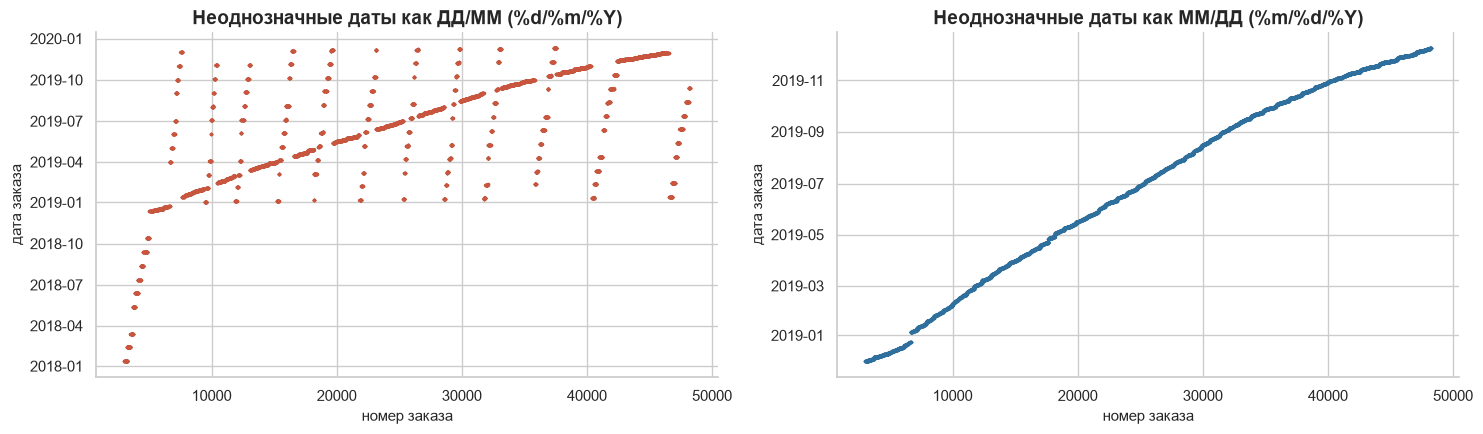

entry_date     datetime64[us]
order_id               string
customer_id             Int64
quantity              float64
price                 float64
name_clust              Int64
entry_id                Int64
country_id              Int64
dtype: object

In [8]:
DATE_FMT_DM = '%d/%m/%Y %H:%M'   # день/месяц/год
DATE_FMT_MD = '%m/%d/%Y %H:%M'   # месяц/день/год


def parse_dates(s, fmt):
    """Строгий разбор по формату (с секундами или без); всё, что под формат не подходит, → NaT."""
    out = pd.to_datetime(s, format=fmt, errors='coerce')
    return out.fillna(pd.to_datetime(s, format=fmt + ':%S', errors='coerce'))


date_raw = gift['entry_date'].astype(str).str.strip()
nums = date_raw.str.extract(r'^(\d{1,2})/(\d{1,2})/\d{4}').astype(float)
day_first = (nums[0] > 12).to_numpy()     # первое число может быть только днём → ДД/ММ
day_second = (nums[1] > 12).to_numpy()    # второе число может быть только днём → ММ/ДД
ambiguous = ~day_first & ~day_second
print(f'Строк, где первое число > 12 (точно ДД/ММ): {num(day_first.sum())}')
print(f'Строк, где второе число > 12 (точно ММ/ДД): {num(day_second.sum())}')
print(f'Неоднозначных строк (оба числа ≤ 12): {num(ambiguous.sum())} ({pct(ambiguous.mean())})')

dm, mdy = parse_dates(date_raw, DATE_FMT_DM), parse_dates(date_raw, DATE_FMT_MD)
# однозначные строки разбираются единственным подходящим форматом; варианты отличаются только неоднозначными строками
date_options = {
    'ДД/ММ (%d/%m/%Y)': dm.fillna(mdy),
    'ММ/ДД (%m/%d/%Y)': mdy.fillna(dm),
}
order_num = pd.to_numeric(gift['order_id'], errors='coerce')


def order_dates(dates):
    """Дата каждого заказа, упорядоченная по номеру заказа."""
    return pd.DataFrame({'num': order_num, 'date': dates}).dropna().groupby('num')['date'].min().sort_index()


def check_dates(dates):
    o = order_dates(dates)
    back = o < o.cummax().shift() - pd.Timedelta(days=1)   # заказ датирован раньше уже выданных номеров
    weekday_orders = o.groupby(o.dt.weekday).size().reindex(range(7), fill_value=0)
    return {
        'не распознано строк': int(dates.isna().sum()),
        'первая дата': dates.min(),
        'последняя дата': dates.max(),
        'заказов «из прошлого»': back.mean() if len(o) else np.nan,
        'корреляция номера и даты (Спирмен)': stats.spearmanr(np.arange(len(o)), o.rank()).correlation if len(o) > 2 else np.nan,
        'дней недели без единого заказа': int((weekday_orders == 0).sum()),
    }


date_check = pd.DataFrame({k: check_dates(v) for k, v in date_options.items()}).T
date_check.index.name = 'неоднозначные строки читаем как'
display(date_check.style.format({'заказов «из прошлого»': '{:.2%}', 'корреляция номера и даты (Спирмен)': '{:.3f}',
                                 'первая дата': '{:%d.%m.%Y}', 'последняя дата': '{:%d.%m.%Y}'}))

back_share = pd.to_numeric(date_check['заказов «из прошлого»'], errors='coerce')
best_date = back_share.idxmin() if back_share.notna().any() else list(date_options)[0]
other_date = [k for k in date_options if k != best_date][0]
print('Выбран вариант:', best_date)

# примеры неоднозначных строк: заказы идут по возрастанию номера
ex = pd.DataFrame({'номер заказа': order_num, 'строка в файле': date_raw,
                   f'как {list(date_options)[0]}': date_options[list(date_options)[0]],
                   f'как {list(date_options)[1]}': date_options[list(date_options)[1]]})[ambiguous]
ex = ex.dropna(subset=['номер заказа']).drop_duplicates('номер заказа').sort_values('номер заказа')
if len(ex):
    display(ex.iloc[np.linspace(0, len(ex) - 1, 10).astype(int)].reset_index(drop=True))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, (name, dates) in zip(axes, date_options.items()):
    o = order_dates(dates)
    ax.scatter(o.index, o.values, s=2, alpha=0.5, color=MAIN if name == best_date else BAD)
    ax.set_title(f'Неоднозначные даты как {name}')
    ax.set_xlabel('номер заказа')
    ax.set_ylabel('дата заказа')
plt.tight_layout()
plt.show()

gift['entry_date'] = date_options[best_date]
gift.dtypes

In [9]:
md(f"""**Вывод по датам.** В **{num(day_first.sum())}** строках первое число больше 12 — значит, дата записана как ДД/ММ{f', а в **{num(day_second.sum())}** строках больше 12 второе число — они записаны как ММ/ДД' if day_second.any() else ''}.
Остальные **{pct(ambiguous.mean())}** строк неоднозначны: по самой строке нельзя понять, где день, а где месяц.
Если читать их как **{best_date}**, даты растут вместе с номерами заказов: заказов, датированных раньше уже выданных номеров, — {pct(date_check.loc[best_date, 'заказов «из прошлого»'], 2)}, корреляция номера и даты — {date_check.loc[best_date, 'корреляция номера и даты (Спирмен)']:.3f}.
Вариант {other_date} даёт **{pct(date_check.loc[other_date, 'заказов «из прошлого»'], 2)}** таких заказов и первую дату {date_check.loc[other_date, 'первая дата']:%d.%m.%Y}: соседние по номеру заказы оказываются в разных месяцах (график и примеры выше).
Дней недели совсем без заказов: {date_check.loc[best_date, 'дней недели без единого заказа']} при выбранном варианте и {date_check.loc[other_date, 'дней недели без единого заказа']} при другом.
{'**В файле смешаны два формата:** даты с днём больше 12 записаны как ДД/ММ, а остальные — как ММ/ДД. ' if (best_date.startswith('ММ') and day_first.any()) else ''}Даты разобраны явными форматами `%d/%m/%Y %H:%M` и `%m/%d/%Y %H:%M`; нераспознанных дат — **{date_check.loc[best_date, 'не распознано строк']}**.""")

**Вывод по датам.** В **203 631** строках первое число больше 12 — значит, дата записана как ДД/ММ.
Остальные **43.0%** строк неоднозначны: по самой строке нельзя понять, где день, а где месяц.
Если читать их как **ММ/ДД (%m/%d/%Y)**, даты растут вместе с номерами заказов: заказов, датированных раньше уже выданных номеров, — 0.00%, корреляция номера и даты — 1.000.
Вариант ДД/ММ (%d/%m/%Y) даёт **88.12%** таких заказов и первую дату 12.01.2018: соседние по номеру заказы оказываются в разных месяцах (график и примеры выше).
Дней недели совсем без заказов: 1 при выбранном варианте и 0 при другом.
**В файле смешаны два формата:** даты с днём больше 12 записаны как ДД/ММ, а остальные — как ММ/ДД. Даты разобраны явными форматами `%d/%m/%Y %H:%M` и `%m/%d/%Y %H:%M`; нераспознанных дат — **0**.

### 1.4. Пропуски

In [10]:
def missing_report(df):
    rep = pd.DataFrame({'пропусков': df.isna().sum(), 'доля': df.isna().mean()})
    return rep[rep['пропусков'] > 0].sort_values('пропусков', ascending=False)


print('Продажи:')
display(missing_report(gift).style.format({'пропусков': '{:,.0f}', 'доля': '{:.2%}'}))
print('Справочник:')
display(missing_report(entries).style.format({'пропусков': '{:,.0f}', 'доля': '{:.2%}'}))

# скрытый пропуск: «неизвестный покупатель» записан не пустым значением, а числом -1
unknown_mark = gift['customer_id'].eq(UNKNOWN_ID).fillna(False)
print(f'Кроме того, customer_id = {UNKNOWN_ID} в {num(unknown_mark.sum())} строках ({pct(unknown_mark.mean())}). '
      'Это не номер клиента, а пометка «покупатель неизвестен» — скрытый пропуск, который isna() не видит.')
print('Других отрицательных номеров клиентов:', int(gift['customer_id'].lt(0).fillna(False).sum() - unknown_mark.sum()))

Продажи:


,пропусков,доля


Справочник:


,пропусков,доля
entry,1,0.03%


Кроме того, customer_id = -1 в 92 342 строках (25.9%). Это не номер клиента, а пометка «покупатель неизвестен» — скрытый пропуск, который isna() не видит.
Других отрицательных номеров клиентов: 0


Номер клиента нельзя «придумать», но его можно восстановить внутри заказа: если в одном заказе часть строк подписана клиентом, а часть — нет, это тот же клиент. Аналогично восстанавливаем страну — по заказу, а затем по клиенту. Остальные пропуски обрабатываем так:

| Столбец | Решение | Почему |
|---|---|---|
| `customer_id` (пропуск или `-1`) | восстановить по заказу; остальные строки **оставить** с единой пометкой «покупатель неизвестен» (`-1`) и флагом `known = False` | `-1` — не клиент, а отсутствие номера: за ним стоят разные люди. Поэтому в клиентские расчёты (число покупателей, профили, возвратность, sticky factor, RFM, гипотезы) такие строки не входят. Но сами продажи реальные, и в общих показателях продаж (выручка по месяцам, товарам, странам) их сохраняем |
| `entry_date`, `price`, `quantity` | удалить | без даты, цены или количества запись нельзя использовать в расчётах |
| `country_id` | восстановить по заказу/клиенту | страна одна на заказ |
| `name_clust` | заполнить `-1` («без группы») | признак вспомогательный, строку терять не нужно |
| `entry` (справочник) | заполнить «нет описания» | описание нужно только для подписей |

In [11]:
rows_0 = len(gift)
line_rev = gift['quantity'] * gift['price']
sales_mask = ((gift['quantity'] > 0) & (gift['price'] > 0)).fillna(False)
rev_0 = line_rev[sales_mask].sum()

# -1 — скрытый пропуск: превращаем его в настоящий, чтобы обработать вместе с остальными пропусками
gift['customer_id'] = gift['customer_id'].mask(gift['customer_id'].eq(UNKNOWN_ID).fillna(False))
no_client_0 = gift['customer_id'].isna()

# восстановление по заказу: если хотя бы в одной строке заказа клиент указан, это тот же клиент
gift['customer_id'] = gift['customer_id'].fillna(gift.groupby('order_id')['customer_id'].transform('first'))
if 'country_id' in gift.columns:
    gift['country_id'] = gift['country_id'].fillna(gift.groupby('order_id')['country_id'].transform('first'))
    gift['country_id'] = gift['country_id'].fillna(gift.groupby('customer_id')['country_id'].transform('first'))

unknown = gift['customer_id'].isna()
print(f'Строк без номера клиента (пропуск или {UNKNOWN_ID}): {num(no_client_0.sum())}, '
      f'восстановлено по заказу: {num(no_client_0.sum() - unknown.sum())}')
print(f'Остались без клиента: {num(unknown.sum())} строк ({pct(unknown.mean())}), '
      f'{num(gift.loc[unknown, "order_id"].nunique())} заказов, доля в выручке: {pct(line_rev[sales_mask & unknown].sum() / rev_0)}')

# строки не удаляем — продажи реальные; вместо номера ставим единую пометку, по ней дальше строится флаг known
gift['customer_id'] = gift['customer_id'].fillna(UNKNOWN_ID)

gift = gift.dropna(subset=['entry_date', 'price', 'quantity', 'order_id', 'entry_id'])
if 'name_clust' in gift.columns:
    gift['name_clust'] = gift['name_clust'].fillna(-1)
entries['entry'] = entries['entry'].fillna('нет описания')

S['unknown_rows_share'] = unknown.mean()
S['unknown_rev_share'] = line_rev[sales_mask & unknown].sum() / rev_0
print(f'Осталось строк: {num(len(gift))} из {num(rows_0)} ({pct(len(gift) / rows_0)})')
print('Пропусков после обработки:', int(gift.isna().sum().sum()))

Строк без номера клиента (пропуск или -1): 92 342, восстановлено по заказу: 0
Остались без клиента: 92 342 строк (25.9%), 3 085 заказов, доля в выручке: 17.9%
Осталось строк: 356 940 из 356 940 (100.0%)
Пропусков после обработки: 0


### 1.5. Дубликаты

In [12]:
dup_gift = gift.duplicated().sum()
print(f'Полных дубликатов в продажах: {num(dup_gift)} ({pct(dup_gift / len(gift), 2)})')
if dup_gift:
    example = gift[gift.duplicated(keep=False)].sort_values(['order_id', 'entry_id']).head(6)
    display(example)

dup_entries = entries.duplicated().sum()
multi_desc = entries.drop_duplicates()['entry_id'].duplicated(keep=False)
print(f'Полных дубликатов в справочнике: {dup_entries}')
print(f'entry_id с несколькими разными описаниями: {entries.drop_duplicates().loc[multi_desc, "entry_id"].nunique()}')
display(entries.drop_duplicates().loc[multi_desc].sort_values('entry_id').head(10))

Полных дубликатов в продажах: 3 573 (1.00%)


,entry_date,order_id,customer_id,quantity,price,name_clust,entry_id,country_id
54692,2019-02-08 10:32:00,10063,2141,1.00,125.00,759,396,28
54697,2019-02-08 10:32:00,10063,2141,1.00,125.00,759,396,28
54705,2019-02-08 10:32:00,10063,2141,24.00,21.00,37,1973,28
54706,2019-02-08 10:32:00,10063,2141,24.00,21.00,37,1973,28
55819,2019-02-09 13:37:00,10201,2463,1.00,995.00,603,2874,28
55825,2019-02-09 13:37:00,10201,2463,1.00,995.00,603,2874,28


Полных дубликатов в справочнике: 0
entry_id с несколькими разными описаниями: 0


,entry_id,entry


**Решение:**
- полные дубликаты в продажах — одинаковые строки в одном заказе в одну и ту же минуту. Это технический повтор записи, а не повторная покупка (повторная покупка того же товара попала бы в строку с бо́льшим количеством или в другой заказ). Удаляем, чтобы не завышать выручку;
- в справочнике удаляем полные дубликаты; если у одного `entry_id` несколько описаний, оставляем первое — описание нужно только для подписи товара, а лишние строки при объединении размножили бы продажи.

In [13]:
gift = gift.drop_duplicates().reset_index(drop=True)
entries = entries.drop_duplicates().drop_duplicates(subset='entry_id', keep='first').reset_index(drop=True)
print(f'Продажи: {num(len(gift))} строк, справочник: {num(len(entries))} строк (entry_id уникален: {entries["entry_id"].is_unique})')

Продажи: 353 367 строк, справочник: 2 917 строк (entry_id уникален: True)


### 1.6. Проверка соответствия идентификаторов

In [14]:
ids_sales, ids_dict = set(gift['entry_id'].dropna()), set(entries['entry_id'].dropna())
not_in_dict = gift['entry_id'].isin(ids_sales - ids_dict)
print(f'entry_id в продажах: {num(len(ids_sales))}, в справочнике: {num(len(ids_dict))}')
print(f'entry_id из продаж, которых нет в справочнике: {num(len(ids_sales - ids_dict))} '
      f'(строк продаж: {num(not_in_dict.sum())}, {pct(not_in_dict.mean(), 2)})')
print(f'entry_id из справочника, которые ни разу не продавались: {num(len(ids_dict - ids_sales))}')

checks = {
    'клиентов с несколькими странами (известные)': (gift[gift['customer_id'] != UNKNOWN_ID].groupby('customer_id')['country_id']
                                                    .nunique().gt(1).sum() if 'country_id' in gift else 0),
    'заказов с несколькими клиентами': gift.groupby('order_id')['customer_id'].nunique().gt(1).sum(),
    'заказов с несколькими странами': gift.groupby('order_id')['country_id'].nunique().gt(1).sum() if 'country_id' in gift else 0,
    'заказов с несколькими датами записи': gift.groupby('order_id')['entry_date'].nunique().gt(1).sum(),
    'товаров (entry_id) с несколькими name_clust': gift.groupby('entry_id')['name_clust'].nunique().gt(1).sum() if 'name_clust' in gift else 0,
}
display(pd.Series(checks, name='количество').to_frame())

prefixes = gift['order_id'].str.extract(r'^([A-Za-z]+)', expand=False).fillna('без префикса')
print('Префиксы номеров заказов:')
display(pd.crosstab(prefixes, np.sign(gift['quantity']).map({-1: 'quantity < 0', 0: 'quantity = 0', 1: 'quantity > 0'})))

entry_id в продажах: 2 917, в справочнике: 2 917
entry_id из продаж, которых нет в справочнике: 0 (строк продаж: 0, 0.00%)
entry_id из справочника, которые ни разу не продавались: 0


,количество
клиентов с несколькими странами (известные),3
заказов с несколькими клиентами,0
заказов с несколькими странами,0
заказов с несколькими датами записи,37
товаров (entry_id) с несколькими name_clust,0


Префиксы номеров заказов:


quantity,quantity < 0,quantity > 0
order_id,,
без префикса,1037,352330


**Что видно:**
- каждый заказ относится к одному клиенту — связь «заказ → клиент» корректна, поэтому заказ можно использовать как единицу покупки;
- часть клиентов может встречаться в нескольких странах (например, при доставке в разные адреса) — для профиля клиента возьмём страну, в которую он заказывал чаще всего;
- заказы с буквенным префиксом (как правило, `C`) содержат отрицательные количества — это отмены и возвраты, их разберём на шаге 2;
- товары, которых нет в справочнике, оставляем: продажа реальная, у неё просто нет текстового описания.

### 1.7. Объединение таблиц

Присоединяем описание к каждой строке продаж по `entry_id` (левое соединение, связь «многие к одному»). Количество строк при этом не должно измениться.

In [15]:
rows_before = len(gift)
df = gift.merge(entries[['entry_id', 'entry']], on='entry_id', how='left', validate='many_to_one')
df['entry'] = df['entry'].fillna('нет описания')

# пропусков в идентификаторах больше нет — переводим их из Int64 (с поддержкой пропусков) в обычный int64,
# чтобы в расчётах не возникало конфликтов типов (например, Int64 и дробных чисел)
for col in ['customer_id', 'country_id', 'name_clust', 'entry_id']:
    if col in df.columns and pd.api.types.is_integer_dtype(df[col]) and df[col].notna().all():
        df[col] = df[col].astype('int64')
assert len(df) == rows_before, 'объединение изменило число строк'
df['known'] = df['customer_id'] != UNKNOWN_ID     # False — покупатель неизвестен (customer_id = -1)
print(f'Строк с известным покупателем: {pct(df["known"].mean())}, с неизвестным: {pct(1 - df["known"].mean())}')
print(f'Строк после объединения: {num(len(df))} (было {num(rows_before)})')
display(df.head())

Строк с известным покупателем: 73.9%, с неизвестным: 26.1%
Строк после объединения: 353 367 (было 353 367)


,entry_date,order_id,customer_id,quantity,price,name_clust,entry_id,country_id,entry,known
0,2018-12-01 08:26:00,3031,2150,6.00,339.00,740,891,28,белый металлический фонарь,True
1,2018-12-01 08:26:00,3031,2150,8.00,275.00,132,1596,28,кремовая вешалка в форме сердечек Купидона,True
2,2018-12-01 08:26:00,3031,2150,6.00,339.00,197,166,28,Вязаная грелка с флагом Союза,True
3,2018-12-01 08:26:00,3031,2150,2.00,765.00,767,1810,28,набор 7 скворечников для бабушек,True
4,2018-12-01 08:26:00,3031,2150,6.00,425.00,383,2585,28,стеклянный матовый держатель в форме звезды,True


### Вывод по шагу 1

- Данные загружены и объединены в одну таблицу: к каждой продаже добавлено текстовое описание товара; число строк при объединении не изменилось.
- Типы приведены: идентификаторы — к целым числам, номер заказа — к строке. Даты разобраны явными форматами. В файле смешаны два порядка записи — ДД/ММ (день больше 12) и ММ/ДД (день не больше 12); верный вариант подтверждён последовательностью номеров заказов.
- `customer_id = -1` — пометка «покупатель неизвестен», а не реальный клиент. Восстановить номер по заказу не удалось, поэтому такие строки помечены флагом `known = False`: они остаются в общих показателях продаж, но не входят в клиентские расчёты.
- Удалены полные дубликаты записей и повторы в справочнике.
- В данных есть отрицательные количества (возвраты, списания) — ими займёмся при предобработке.

<div class="alert alert-success">
<b>✔️ Комментарий ревьюера v1:</b>
<br>
Проверены связи заказа с клиентом и страной, а объединение защищено validate и контролем числа строк. Эти проверки помогают сохранить правильную структуру данных, от которой зависят суммы заказов и клиентские профили.
</div>


## Шаг 2. Предобработка и начало исследовательского анализа

### 2.1. Выбросы и аномалии в `price` и `quantity`

Посчитаем стоимость каждой товарной позиции: `revenue = quantity × price` — это сумма, которую клиент заплатил за конкретный товар в заказе.

In [16]:
df['revenue'] = df['quantity'] * df['price']
display(df[['quantity', 'price', 'revenue']].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99, .999]).T)

anomalies = pd.Series({
    'quantity < 0 (отмены/возвраты)': (df['quantity'] < 0).sum(),
    'quantity = 0': (df['quantity'] == 0).sum(),
    'price = 0 (бесплатно/корректировки)': (df['price'] == 0).sum(),
    'price < 0 (бухгалтерские корректировки)': (df['price'] < 0).sum(),
}, name='строк')
display(anomalies.to_frame().assign(доля=lambda t: t['строк'] / len(df)).style.format({'строк': '{:,.0f}', 'доля': '{:.2%}'}))

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,99.9%,max
quantity,353 367.00,10.22,147.51,-9 600.00,1.00,1.00,1.00,3.00,10.00,28.00,100.00,480.00,80 995.00
price,353 367.00,401.68,5 084.62,-1 106 206.00,19.00,42.00,125.00,208.00,413.00,995.00,1 895.00,20 868.87,1 354 133.00
revenue,353 367.00,1 936.16,29 398.75,-1 106 206.00,42.00,110.00,375.00,936.00,1 725.00,5 568.00,18 000.00,81 360.00,16 846 960.00


,строк,доля
quantity < 0 (отмены/возвраты),"1,037",0.29%
quantity = 0,0,0.00%
price = 0 (бесплатно/корректировки),"2,071",0.59%
price < 0 (бухгалтерские корректировки),2,0.00%


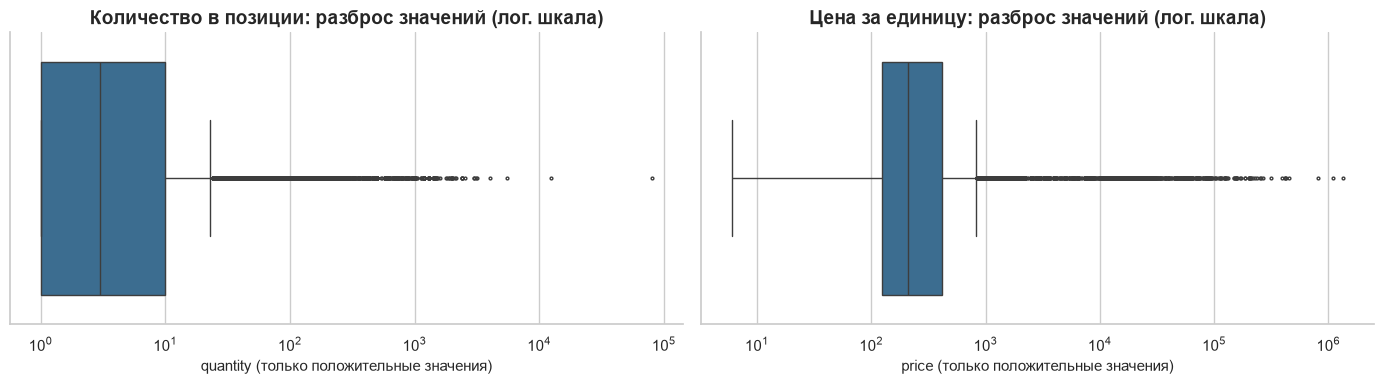

Самые крупные позиции по количеству:


,entry_date,order_id,customer_id,quantity,price,entry
352335,2019-12-09 09:15:00,48149,3554,80 995.00,208.00,"поделка из бумаги, маленькая птичка"
327404,2019-11-25 15:57:00,45507,6744,12 540.00,0.00,"дизайн 3d бумажные наклейки, в асс"
47896,2019-01-28 12:03:00,9170,-1,5 568.00,0.00,нет описания
143421,2019-06-09 15:04:00,22897,-1,4 000.00,0.00,нет описания
176439,2019-07-19 17:04:00,27265,5391,3 186.00,6.00,"Эфирный бальзам 3,5г банка в конверте"


Самые крупные отрицательные позиции:


,entry_date,order_id,customer_id,quantity,price,entry
146510,2019-06-14 10:37:00,23357,-1,-9 600.00,0.00,ПЯТНА ОТ ПЕЧАТИ/ВЫБРОШЕНЫ
146509,2019-06-14 10:37:00,23356,-1,-9 600.00,0.00,ПЯТНА ОТ ПЕЧАТИ/ВЫБРОШЕНЫ
146508,2019-06-14 10:36:00,23353,-1,-9 058.00,0.00,ПЯТНА ОТ ПЕЧАТИ/ВЫБРОШЕНЫ
281291,2019-10-31 15:17:00,40262,-1,-4 830.00,0.00,"НЕ ПОДЛЕЖИТ ПРОДАЖЕ, УНИЧТОЖЕН."
223257,2019-09-14 17:53:00,33434,-1,-3 667.00,0.00,нет описания


Самые высокие цены:


,entry_date,order_id,customer_id,quantity,price,entry
9509,2018-12-07 15:08:00,4298,-1,1.00,1 354 133.00,КОМИССИЯ АМАЗОН
195677,2019-08-12 14:50:00,29851,-1,1.00,1 106 206.00,КОРРЕКТИРОВКА БЕЗНАДЕЖНЫЙ ДОЛГ
111883,2019-05-03 13:46:00,18363,3971,1.00,814 275.00,ПОЧТОВЫЕ РАСХОДЫ
194165,2019-08-11 10:14:00,29621,-1,1.00,450 517.00,"ДОТКОМ, ПОЧТОВЫЕ РАСХОДЫ"
174643,2019-07-18 12:30:00,27039,-1,1.00,428 763.00,РУКОВОДСТВО
275359,2019-10-27 14:20:00,39746,7464,1.00,416 106.00,РУКОВОДСТВО
275346,2019-10-27 14:13:00,39743,7464,1.00,416 106.00,РУКОВОДСТВО
265020,2019-10-19 11:18:00,38417,7256,1.00,394 932.00,РУКОВОДСТВО


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col, title in zip(axes, ['quantity', 'price'], ['Количество в позиции', 'Цена за единицу']):
    data = df.loc[df[col] > 0, col]
    sns.boxplot(x=data, ax=ax, color=MAIN, fliersize=2, linewidth=1)
    ax.set_xscale('log')
    ax.set_title(f'{title}: разброс значений (лог. шкала)')
    ax.set_xlabel(f'{col} (только положительные значения)')
plt.tight_layout()
plt.show()

print('Самые крупные позиции по количеству:')
display(df.sort_values('quantity', ascending=False).head(5)[['entry_date', 'order_id', 'customer_id', 'quantity', 'price', 'entry']])
print('Самые крупные отрицательные позиции:')
display(df.sort_values('quantity').head(5)[['entry_date', 'order_id', 'customer_id', 'quantity', 'price', 'entry']])
print('Самые высокие цены:')
display(df.sort_values('price', ascending=False).head(8)[['entry_date', 'order_id', 'customer_id', 'quantity', 'price', 'entry']])

Диаграммы размаха построены в логарифмическом масштабе: значения отличаются на порядки, и в обычном масштабе «ящик» сжался бы в точку. Видно, что у обоих признаков длинный правый хвост: большинство позиций — это несколько штук по цене в несколько единиц, но встречаются партии в тысячи штук и единичные позиции с огромной ценой.

Среди самых дорогих позиций — не товары, а **служебные записи**: почтовые расходы, комиссии, ручные корректировки. Искать их по одному слову нельзя: слова «почта», «перевозка», «банк» встречаются и в названиях настоящих товаров (например, металлический знак «Нет нежелательной почте»), а короткий список слов пропускает часть служебных записей. Поэтому действуем в два шага.

1. **Собираем кандидатов** — описания, где есть слова, связанные с доставкой, сборами, комиссиями и учётными операциями, а также описания, набранные целиком заглавными буквами. В этом справочнике так записаны служебные пометки (`ПОЧТОВЫЕ РАСХОДЫ`, `РУКОВОДСТВО`, `КОРРЕКТИРОВКА БЕЗНАДЕЖНЫЙ ДОЛГ`), а товары — обычным регистром.
2. **Проверяем каждого кандидата по названию.** Служебной считаем запись, если название служебное (целиком заглавными или начинается со слов «почтовые расходы», «перевозка», «доставка», «комиссия», «банковские сборы», «плата за», «корректировка» и т. п.) и в нём нет слова, обозначающего предмет (знак, коврик, открытка, фонарь, часы, сумка…). Для контроля рядом выводим цену и типичное количество: служебная запись обычно идёт одной штукой на заказ, а «цена» у неё — тариф или сумма операции. Тариф бывает фиксированным (перевозка) или разным в каждом заказе (почтовые расходы, ручные корректировки). Товары обычно покупают по несколько штук по прайсовой цене.

Итог фиксируем **точным списком `entry_id`** и выводим целиком, чтобы каждое решение можно было проверить.

In [18]:
# 1) слова-кандидаты: доставка, сборы, комиссии, учётные операции (по-русски и по-английски)
CANDIDATE_WORDS = (r'(?i)(?<!\w)(почт\w*|авиапочт\w*|доставк\w*|перевоз\w*|руководств\w*|вручную|банковск\w*|комисси\w*|'
                   r'сбор\w*|плат[аы]\s+за|скидк\w*|образ(?:ец|цы|цов)|корректир\w*|скорректир\w*|безнадежн\w*|дотком\w*|'
                   r'амазон\w*|ebay|amazon|postage|carriage|manual|bank|fee|charges?|commission|discount|samples?|adjust\w*|dotcom\w*)')
# 2) служебное название: описание начинается со слова об услуге или учётной операции
SERVICE_START = (r'(?i)^\W*(почтов\w*\s+(?:расход|сбор|услуг)|доставк|перевозк|руководств|вручную|'
                 r'банковск\w*\s+(?:сбор|расход|комисс|плат|услуг)|комисси|плата\s+за|сбор\s+за|скидк|образц|корректир|'
                 r'скорректир|postage|carriage|manual|bank\s+charge|amazon\s+fee|discount|samples?|adjust)')
# 3) слова-предметы: если они есть в названии, это товар, даже если рядом стоит «почта» или «банк»
PRODUCT_WORDS = (r'(?i)(знак|табличк|вывеск|коврик|открытк|карточк|чехол|подушк|шкаф|фонар|часы|кружк|чашк|полотенц|'
                 r'кошел|сумк|копилк|ящик|рамк|игрушк|набор|подставк|свеч|тарелк|ламп|светильник|брелок|магнит|блокнот|'
                 r'ручк|карандаш|наклейк|коробк|корзин|кукл|банк[аиу]\b|сертификат|поделк|'
                 r'sign|doormat|card|lantern|clock|cover|cabinet|voucher)')

names_all = df.groupby('entry_id')['entry'].first().astype(object)
letters = names_all.str.replace(r'[^A-Za-zА-Яа-яЁё]', '', regex=True)
flags = pd.DataFrame({
    'описание': names_all,
    'заглавными': (letters.str.len() >= 3) & (letters == letters.str.upper()),
    'служебное начало': names_all.str.contains(SERVICE_START, regex=True),
    'служебное слово': names_all.str.contains(CANDIDATE_WORDS, regex=True),
    'предмет в названии': names_all.str.contains(PRODUCT_WORDS, regex=True),
    'нет описания': names_all.eq('нет описания'),
})
flags['служебная запись'] = ((flags['заглавными'] | flags['служебное начало'] | flags['нет описания'])
                             & ~flags['предмет в названии'])
is_cand = flags[['заглавными', 'служебное начало', 'служебное слово', 'нет описания']].any(axis=1)

# поведение цены у кандидатов (по строкам продаж с положительными количеством и ценой)
sold = df[(df['quantity'] > 0) & (df['price'] > 0)]
price_stats = sold.groupby('entry_id').agg(строк=('price', 'size'), заказов=('order_id', 'nunique'),
                                           выручка=('revenue', 'sum'), медиана_цены=('price', 'median'),
                                           разных_цен=('price', 'nunique'),
                                           разброс_цены=('price', lambda p: p.std(ddof=0) / p.mean()),
                                           медиана_кол_ва=('quantity', 'median'))
candidates = flags[is_cand].join(price_stats)
candidates['решение'] = np.where(candidates['служебная запись'], 'служебная — исключить', 'товар — оставить')
candidates = candidates.sort_values(['решение', 'выручка'], ascending=[True, False])

SERVICE_IDS = sorted(flags.index[flags['служебная запись']])
in_service = df['entry_id'].isin(SERVICE_IDS)
print(f'Кандидатов: {len(candidates)}; служебных записей: {len(SERVICE_IDS)} — '
      f'{num(in_service.sum())} строк ({pct(in_service.mean(), 2)}).')
show_cols = ['описание', 'решение', 'строк', 'заказов', 'выручка', 'медиана_цены', 'разных_цен', 'разброс_цены',
             'медиана_кол_ва', 'заглавными', 'служебное начало', 'предмет в названии']
no_sales = candidates[candidates['строк'].isna()]
print(f'Кандидатов без продаж с положительными ценой и количеством: {len(no_sales)} '
      f'(служебные пометки к возвратам и списаниям, они уйдут и на шагах 2–3), например: '
      + ', '.join(f'«{short(n, 30)}»' for n in no_sales['описание'].head(8)))
print('Кандидаты с продажами и решение по каждому:')
display(candidates.loc[candidates['строк'].notna(), show_cols].style.format(
    {'строк': '{:,.0f}', 'заказов': '{:,.0f}', 'выручка': '{:,.0f}', 'медиана_цены': '{:,.0f}', 'разных_цен': '{:,.0f}',
     'разброс_цены': '{:.2f}', 'медиана_кол_ва': '{:,.0f}'}, na_rep='—'))

Кандидатов: 109; служебных записей: 95 — 4 128 строк (1.17%).
Кандидатов без продаж с положительными ценой и количеством: 97 (служебные пометки к возвратам и списаниям, они уйдут и на шагах 2–3), например: «нет описания», «АКЦИИ ЗАЧИСЛЕНЫ ОШИБОЧНО», «АЛЛА, Я СДЕЛАЛ КРЕДИТ И НЕ ПО…», «АЛЛО, ЭТО ДЖЕКИ, НЕ МОГУ ИЗМЕ…», «АЛЛО, ЭТО ДЖЕКИ, Я ВСЁ ПОСЧИТ…», «АННА, НУЖНО СЕГОДНЯ РАСПРЕДЕЛ…», «БЫЛ ОТЛОЖЕН В СТОРОНУ», «БЫЛ ОТЛОЖЕН В СТОРОНУ.»
Кандидаты с продажами и решение по каждому:


,описание,решение,строк,заказов,выручка,медиана_цены,разных_цен,разброс_цены,медиана_кол_ва,заглавными,служебное начало,предмет в названии
entry_id,,,,,,,,,,,,
180,"ДОТКОМ, ПОЧТОВЫЕ РАСХОДЫ",служебная — исключить,706,706,"20,624,877","18,547",686,1.22,1,True,False,False
2253,ПОЧТОВЫЕ РАСХОДЫ,служебная — исключить,"1,070","1,070","7,296,094","1,800",52,8.20,2,True,True,False
2375,РУКОВОДСТВО,служебная — исключить,309,283,"6,953,827",165,124,2.99,1,True,True,False
1493,КОМИССИЯ АМАЗОН,служебная — исключить,2,2,"1,376,109","688,054",2,0.97,1,True,True,False
1548,КОРРЕКТИРОВКА БЕЗНАДЕЖНЫЙ ДОЛГ,служебная — исключить,1,1,"1,106,206","1,106,206",1,0.00,1,True,True,False
838,АВИАПОЧТА,служебная — исключить,219,219,"596,410",795,8,0.33,2,True,False,False
2118,перевозка,служебная — исключить,32,32,"166,100","5,000",4,0.37,1,False,True,False
494,ОТКРЫТИЕ БАНКОВСКОГО СЧЕТА,служебная — исключить,37,37,"12,740",42,5,0.30,5,True,False,False
491,ОБРАЗЦЫ,служебная — исключить,2,2,"6,305","3,152",2,0.05,1,True,True,False


In [19]:
sold_cand = candidates[candidates['строк'].notna()]
serv, kept = sold_cand[sold_cand['служебная запись']], sold_cand[~sold_cand['служебная запись']]


def describe_entry(row):
    return (f"«{short(row['описание'], 45)}» — {'служебная запись' if row['служебная запись'] else 'товар'}: "
            f"медианная цена {num(row['медиана_цены'])}, разброс цены {row['разброс_цены']:.2f}, "
            f"обычно по {num(row['медиана_кол_ва'])} шт., заказов: {num(row['заказов'])}")


special = sold_cand[sold_cand['описание'].str.contains(r'(?i)авиапочт|банковск\w*\s+сч|почт|перевоз|руководств', regex=True)]
md(f"""**Вывод по служебным записям.** Всего в список служебных попало записей: **{len(SERVICE_IDS)}**. Продажи с положительной ценой есть у **{len(serv)}** из них — это они влияют на выручку: {', '.join(f'«{short(n, 40)}»' for n in serv.sort_values('выручка', ascending=False)['описание'].head(12))}{' и др.' if len(serv) > 12 else ''}.
Вместе они дают {pct(serv['выручка'].sum() / sold['revenue'].sum(), 1)} выручки. Типичное количество у служебных записей — 1 шт. в {num((serv['медиана_кол_ва'] <= 1).sum())} случаях из {len(serv)}, у товаров среди кандидатов — в {num((kept['медиана_кол_ва'] <= 1).sum())} из {len(kept)}.
Оставлено как товары кандидатов со «служебными» словами в названии: **{len(kept)}**.

Записи со словами «почта», «перевозка», «руководство», «банковский счёт»:
""" + '\n'.join(f'- {describe_entry(r)}' for _, r in special.sort_values('служебная запись', ascending=False).iterrows()))

**Вывод по служебным записям.** Всего в список служебных попало записей: **95**. Продажи с положительной ценой есть у **10** из них — это они влияют на выручку: «ДОТКОМ, ПОЧТОВЫЕ РАСХОДЫ», «ПОЧТОВЫЕ РАСХОДЫ», «РУКОВОДСТВО», «КОМИССИЯ АМАЗОН», «КОРРЕКТИРОВКА БЕЗНАДЕЖНЫЙ ДОЛГ», «АВИАПОЧТА», «перевозка», «ОТКРЫТИЕ БАНКОВСКОГО СЧЕТА», «ОБРАЗЦЫ», «КРАСИВО ЗАВЕРНУТЬ».
Вместе они дают 5.6% выручки. Типичное количество у служебных записей — 1 шт. в 6 случаях из 10, у товаров среди кандидатов — в 0 из 2.
Оставлено как товары кандидатов со «служебными» словами в названии: **2**.

Записи со словами «почта», «перевозка», «руководство», «банковский счёт»:
- «ДОТКОМ, ПОЧТОВЫЕ РАСХОДЫ» — служебная запись: медианная цена 18 547, разброс цены 1.22, обычно по 1 шт., заказов: 706
- «ПОЧТОВЫЕ РАСХОДЫ» — служебная запись: медианная цена 1 800, разброс цены 8.20, обычно по 2 шт., заказов: 1 070
- «РУКОВОДСТВО» — служебная запись: медианная цена 165, разброс цены 2.99, обычно по 1 шт., заказов: 283
- «АВИАПОЧТА» — служебная запись: медианная цена 795, разброс цены 0.33, обычно по 2 шт., заказов: 219
- «перевозка» — служебная запись: медианная цена 5 000, разброс цены 0.37, обычно по 1 шт., заказов: 32
- «ОТКРЫТИЕ БАНКОВСКОГО СЧЕТА» — служебная запись: медианная цена 42, разброс цены 0.30, обычно по 5 шт., заказов: 37
- «Металлический знак "Нет нежелательной почте"» — товар: медианная цена 125, разброс цены 0.67, обычно по 2 шт., заказов: 262

**Решение по очистке** (каждый шаг фиксируется в таблице потерь — по строкам, заказам и выручке):

1. **Отменённые покупки.** Если у известного клиента есть отмена (`quantity < 0`) того же товара в том же количестве и по той же цене, а до неё — соответствующая покупка, удаляем *обе* строки: покупки фактически не было. Для неизвестных покупателей пару «покупка — отмена» установить нельзя: `-1` объединяет разных людей.
2. **Остальные отрицательные количества** — возвраты, списания брака и складские корректировки (`ПЯТНА ОТ ПЕЧАТИ/ВЫБРОШЕНЫ`, `НЕ ПОДЛЕЖИТ ПРОДАЖЕ…`). Это не покупательская активность — удаляем.
3. **Нулевые и отрицательные цены** — бесплатные позиции и бухгалтерские списания. Удаляем: они не отражают продажи.
4. **Служебные записи** — точный список `entry_id`, отобранный выше. Удаляем, чтобы выручка и средний чек считались по товарам.
5. **Экстремальные значения.** Автоматически по перцентилю ничего не удаляем: оптовые партии и дорогие товары — нормальная часть бизнеса. Сначала проверяем подозрительные позиции по контексту (ниже) и исключаем только те, где ошибка подтверждается.

In [20]:
def log_step(name, data):
    clean_log.append((name, len(data), data['order_id'].nunique(), data.loc[data['quantity'] > 0, 'revenue'].sum()))


clean_log = []
log_step('исходные данные (после шага 1)', df)

# 1. пары «покупка — отмена» — только у известных покупателей
d = df.reset_index(drop=True)
neg = d[(d['quantity'] < 0) & d['known']].reset_index().rename(columns={'index': 'neg_idx'})
pos = d[(d['quantity'] > 0) & d['known']].reset_index().rename(columns={'index': 'pos_idx'})
neg['abs_q'] = -neg['quantity']
pairs = neg[['neg_idx', 'customer_id', 'entry_id', 'abs_q', 'price', 'entry_date']].merge(
    pos[['pos_idx', 'customer_id', 'entry_id', 'quantity', 'price', 'entry_date']],
    left_on=['customer_id', 'entry_id', 'abs_q', 'price'],
    right_on=['customer_id', 'entry_id', 'quantity', 'price'],
    suffixes=('_neg', '_pos'))
pairs = (pairs[pairs['entry_date_pos'] <= pairs['entry_date_neg']]
         .sort_values('entry_date_pos')
         .drop_duplicates('neg_idx', keep='last')     # для каждой отмены — ближайшая предшествующая покупка
         .drop_duplicates('pos_idx', keep='last'))    # каждую покупку гасим не более одного раза
print(f'Найдено пар «покупка — отмена» у известных покупателей: {num(len(pairs))}')
d = d.drop(index=pairs['pos_idx'])
log_step('1. удалены отменённые покупки', d)

# 2. отрицательные и нулевые количества
d = d[d['quantity'] > 0]
log_step('2. удалены отмены, возвраты и списания (quantity ≤ 0)', d)

# 3. нулевые и отрицательные цены
d = d[d['price'] > 0]
log_step('3. удалены позиции с ценой ≤ 0', d)

# 4. служебные записи — по точному списку entry_id
d = d[~d['entry_id'].isin(SERVICE_IDS)]
log_step(f'4. удалены служебные записи (видов: {len(SERVICE_IDS)})', d)
print(f'После шагов 1–4: {num(len(d))} строк')

Найдено пар «покупка — отмена» у известных покупателей: 0
После шагов 1–4: 348 915 строк


#### Экстремальные значения: проверка по контексту

Отсечение по перцентилю убрало бы просто самые редкие значения, а редкость ещё не означает ошибку. В прошлой версии отсечение по 99,9-му перцентилю удалило 0,1% строк, но около 8% выручки — в основном дорогие товары и крупные партии. Поэтому смотрим на подозрительные позиции в контексте:
- **товара** — обычные для него количество и цена (медианы по всем его продажам) и в скольких заказах он встречается;
- **клиента** — сколько у него заказов и какую долю всех его трат даёт эта позиция;
- **магазина** — какую долю выручки месяца даёт одна эта строка.

На проверку берём по 15 позиций с самым большим количеством, самой высокой ценой и самой большой стоимостью, а также все позиции, цена которых в 10 и более раз выше обычной цены этого же товара.

**Критерий ошибки.** Позицию исключаем, только если выполняются оба условия:
1. одна строка даёт **не меньше 1% выручки магазина за месяц** — даже для крупной оптовой позиции это очень много;
2. у клиента **нет сопоставимых покупок**: на эту строку приходится **не меньше 90% всех его трат**.

Так выглядит ошибочный ввод: лишние разряды в количестве или сумма, записанная в поле цены. Крупные партии постоянных оптовиков (для них позиция — небольшая часть трат) и дорогие товары с обычной для них ценой под критерий не попадают и остаются. У неизвестных покупателей историю проверить нельзя, поэтому их позиции по этому критерию не исключаем.

Подозрительные позиции и решение по каждой:


,entry_date,order_id,customer_id,entry,quantity,price,revenue,обычное кол-во,обычная цена,заказов с товаром,заказов клиента,доля в тратах клиента,доля в выручке месяца,цена / обычная цена,решение
352335,09.12.2019,48149,3554,"поделка из бумаги, маленькая пт…","80,995",208,"16,846,960","80,995",208,1,2,100.0%,37.34%,1.0,ИСКЛЮЧИТЬ: строка ≥ 1% выручки месяца и ≥ 90% всех трат клиента
274865,27.10.2019,39669,5354,ночник в форме кролика,"2,400",208,"499,200",6,208,979,68,2.4%,0.70%,1.0,оставить: у клиента есть другие сопоставимые покупки (< 90% трат)
33707,11.01.2019,7484,4251,сказочный торт,670,675,"452,250",2,795,356,2,30.5%,1.26%,0.8,оставить: у клиента есть другие сопоставимые покупки (< 90% трат)
158929,30.06.2019,25192,2051,розы в чайнике в стиле регентст…,540,815,"440,100",2,995,394,35,10.4%,0.97%,0.8,оставить: у клиента есть другие сопоставимые покупки (< 90% трат)
103213,18.04.2019,17127,4251,сказочный торт,670,635,"425,450",2,795,356,2,28.7%,1.26%,0.8,оставить: у клиента есть другие сопоставимые покупки (< 90% трат)
10464,07.12.2018,4325,1898,Винтажная мемориальная доска Юн…,600,638,"382,800",2,995,221,57,2.4%,0.81%,0.6,оставить: у клиента есть другие сопоставимые покупки (< 90% трат)
227628,20.09.2019,34089,2550,разделочная доска для кладовой,756,506,"382,536",3,495,56,29,4.3%,0.60%,1.0,оставить: у клиента есть другие сопоставимые покупки (< 90% трат)
12676,09.12.2018,4565,7245,"круглые коробки для закусок, на…","1,488",255,"379,440",6,295,575,2,99.7%,0.80%,0.9,оставить: позиция мала относительно выручки месяца (< 1%)
333429,29.11.2019,46164,7202,ночник в форме кролика,"2,040",179,"365,160",6,208,979,3,54.2%,0.41%,0.9,оставить: у клиента есть другие сопоставимые покупки (< 90% трат)
227632,20.09.2019,34089,2550,"набор из 6 баночек для специй, …",852,425,"362,100",4,395,813,29,4.1%,0.57%,1.1,оставить: у клиента есть другие сопоставимые покупки (< 90% трат)


Позиций с ценой в 10+ раз выше обычной для товара: 254, из них у неизвестных покупателей: 252; их выручка — 0.04% от общей; исключаются по критерию ошибки: 0


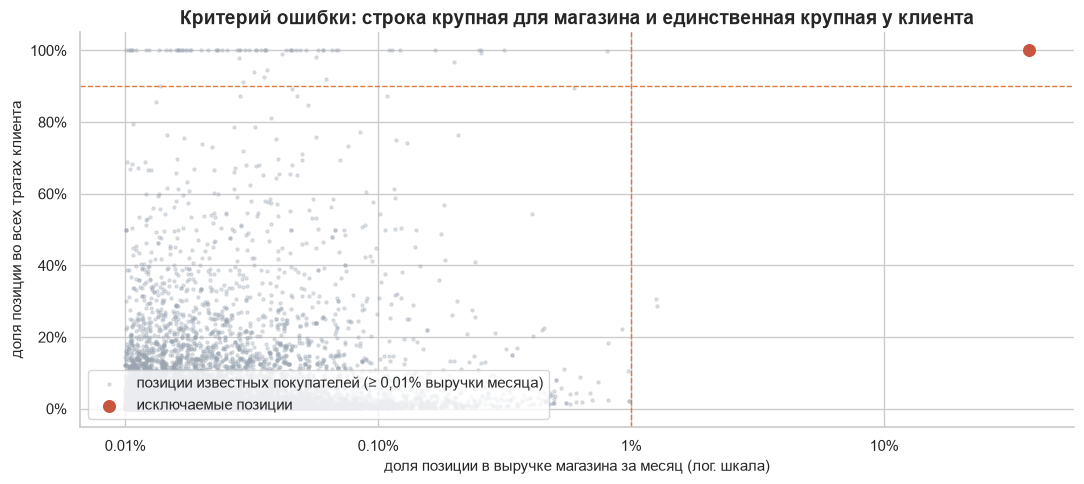

In [21]:
MONTH_SHARE, CLIENT_SHARE, PRICE_RATIO = 0.01, 0.90, 10

ctx = pd.DataFrame(index=d.index)
ctx['обычное кол-во'] = d.groupby('entry_id')['quantity'].transform('median')
ctx['обычная цена'] = d.groupby('entry_id')['price'].transform('median')
ctx['заказов с товаром'] = d.groupby('entry_id')['order_id'].transform('nunique')
known_part = d[d['known']]
ctx['заказов клиента'] = d['customer_id'].map(known_part.groupby('customer_id')['order_id'].nunique()).where(d['known'])
ctx['доля в тратах клиента'] = (d['revenue'] / d['customer_id'].map(known_part.groupby('customer_id')['revenue'].sum())).where(d['known'])
ctx['доля в выручке месяца'] = d['revenue'] / d.groupby(d['entry_date'].dt.to_period('M'))['revenue'].transform('sum')
ctx['цена / обычная цена'] = d['price'] / ctx['обычная цена']

is_error = (ctx['доля в выручке месяца'] >= MONTH_SHARE) & (ctx['доля в тратах клиента'] >= CLIENT_SHARE).fillna(False)
ctx['решение'] = np.select(
    [is_error, ~d['known'], ctx['цена / обычная цена'] >= PRICE_RATIO, ctx['доля в тратах клиента'] < CLIENT_SHARE],
    ['ИСКЛЮЧИТЬ: строка ≥ 1% выручки месяца и ≥ 90% всех трат клиента',
     'оставить: покупатель неизвестен, историю проверить нельзя',
     'оставить: цена нетипична для товара, но позиция мала (< 1% выручки месяца)',
     'оставить: у клиента есть другие сопоставимые покупки (< 90% трат)'],
    default='оставить: позиция мала относительно выручки месяца (< 1%)')

check_idx = (d['quantity'].nlargest(15).index.union(d['price'].nlargest(15).index)
             .union(d['revenue'].nlargest(15).index).union(d.index[is_error]))
suspects = (d.loc[check_idx, ['entry_date', 'order_id', 'customer_id', 'entry', 'quantity', 'price', 'revenue']]
            .join(ctx.loc[check_idx]).sort_values('revenue', ascending=False))
suspects['entry'] = suspects['entry'].map(lambda t: short(t, 32))
print('Подозрительные позиции и решение по каждой:')
display(suspects.style.format({'entry_date': '{:%d.%m.%Y}', 'quantity': '{:,.0f}', 'price': '{:,.0f}', 'revenue': '{:,.0f}',
                               'обычное кол-во': '{:,.0f}', 'обычная цена': '{:,.0f}', 'заказов с товаром': '{:,.0f}',
                               'заказов клиента': '{:,.0f}', 'доля в тратах клиента': '{:.1%}',
                               'доля в выручке месяца': '{:.2%}', 'цена / обычная цена': '{:.1f}'}, na_rep='—'))

odd_price = ctx['цена / обычная цена'] >= PRICE_RATIO
print(f'Позиций с ценой в {PRICE_RATIO}+ раз выше обычной для товара: {num(odd_price.sum())}, '
      f'из них у неизвестных покупателей: {num((odd_price & ~d["known"]).sum())}; '
      f'их выручка — {pct(d.loc[odd_price, "revenue"].sum() / d["revenue"].sum(), 2)} от общей; '
      f'исключаются по критерию ошибки: {num((odd_price & is_error).sum())}')

# наглядно: где проходят пороги критерия
kp = ctx[d['known'] & (ctx['доля в выручке месяца'] >= 1e-4)]
fig, ax = plt.subplots(figsize=(11, 5))
ax.scatter(kp['доля в выручке месяца'], kp['доля в тратах клиента'], s=5, alpha=0.3, color=GREY,
           label='позиции известных покупателей (≥ 0,01% выручки месяца)')
err = ctx[is_error]
ax.scatter(err['доля в выручке месяца'], err['доля в тратах клиента'], s=70, color=BAD, label='исключаемые позиции')
ax.axvline(MONTH_SHARE, color=ACCENT, ls='--', lw=1)
ax.axhline(CLIENT_SHARE, color=ACCENT, ls='--', lw=1)
ax.set_xscale('log')
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x:.2%}'.replace('.00%', '%')))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel('доля позиции в выручке магазина за месяц (лог. шкала)')
ax.set_ylabel('доля позиции во всех тратах клиента')
ax.set_title('Критерий ошибки: строка крупная для магазина и единственная крупная у клиента')
ax.legend(loc='lower left')
plt.tight_layout()
plt.show()

In [22]:
excluded = d.loc[is_error, ['entry_date', 'order_id', 'customer_id', 'entry', 'quantity', 'price', 'revenue']]
d = d[~is_error]
log_step(f'5. удалены ошибочные позиции (проверка по контексту, строк: {len(excluded)})', d)

df = d.reset_index(drop=True)
df['quantity'] = df['quantity'].astype(int)

clean_log = pd.DataFrame(clean_log, columns=['этап', 'строк', 'заказов', 'выручка'])
for col, share in [('строк', 'доля строк'), ('заказов', 'доля заказов'), ('выручка', 'доля выручки')]:
    clean_log[f'{share} от исходных'] = clean_log[col] / clean_log.loc[0, col]
display(clean_log.style.format({'строк': '{:,.0f}', 'заказов': '{:,.0f}', 'выручка': '{:,.0f}',
                                'доля строк от исходных': '{:.1%}', 'доля заказов от исходных': '{:.1%}',
                                'доля выручки от исходных': '{:.1%}'}))
S['rows_kept_step2'] = clean_log['доля строк от исходных'].iloc[-1]
S['orders_kept_step2'] = clean_log['доля заказов от исходных'].iloc[-1]
S['rev_kept_step2'] = clean_log['доля выручки от исходных'].iloc[-1]
S['n_services'], S['n_errors'] = len(SERVICE_IDS), len(excluded)
S['excluded_rev_share'] = excluded['revenue'].sum() / clean_log.loc[0, 'выручка']
if len(excluded):
    print('Исключённые позиции:')
    display(excluded)

,этап,строк,заказов,выручка,доля строк от исходных,доля заказов от исходных,доля выручки от исходных
0,исходные данные (после шага 1),"353,367","20,616","684,174,734",100.0%,100.0%,100.0%
1,1. удалены отменённые покупки,"353,367","20,616","684,174,734",100.0%,100.0%,100.0%
2,"2. удалены отмены, возвраты и списания (quantity ≤ 0)","352,330","19,579","684,174,734",99.7%,95.0%,100.0%
3,3. удалены позиции с ценой ≤ 0,"351,294","18,854","686,387,146",99.4%,91.5%,100.3%
4,4. удалены служебные записи (видов: 95),"348,915","18,678","648,247,428",98.7%,90.6%,94.7%
5,"5. удалены ошибочные позиции (проверка по контексту, строк: 1)","348,914","18,677","631,400,468",98.7%,90.6%,92.3%


Исключённые позиции:


,entry_date,order_id,customer_id,entry,quantity,price,revenue
352335,2019-12-09 09:15:00,48149,3554,"поделка из бумаги, маленькая птичка",80 995.00,208.00,16 846 960.00


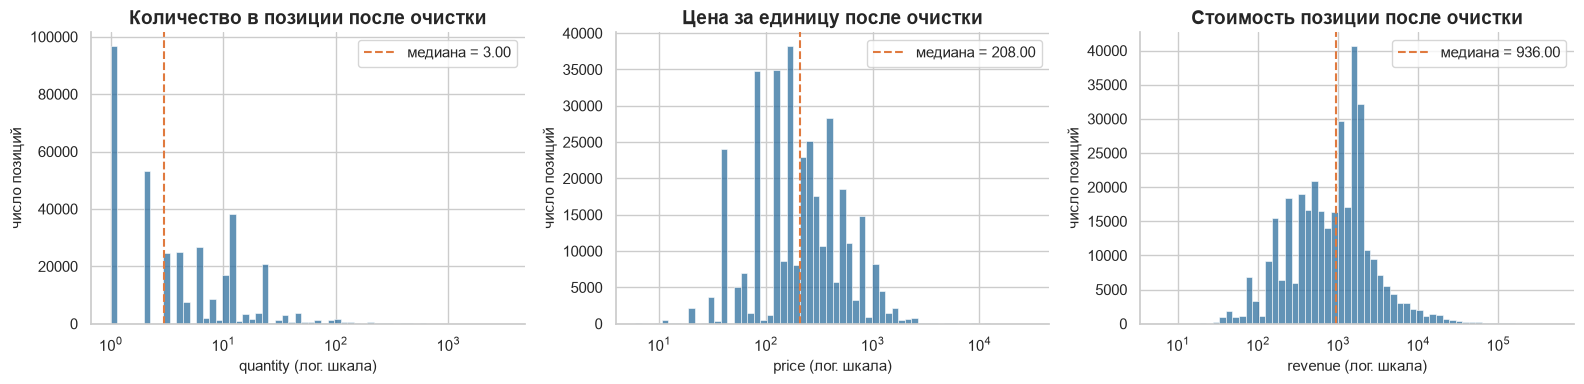

,count,mean,std,min,25%,50%,75%,max
quantity,348 914.00,10.32,36.06,1.00,1.00,3.00,10.00,3 186.00
price,348 914.00,317.48,444.77,6.00,125.00,208.00,413.00,29 500.00
revenue,348 914.00,1 809.62,6 010.21,6.00,375.00,936.00,1 700.00,499 200.00


In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, title in zip(axes, ['quantity', 'price', 'revenue'],
                          ['Количество в позиции', 'Цена за единицу', 'Стоимость позиции']):
    sns.histplot(df[col], bins=60, log_scale=True, ax=ax, color=MAIN)
    ax.axvline(df[col].median(), color=ACCENT, ls='--', label=f'медиана = {num(df[col].median(), 2)}')
    ax.set_title(f'{title} после очистки')
    ax.set_xlabel(f'{col} (лог. шкала)')
    ax.set_ylabel('число позиций')
    ax.legend()
plt.tight_layout()
plt.show()
display(df[['quantity', 'price', 'revenue']].describe().T)

In [24]:
rev_drop = clean_log['выручка'].diff().iloc[1:]
md(f"""**Вывод по очистке.** Удалены отмены, возвраты и списания, позиции с нулевой ценой, служебные записи (видов: **{S['n_services']}**) и ошибочные позиции, подтверждённые проверкой по контексту (строк: **{S['n_errors']}**, {pct(S['excluded_rev_share'], 2)} исходной выручки).
Осталось **{pct(S['rows_kept_step2'])}** строк, **{pct(S['orders_kept_step2'])}** заказов и **{pct(S['rev_kept_step2'])}** выручки от данных после шага 1; больше всего выручки ушло на этапе «{clean_log.loc[rev_drop.idxmin(), 'этап']}».
Крупные оптовые партии и дорогие товары сохранены: самая большая партия в позиции — **{num(df['quantity'].max())} шт.**, самая высокая цена — **{num(df['price'].max())}**.
Типичная товарная позиция — **{num(df['quantity'].median())} шт.** по цене **{num(df['price'].median(), 2)}**,
стоимость позиции — **{num(df['revenue'].median(), 2)}** (медиана). Распределения сильно скошены вправо из-за оптовых покупок,
поэтому дальше вместе со средними будем смотреть и на медианы.""")

**Вывод по очистке.** Удалены отмены, возвраты и списания, позиции с нулевой ценой, служебные записи (видов: **95**) и ошибочные позиции, подтверждённые проверкой по контексту (строк: **1**, 2.46% исходной выручки).
Осталось **98.7%** строк, **90.6%** заказов и **92.3%** выручки от данных после шага 1; больше всего выручки ушло на этапе «4. удалены служебные записи (видов: 95)».
Крупные оптовые партии и дорогие товары сохранены: самая большая партия в позиции — **3 186 шт.**, самая высокая цена — **29 500**.
Типичная товарная позиция — **3 шт.** по цене **208.00**,
стоимость позиции — **936.00** (медиана). Распределения сильно скошены вправо из-за оптовых покупок,
поэтому дальше вместе со средними будем смотреть и на медианы.

### 2.2. Изучение `order_id`, `customer_id`, `name_clust`, `entry_id`, `country_id`

,уникальных значений
order_id (все заказы),"18,677"
customer_id (известные клиенты),"4,240"
name_clust (группы товаров),904
entry_id (товары),"2,807"
country_id (страны),30


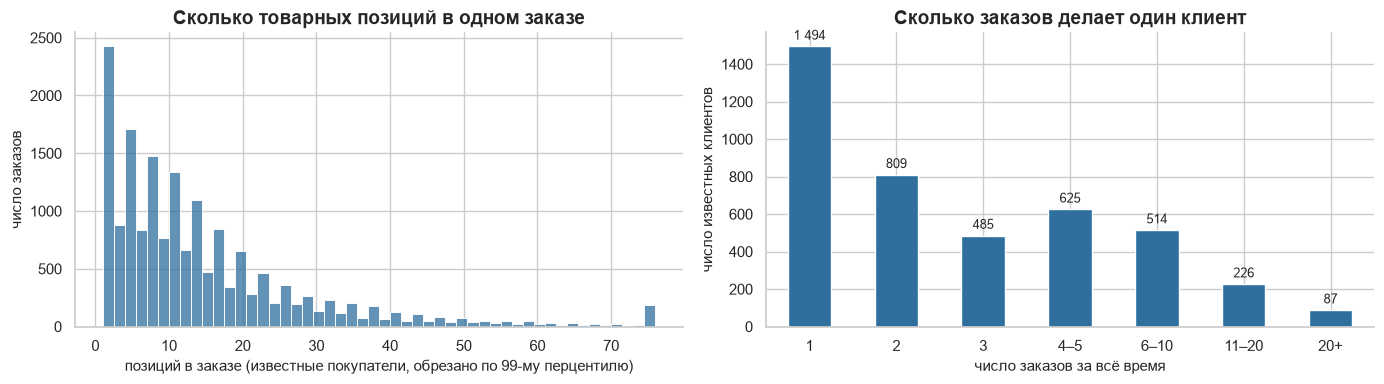

Заказы известных и неизвестных покупателей:


,заказов,позиций_в_среднем,позиций_медиана,сумма_в_среднем,сумма_медиана,выручка,доля заказов,доля выручки
known,,,,,,,,
покупатель неизвестен,"1,272",70.3,29,"77,659","26,861","98,781,664",6.8%,15.6%
известный покупатель,"17,405",14.9,10,"30,601","18,907","532,618,804",93.2%,84.4%


In [25]:
dfc = df[df['known']]   # известные покупатели — для клиентских показателей

summary_ids = pd.DataFrame({
    'уникальных значений': [df['order_id'].nunique(), dfc['customer_id'].nunique(), df['name_clust'].nunique(),
                            df['entry_id'].nunique(), df['country_id'].nunique()]
}, index=['order_id (все заказы)', 'customer_id (известные клиенты)', 'name_clust (группы товаров)', 'entry_id (товары)',
          'country_id (страны)'])
display(summary_ids.style.format('{:,.0f}'))

order_stats = df.groupby('order_id').agg(positions=('entry_id', 'size'), revenue=('revenue', 'sum'), known=('known', 'first'))
order_stats[['positions', 'revenue']] = order_stats[['positions', 'revenue']].astype(float)
known_orders = order_stats[order_stats['known']]
cust_orders = dfc.groupby('customer_id')['order_id'].nunique()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(known_orders['positions'].clip(upper=known_orders['positions'].quantile(.99)), bins=50, ax=axes[0], color=MAIN)
axes[0].set_title('Сколько товарных позиций в одном заказе')
axes[0].set_xlabel('позиций в заказе (известные покупатели, обрезано по 99-му перцентилю)')
axes[0].set_ylabel('число заказов')

orders_bins = pd.cut(cust_orders, [0, 1, 2, 3, 5, 10, 20, np.inf], labels=['1', '2', '3', '4–5', '6–10', '11–20', '20+'])
orders_bins.value_counts().sort_index().plot.bar(ax=axes[1], color=MAIN, rot=0)
annotate_bars(axes[1])
axes[1].set_title('Сколько заказов делает один клиент')
axes[1].set_xlabel('число заказов за всё время')
axes[1].set_ylabel('число известных клиентов')
plt.tight_layout()
plt.show()

by_type = order_stats.groupby('known').agg(заказов=('revenue', 'size'), позиций_в_среднем=('positions', 'mean'),
                                           позиций_медиана=('positions', 'median'), сумма_в_среднем=('revenue', 'mean'),
                                           сумма_медиана=('revenue', 'median'), выручка=('revenue', 'sum'))
by_type.index = by_type.index.map({True: 'известный покупатель', False: 'покупатель неизвестен'})
by_type['доля заказов'] = by_type['заказов'] / by_type['заказов'].sum()
by_type['доля выручки'] = by_type['выручка'] / by_type['выручка'].sum()
print('Заказы известных и неизвестных покупателей:')
display(by_type.style.format({'заказов': '{:,.0f}', 'позиций_в_среднем': '{:.1f}', 'позиций_медиана': '{:.0f}',
                              'сумма_в_среднем': '{:,.0f}', 'сумма_медиана': '{:,.0f}', 'выручка': '{:,.0f}',
                              'доля заказов': '{:.1%}', 'доля выручки': '{:.1%}'}))

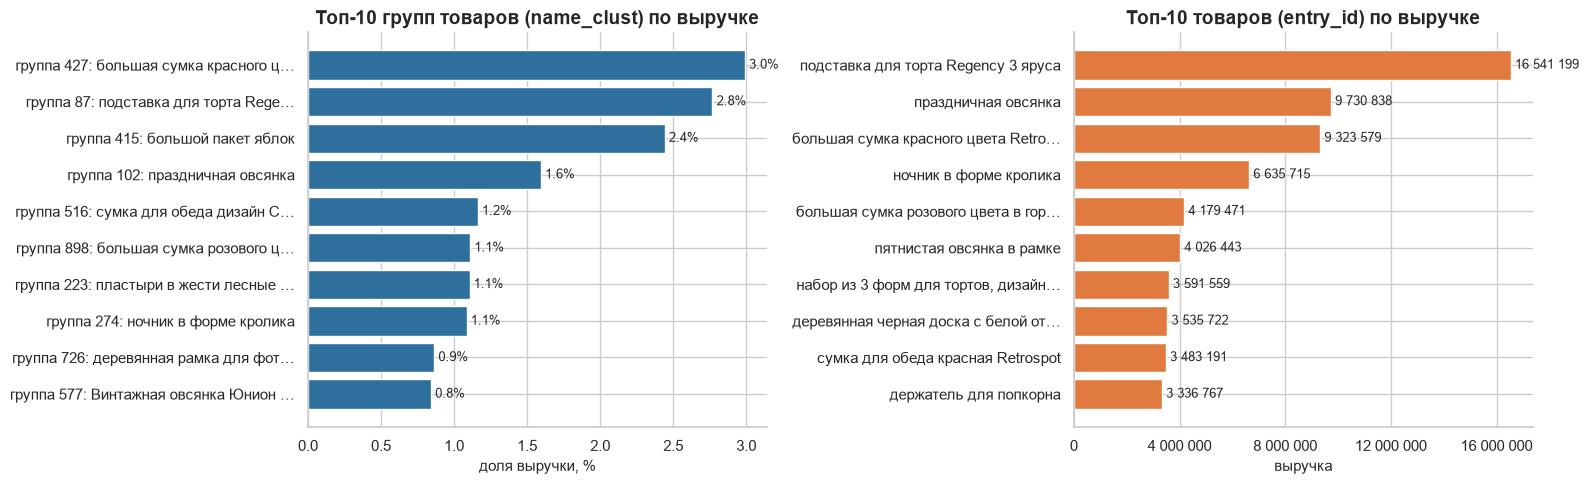

,товаров,заказов,выручка,пример_товара,доля выручки
name_clust,,,,,
427,9,"4,272","18,880,770",большая сумка красного цвета Retrospot,3.0%
87,3,"2,179","17,477,589",подставка для торта Regency 3 яруса,2.8%
415,7,"2,708","15,416,566",большой пакет яблок,2.4%
102,8,"1,971","10,065,288",праздничная овсянка,1.6%
516,4,"2,509","7,336,793",сумка для обеда дизайн Суки,1.2%
898,4,"2,342","7,010,024",большая сумка розового цвета в горошек,1.1%
223,7,"1,771","6,980,441",пластыри в жести лесные животные,1.1%
274,3,"1,054","6,857,729",ночник в форме кролика,1.1%
726,4,"1,756","5,455,747",деревянная рамка для фотографий с белой отделкой,0.9%


In [26]:
names = df.groupby('entry_id')['entry'].first()

clusters = (df.groupby('name_clust')
            .agg(товаров=('entry_id', 'nunique'), заказов=('order_id', 'nunique'), выручка=('revenue', 'sum'),
                 пример_товара=('entry', lambda s: s.value_counts().index[0]))
            .sort_values('выручка', ascending=False))
clusters['доля выручки'] = clusters['выручка'] / clusters['выручка'].sum()

top_products = (df.groupby('entry_id')
                .agg(товар=('entry', 'first'), заказов=('order_id', 'nunique'), штук=('quantity', 'sum'), выручка=('revenue', 'sum'))
                .sort_values('выручка', ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
top_cl = clusters.head(10).iloc[::-1]
axes[0].barh([f'группа {i}: {short(n, 25)}' for i, n in zip(top_cl.index, top_cl['пример_товара'])],
             top_cl['доля выручки'] * 100, color=MAIN)
annotate_bars(axes[0], '{:.1f}%', horizontal=True)
axes[0].set_title('Топ-10 групп товаров (name_clust) по выручке')
axes[0].set_xlabel('доля выручки, %')

top_p = top_products.head(10).iloc[::-1]
axes[1].barh([short(t, 35) for t in top_p['товар']], top_p['выручка'], color=ACCENT)
annotate_bars(axes[1], horizontal=True)
axes[1].set_title('Топ-10 товаров (entry_id) по выручке')
axes[1].set_xlabel('выручка')
thousands(axes[1], 'x')
plt.tight_layout()
plt.show()

display(clusters.head(10).style.format({'товаров': '{:,.0f}', 'заказов': '{:,.0f}', 'выручка': '{:,.0f}', 'доля выручки': '{:.1%}'}))

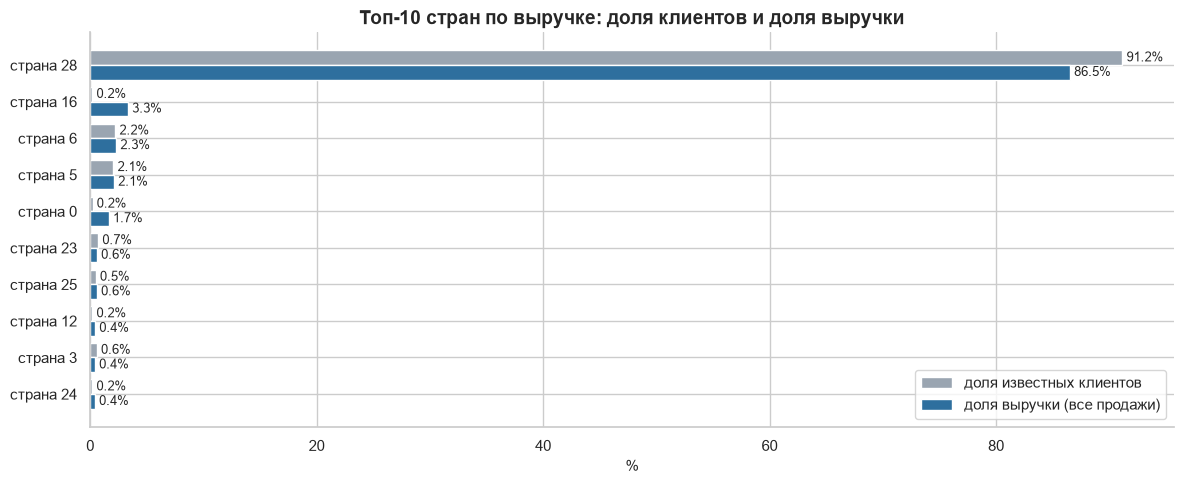

,клиентов,заказов,выручка,доля выручки,доля клиентов
country_id,,,,,
28,"3,865","17,218","546,321,847",86.5%,91.2%
16,8,88,"21,117,838",3.3%,0.2%
6,94,440,"14,501,398",2.3%,2.2%
5,87,377,"13,304,471",2.1%,2.1%
0,9,54,"10,419,001",1.7%,0.2%
23,30,86,"3,785,556",0.6%,0.7%
25,21,50,"3,764,035",0.6%,0.5%
12,8,18,"2,767,619",0.4%,0.2%
3,25,97,"2,680,827",0.4%,0.6%


In [27]:
countries = df.groupby('country_id').agg(заказов=('order_id', 'nunique'), выручка=('revenue', 'sum'))
countries.insert(0, 'клиентов', dfc.groupby('country_id')['customer_id'].nunique().reindex(countries.index, fill_value=0))
countries = countries.sort_values('выручка', ascending=False)
countries['доля выручки'] = countries['выручка'] / countries['выручка'].sum()
countries['доля клиентов'] = countries['клиентов'] / dfc['customer_id'].nunique()

top_c = countries.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(12, 5))
y = np.arange(len(top_c))
ax.barh(y + 0.2, top_c['доля клиентов'] * 100, height=0.4, color=GREY, label='доля известных клиентов')
ax.barh(y - 0.2, top_c['доля выручки'] * 100, height=0.4, color=MAIN, label='доля выручки (все продажи)')
ax.set_yticks(y)
ax.set_yticklabels([f'страна {c}' for c in top_c.index])
annotate_bars(ax, '{:.1f}%', horizontal=True)
ax.set_title('Топ-10 стран по выручке: доля клиентов и доля выручки')
ax.set_xlabel('%')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

display(countries.head(10).style.format({'клиентов': '{:,.0f}', 'заказов': '{:,.0f}', 'выручка': '{:,.0f}',
                                         'доля выручки': '{:.1%}', 'доля клиентов': '{:.1%}'}))

In [28]:
main_country = countries.index[0]
S['main_country'], S['main_country_share'] = main_country, countries['доля выручки'].iloc[0]
k_row = by_type.loc['известный покупатель']
unk_txt = ''
if 'покупатель неизвестен' in by_type.index:
    u_row = by_type.loc['покупатель неизвестен']
    ratio = u_row['позиций_в_среднем'] / k_row['позиций_в_среднем']
    S['unknown_positions_ratio'] = ratio
    unk_txt = (f"- Заказы неизвестных покупателей — **{pct(u_row['доля заказов'])}** заказов и **{pct(u_row['доля выручки'])}** выручки. "
               f"В среднем в них **{u_row['позиций_в_среднем']:.0f}** позиций против **{k_row['позиций_в_среднем']:.0f}** у известных покупателей"
               + (f" (в {ratio:.1f} раза больше) — это похоже на сводные выгрузки розничных продаж, а не на отдельные заказы. " if ratio > 2 else ". ")
               + "Их выручку учитываем в общих показателях продаж, но в клиентские метрики и в расчёты среднего чека они не входят.")
md(f"""**Вывод по идентификаторам.**
- В очищенных данных **{num(df['order_id'].nunique())}** заказов, **{num(df['entry_id'].nunique())}** товаров, объединённых в **{num(df['name_clust'].nunique())}** групп по названию, и **{num(df['country_id'].nunique())}** стран; известных клиентов — **{num(dfc['customer_id'].nunique())}**.
{unk_txt}
- В типичном заказе известного покупателя **{num(k_row['позиций_медиана'])}** товарных позиций, медианная сумма заказа — **{num(k_row['сумма_медиана'], 2)}**.
- **{pct((cust_orders == 1).mean())}** известных клиентов сделали только один заказ, остальные возвращались.
- Продажи сильно сконцентрированы географически: на страну **{main_country}** приходится **{pct(S['main_country_share'])}** выручки —
  по-видимому, это домашний рынок магазина. Топ-10 групп товаров дают **{pct(clusters['доля выручки'].head(10).sum())}** выручки.""")

**Вывод по идентификаторам.**
- В очищенных данных **18 677** заказов, **2 807** товаров, объединённых в **904** групп по названию, и **30** стран; известных клиентов — **4 240**.
- Заказы неизвестных покупателей — **6.8%** заказов и **15.6%** выручки. В среднем в них **70** позиций против **15** у известных покупателей (в 4.7 раза больше) — это похоже на сводные выгрузки розничных продаж, а не на отдельные заказы. Их выручку учитываем в общих показателях продаж, но в клиентские метрики и в расчёты среднего чека они не входят.
- В типичном заказе известного покупателя **10** товарных позиций, медианная сумма заказа — **18 907.00**.
- **35.2%** известных клиентов сделали только один заказ, остальные возвращались.
- Продажи сильно сконцентрированы географически: на страну **28** приходится **86.5%** выручки —
  по-видимому, это домашний рынок магазина. Топ-10 групп товаров дают **16.0%** выручки.

<div class="alert alert-success">
<b>✔️ Комментарий ревьюера v1:</b>
<br>
Исследование идентификаторов дополнено содержанием: товарные группы сопоставлены с примерами товаров, заказами и выручкой. Благодаря этому name_clust рассматривается как характеристика ассортимента, а не просто числовой столбец.
</div>

### 2.3. Полнота данных во времени

Посчитаем по каждому месяцу, сколько календарных дней прошло без единой продажи. Дни, не покрытые выгрузкой (в начале первого и в конце последнего месяца), тоже считаются днями без продаж — так сразу видно, какие месяцы выгружены не полностью.

,дней_в_месяце,дней_без_продаж,заказов,дней_с_продажами
дек 2018,31,11,1444,20
янв 2019,31,7,1031,24
фев 2019,28,4,1037,24
мар 2019,31,4,1364,27
апр 2019,30,9,1183,21
май 2019,31,6,1586,25
июн 2019,30,4,1433,26
июл 2019,31,5,1356,26
авг 2019,31,5,1266,26
сен 2019,30,4,1712,26


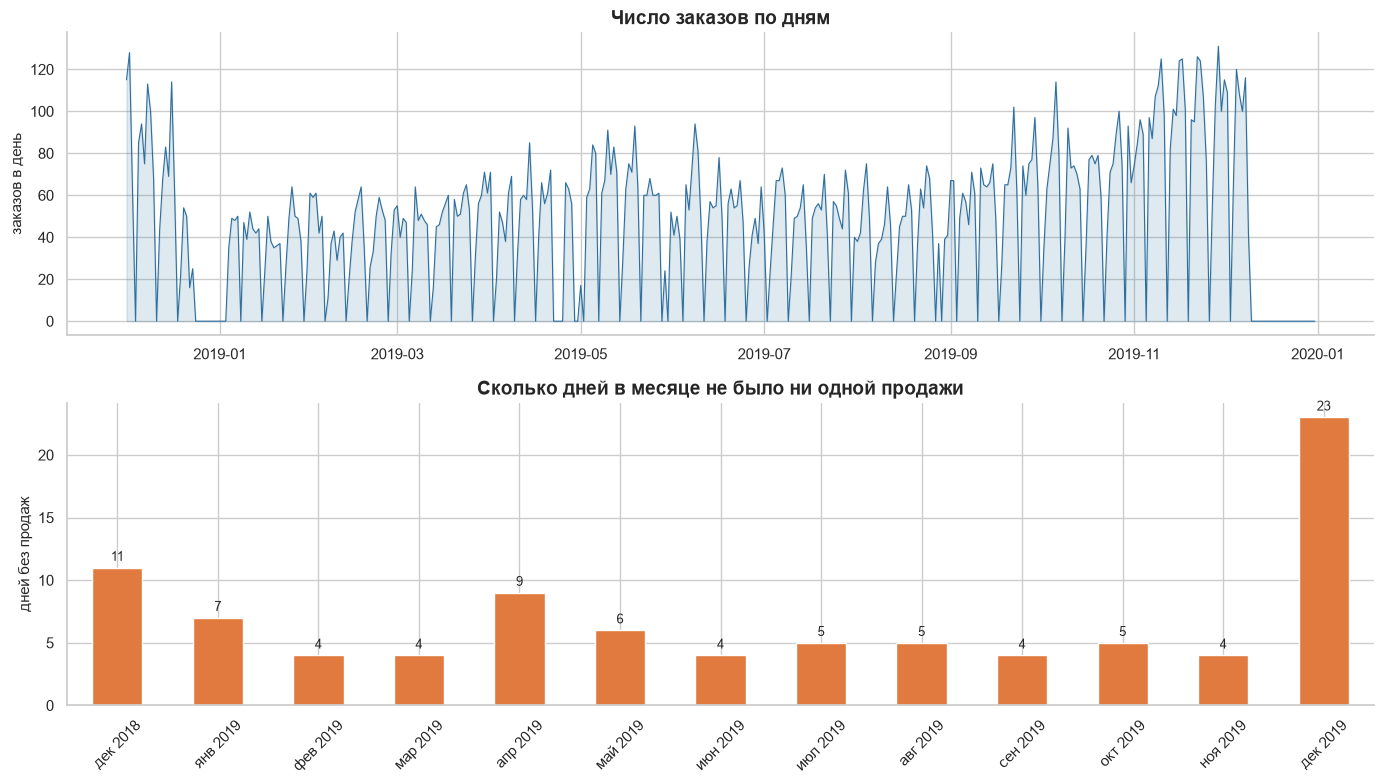

Дни без продаж по дням недели: {'Пн': 7, 'Вт': 57, 'Ср': 6, 'Чт': 9, 'Пт': 4, 'Сб': 4, 'Вс': 4}


In [29]:
day = df['entry_date'].dt.normalize()
daily_orders = df.groupby(day)['order_id'].nunique()
start = daily_orders.index.min().to_period('M').to_timestamp()
end = daily_orders.index.max().to_period('M').to_timestamp(how='end').normalize()
daily_full = daily_orders.reindex(pd.date_range(start, end, freq='D'), fill_value=0)

gaps = pd.DataFrame({'orders': daily_full, 'month': daily_full.index.to_period('M')})
monthly_gaps = gaps.groupby('month').agg(дней_в_месяце=('orders', 'size'),
                                         дней_без_продаж=('orders', lambda s: (s == 0).sum()),
                                         заказов=('orders', 'sum'))
monthly_gaps['дней_с_продажами'] = monthly_gaps['дней_в_месяце'] - monthly_gaps['дней_без_продаж']
monthly_gaps.index = [month_label(p) for p in monthly_gaps.index]
display(monthly_gaps)

fig, axes = plt.subplots(2, 1, figsize=(14, 8))
axes[0].plot(daily_full.index, daily_full.values, color=MAIN, lw=0.8)
axes[0].fill_between(daily_full.index, daily_full.values, color=MAIN, alpha=0.15)
axes[0].set_title('Число заказов по дням')
axes[0].set_ylabel('заказов в день')

monthly_gaps['дней_без_продаж'].plot.bar(ax=axes[1], color=ACCENT, rot=45)
annotate_bars(axes[1])
axes[1].set_title('Сколько дней в месяце не было ни одной продажи')
axes[1].set_ylabel('дней без продаж')
plt.tight_layout()
plt.show()

weekday_share_zero = (daily_full[daily_full == 0].index.weekday.value_counts().reindex(range(7), fill_value=0))
weekday_share_zero.index = WEEKDAYS_RU
print('Дни без продаж по дням недели:', {k: int(v) for k, v in weekday_share_zero.items()})

**Выбор периода.** Месяц считаем полноценным, если в нём продажи были хотя бы в половине от медианного числа «торговых» дней и заказов было не меньше трети от медианного месячного объёма. Берём непрерывный отрезок от первого до последнего полноценного месяца — так исключаются «обрывки» выгрузки по краям, которые занизили бы месячные метрики.

In [30]:
mg = gaps.groupby('month').agg(days_sales=('orders', lambda s: (s > 0).sum()), orders=('orders', 'sum'))
good = mg[(mg['days_sales'] >= 0.5 * mg['days_sales'].median()) & (mg['orders'] >= mg['orders'].median() / 3)].index
PERIOD_START = good.min().to_timestamp()
PERIOD_END = (good.max() + 1).to_timestamp()          # не включительно

rows_before, rev_before = len(df), df['revenue'].sum()
df = df[(df['entry_date'] >= PERIOD_START) & (df['entry_date'] < PERIOD_END)].reset_index(drop=True)
S['period'] = f'{month_label(good.min())} — {month_label(good.max())}'
print(f'Период анализа: {PERIOD_START:%d.%m.%Y} — {(PERIOD_END - pd.Timedelta(days=1)):%d.%m.%Y} ({len(good)} мес.)')
print(f'Сохранено строк: {pct(len(df) / rows_before)}, выручки: {pct(df["revenue"].sum() / rev_before)}')

Период анализа: 01.12.2018 — 30.11.2019 (12 мес.)
Сохранено строк: 95.2%, выручки: 95.5%


In [31]:
md(f"""**Вывод по полноте данных.** Данные охватывают период с **{daily_orders.index.min():%d.%m.%Y}** по **{daily_orders.index.max():%d.%m.%Y}**.
Внутри месяцев регулярно встречаются дни без продаж, чаще всего это **{weekday_share_zero.idxmax()}**
({weekday_share_zero.max()} таких дней из {weekday_share_zero.sum()}). По-видимому, в этот день недели магазин не работает, а остальные пропуски — праздничные перерывы.
Это предположение: расписания магазина в данных нет.
Крайние месяцы выгрузки неполные, поэтому для анализа оставлен период **{S['period']}** — он содержит основную часть данных
({pct(len(df) / rows_before)} строк). Дальше работаем только с ним.""")

**Вывод по полноте данных.** Данные охватывают период с **01.12.2018** по **09.12.2019**.
Внутри месяцев регулярно встречаются дни без продаж, чаще всего это **Вт**
(57 таких дней из 91). По-видимому, в этот день недели магазин не работает, а остальные пропуски — праздничные перерывы.
Это предположение: расписания магазина в данных нет.
Крайние месяцы выгрузки неполные, поэтому для анализа оставлен период **дек 2018 — ноя 2019** — он содержит основную часть данных
(95.2% строк). Дальше работаем только с ним.

<div class="alert alert-success">
<b>✔️ Комментарий ревьюера v1:</b>
<br>
Непрерывный календарь позволяет учитывать и полностью отсутствующие месяцы, а критерии выбора периода записаны явно. Это делает решение проверяемым и помогает отделять неполноту выгрузки от динамики продаж.
</div>

## Шаг 3. Расчёт метрик

### 3.1. Активность покупателей по часам и дням недели

Считаем **число заказов** (уникальные `order_id` — все заказы, это показатель продаж) и **число уникальных покупателей** в каждом часе и в каждом дне недели за весь период. Покупателей считаем только известных: `-1` объединяет разных людей и считался бы одним покупателем.

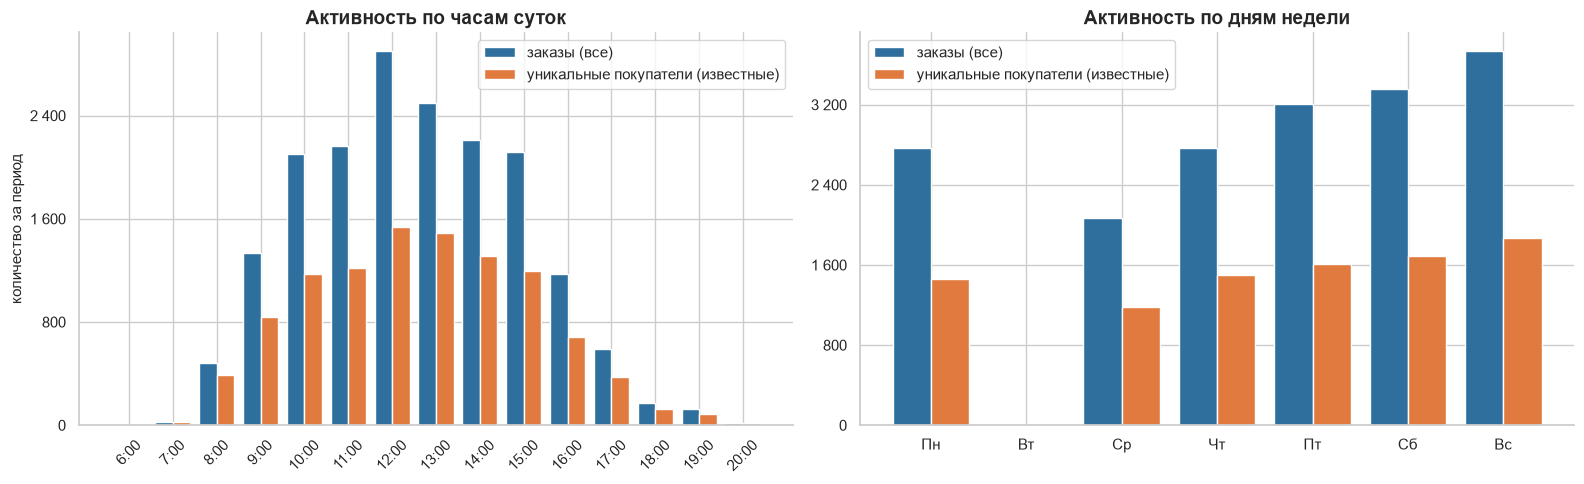

,Пн,Вт,Ср,Чт,Пт,Сб,Вс
заказов,2 764.00,0.00,2 070.00,2 763.00,3 210.00,3 361.00,3 734.00
покупателей,1 456.00,0.00,1 181.00,1 498.00,1 609.00,1 689.00,1 868.00
заказов в среднем за день,53.15,0.00,39.81,53.13,61.73,63.42,71.81


In [32]:
df['hour'] = df['entry_date'].dt.hour
df['weekday'] = df['entry_date'].dt.weekday
df['date'] = df['entry_date'].dt.normalize()
df['month'] = df['entry_date'].dt.to_period('M')
dfc = df[df['known']].copy()   # известные покупатели (пересоздаём после выбора периода и новых столбцов)

by_hour = (df.groupby('hour').agg(заказов=('order_id', 'nunique'))
           .join(dfc.groupby('hour').agg(покупателей=('customer_id', 'nunique')))
           .reindex(range(24)).fillna(0))
by_wd = (df.groupby('weekday').agg(заказов=('order_id', 'nunique'))
         .join(dfc.groupby('weekday').agg(покупателей=('customer_id', 'nunique')))
         .reindex(range(7)).fillna(0))
# число календарных дней каждого дня недели в периоде — чтобы посчитать среднее на один такой день
n_wd = pd.Series(pd.date_range(PERIOD_START, PERIOD_END - pd.Timedelta(days=1)).weekday).value_counts().reindex(range(7), fill_value=0)
by_wd['заказов в среднем за день'] = by_wd['заказов'] / n_wd
by_wd.index = WEEKDAYS_RU

hours_active = by_hour[by_hour['заказов'] > 0].index
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
x = np.arange(hours_active.min(), hours_active.max() + 1)
axes[0].bar(x - 0.2, by_hour.loc[x, 'заказов'], width=0.4, color=MAIN, label='заказы (все)')
axes[0].bar(x + 0.2, by_hour.loc[x, 'покупателей'], width=0.4, color=ACCENT, label='уникальные покупатели (известные)')
axes[0].set_xticks(x)
axes[0].set_xticklabels([f'{h}:00' for h in x], rotation=45)
axes[0].set_title('Активность по часам суток')
axes[0].set_ylabel('количество за период')
axes[0].legend()
thousands(axes[0])

xw = np.arange(7)
axes[1].bar(xw - 0.2, by_wd['заказов'], width=0.4, color=MAIN, label='заказы (все)')
axes[1].bar(xw + 0.2, by_wd['покупателей'], width=0.4, color=ACCENT, label='уникальные покупатели (известные)')
axes[1].set_xticks(xw)
axes[1].set_xticklabels(WEEKDAYS_RU)
axes[1].set_title('Активность по дням недели')
axes[1].legend()
thousands(axes[1])
plt.tight_layout()
plt.show()

display(by_wd.T)

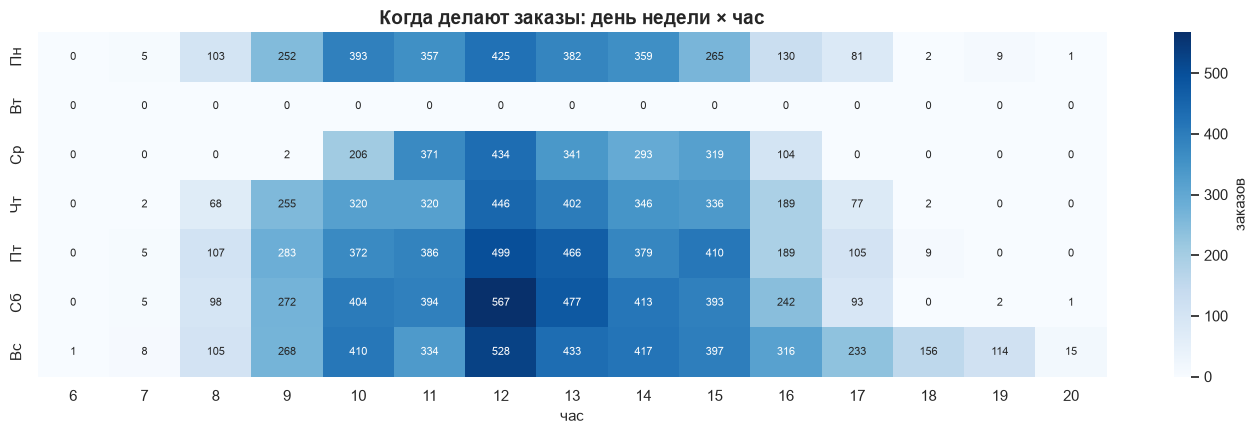

In [33]:
heat = (df.groupby(['weekday', 'hour'])['order_id'].nunique().unstack(fill_value=0)
        .reindex(index=range(7), fill_value=0))
heat = heat.loc[:, heat.sum() > 0]
heat.index = WEEKDAYS_RU
fig, ax = plt.subplots(figsize=(14, 4.5))
sns.heatmap(heat, cmap='Blues', annot=True, fmt='d', annot_kws={'size': 8}, cbar_kws={'label': 'заказов'}, ax=ax)
ax.set_title('Когда делают заказы: день недели × час')
ax.set_xlabel('час')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

In [34]:
peak_hours = by_hour['заказов'].nlargest(3).index.sort_values()
core = by_hour.loc[10:15, 'заказов'].sum() / by_hour['заказов'].sum()
zero_days = by_wd.index[by_wd['заказов'] == 0].tolist()
S['peak_hours'] = f'{peak_hours.min()}:00–{peak_hours.max() + 1}:00'
S['best_weekday'] = by_wd['заказов в среднем за день'].idxmax()
S['zero_days'] = zero_days
md(f"""**Вывод: цикличность есть, и она выраженная.**
- **Внутри дня.** Заказы идут в «офисное» время: с {hours_active.min()}:00 до {hours_active.max() + 1}:00, пик — **{S['peak_hours']}**.
  На интервал 10:00–16:00 приходится **{pct(core)}** заказов. Это похоже на поведение оптовых и корпоративных клиентов, которые заказывают в рабочее время.
- **Внутри недели.** Больше всего заказов в среднем за день — в **{S['best_weekday']}**, меньше всего — в **{by_wd.loc[by_wd['заказов'] > 0, 'заказов в среднем за день'].idxmin()}**.
  {('В ' + ', '.join(zero_days) + ' заказов нет совсем — вероятно, магазин в этот день не работает или не принимает заказы. Это предположение: расписания магазина в данных нет.') if zero_days else 'Заказы есть во все дни недели.'}
- Графики заказов и покупателей идут почти параллельно: обычно покупатель делает один заказ за визит, поэтому пик активности — это пик притока клиентов.
- **Для бизнеса:** рассылки и акции лучше запускать утром в будни, чтобы они попадали в пиковые часы; технические работы на сайте — проводить вечером и в день, когда заказов нет.""")

**Вывод: цикличность есть, и она выраженная.**
- **Внутри дня.** Заказы идут в «офисное» время: с 6:00 до 21:00, пик — **12:00–15:00**.
  На интервал 10:00–16:00 приходится **78.2%** заказов. Это похоже на поведение оптовых и корпоративных клиентов, которые заказывают в рабочее время.
- **Внутри недели.** Больше всего заказов в среднем за день — в **Вс**, меньше всего — в **Ср**.
  В Вт заказов нет совсем — вероятно, магазин в этот день не работает или не принимает заказы. Это предположение: расписания магазина в данных нет.
- Графики заказов и покупателей идут почти параллельно: обычно покупатель делает один заказ за визит, поэтому пик активности — это пик притока клиентов.
- **Для бизнеса:** рассылки и акции лучше запускать утром в будни, чтобы они попадали в пиковые часы; технические работы на сайте — проводить вечером и в день, когда заказов нет.

<div class="alert alert-success">
<b>✔️ Комментарий ревьюера v1:</b>
<br>
Заказы считаются по уникальным order_id, а тепловая карта дополняет отдельные графики часов и дней недели. Такое сочетание позволяет увидеть, как меняется активность на пересечении двух временных признаков.
</div>


### 3.2. Средняя выручка с клиента в день и число покупателей по месяцам

**Средняя выручка с клиента в день** = для каждого дня выручка дня ÷ число уникальных покупателей в этот день, затем среднее по дням месяца. Метрика показывает, сколько в среднем приносит один покупатель в день покупки, и не зависит от числа рабочих дней в месяце.

Метрика клиентская, поэтому и выручка дня (числитель), и число покупателей (знаменатель) считаются по одной аудитории — **известным покупателям**. Общая выручка месяца по всем продажам, включая неизвестных покупателей, показана в таблице отдельным столбцом.

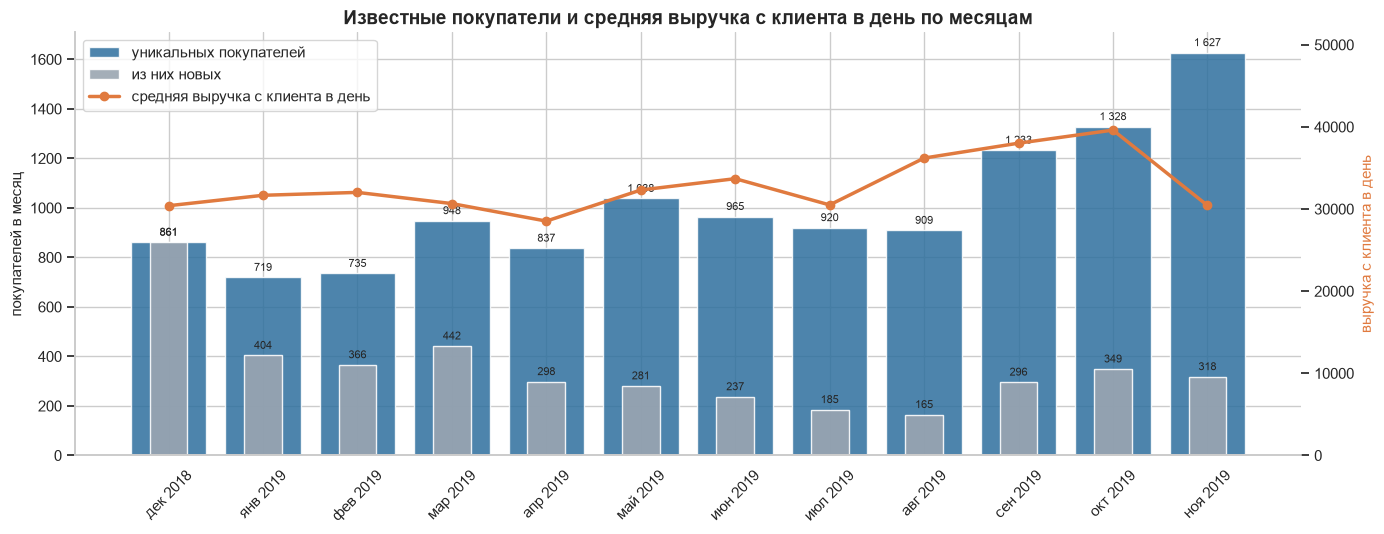

,средняя_выручка_с_клиента_в_день,выручка_известных_покупателей,выручка_всего,уникальных_покупателей,новых_покупателей
дек 2018,"30,402","34,790,342","47,299,023",861,861
янв 2019,"31,672","28,922,602","36,002,663",719,404
фев 2019,"32,025","28,597,824","32,897,039",735,366
мар 2019,"30,662","36,459,429","43,722,666",948,442
апр 2019,"28,530","29,375,879","33,681,451",837,298
май 2019,"32,315","42,608,259","48,162,545","1,038",281
июн 2019,"33,696","39,495,180","45,308,119",965,237
июл 2019,"30,499","35,535,189","42,242,677",920,185
авг 2019,"36,202","42,842,723","49,056,568",909,165
сен 2019,"38,018","57,202,329","63,328,880","1,233",296


В первый месяц периода все покупатели считаются новыми: история до начала выгрузки неизвестна.


In [35]:
# клиентская метрика: и выручка дня, и число покупателей — по известным покупателям
daily = dfc.groupby('date').agg(выручка=('revenue', 'sum'), покупателей=('customer_id', 'nunique'))
daily['выручка_на_клиента'] = daily['выручка'] / daily['покупателей']
daily['month'] = daily.index.to_period('M')

monthly = daily.groupby('month').agg(средняя_выручка_с_клиента_в_день=('выручка_на_клиента', 'mean'),
                                     выручка_известных_покупателей=('выручка', 'sum'))
monthly['выручка_всего'] = df.groupby('month')['revenue'].sum()
monthly['уникальных_покупателей'] = dfc.groupby('month')['customer_id'].nunique()
monthly['новых_покупателей'] = dfc.groupby('customer_id')['month'].min().value_counts().reindex(monthly.index, fill_value=0)
labels = [month_label(p) for p in monthly.index]

fig, ax1 = plt.subplots(figsize=(14, 5.5))
bars = ax1.bar(labels, monthly['уникальных_покупателей'], color=MAIN, alpha=0.85, label='уникальных покупателей')
ax1.bar(labels, monthly['новых_покупателей'], color=GREY, alpha=0.9, width=0.4, label='из них новых')
ax1.set_ylabel('покупателей в месяц')
annotate_bars(ax1, fontsize=8)
ax2 = ax1.twinx()
ax2.plot(labels, monthly['средняя_выручка_с_клиента_в_день'], color=ACCENT, marker='o', lw=2.5,
         label='средняя выручка с клиента в день')
ax2.set_ylabel('выручка с клиента в день', color=ACCENT)
ax2.set_ylim(0, monthly['средняя_выручка_с_клиента_в_день'].max() * 1.3)
ax2.grid(False)
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='upper left')
ax1.set_title('Известные покупатели и средняя выручка с клиента в день по месяцам')
plt.setp(ax1.get_xticklabels(), rotation=45)
plt.tight_layout()
plt.show()

monthly_show = monthly.copy()
monthly_show.index = labels
display(monthly_show.style.format('{:,.0f}'))
print('В первый месяц периода все покупатели считаются новыми: история до начала выгрузки неизвестна.')

In [36]:
mc = monthly['уникальных_покупателей']
arpu_d = monthly['средняя_выручка_с_клиента_в_день']
first_half = mc.iloc[:len(mc) // 2].mean()
second_half = mc.iloc[len(mc) // 2:].mean()
S['best_month'] = month_label(mc.idxmax())
S['cust_growth'] = mc.max() / mc.min() - 1
md(f"""**Вывод о сезонности.**
- Число покупателей в месяц меняется от **{num(mc.min())}** ({month_label(mc.idxmin())}) до **{num(mc.max())}** ({S['best_month']}),
  то есть в лучший месяц покупателей на **{pct(S['cust_growth'], 0)}** больше, чем в худший.
  Во второй половине периода покупателей в среднем **{'больше' if second_half > first_half else 'меньше'}**, чем в первой ({num(second_half)} против {num(first_half)}).
- Средняя выручка с клиента в день колеблется в диапазоне **{num(arpu_d.min())}–{num(arpu_d.max())}** и меняется заметно слабее, чем число покупателей:
  рост выручки в сильные месяцы обеспечивается прежде всего **притоком покупателей**, а не ростом чека.
- {'Пик приходится на предпраздничный период (осень — начало зимы) — это ожидаемо для магазина подарков: клиенты, включая оптовиков, закупаются к Рождеству и Новому году.' if mc.idxmax().month in (9, 10, 11, 12) else 'Пик приходится не на предпраздничный период, что для магазина подарков неожиданно — стоит уточнить у бизнеса, не было ли в этот месяц акций или крупных клиентов.'}
  Но данных всего за один год: отличить устойчивую сезонность от разового роста бизнеса нельзя — для уверенного вывода нужна история минимум за 2–3 года.""")

**Вывод о сезонности.**
- Число покупателей в месяц меняется от **719** (янв 2019) до **1 627** (ноя 2019),
  то есть в лучший месяц покупателей на **126%** больше, чем в худший.
  Во второй половине периода покупателей в среднем **больше**, чем в первой (1 164 против 856).
- Средняя выручка с клиента в день колеблется в диапазоне **28 530–39 611** и меняется заметно слабее, чем число покупателей:
  рост выручки в сильные месяцы обеспечивается прежде всего **притоком покупателей**, а не ростом чека.
- Пик приходится на предпраздничный период (осень — начало зимы) — это ожидаемо для магазина подарков: клиенты, включая оптовиков, закупаются к Рождеству и Новому году.
  Но данных всего за один год: отличить устойчивую сезонность от разового роста бизнеса нельзя — для уверенного вывода нужна история минимум за 2–3 года.

<div class="alert alert-success">
<b>✔️ Комментарий ревьюера v1:</b>
<br>
Средняя дневная выручка рассчитывается через усреднение дневных отношений, а месячная аудитория определяется отдельно. Это сохраняет смысл двух разных показателей. Ограничение выводов о сезонности одним годом также обозначено корректно.
</div>


### 3.3. Sticky factor за II и III кварталы 2019 года

**Sticky factor** («липкость») = DAU / MAU — какая доля месячной аудитории приходит в магазин в среднестатистический день. Аудиторию считаем только по известным покупателям.
- DAU — среднее число уникальных покупателей за день (по дням с продажами: дни без единого заказа, вероятно нерабочие, искусственно занизили бы метрику);
- MAU — среднее число уникальных покупателей за месяц квартала.

Для полноты добавим DAU / WAU (WAU — уникальные покупатели за неделю).

,DAU,WAU,MAU,sticky DAU/MAU,sticky DAU/WAU,покупателей за квартал
2019Q2,48.7,259.4,946.7,5.14%,18.77%,"1,950"
2019Q3,48.6,261.2,1020.7,4.76%,18.59%,"2,105"


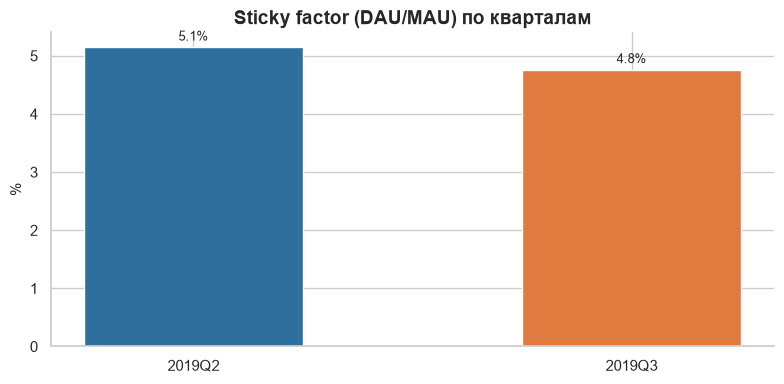

In [37]:
def sticky(q):
    sub = dfc[dfc['entry_date'].dt.to_period('Q') == pd.Period(q, freq='Q')]   # только известные покупатели
    if sub.empty:
        return None
    dau = sub.groupby('date')['customer_id'].nunique().mean()
    wau = sub.groupby(sub['entry_date'].dt.to_period('W'))['customer_id'].nunique().mean()
    mau = sub.groupby('month')['customer_id'].nunique().mean()
    return {'DAU': dau, 'WAU': wau, 'MAU': mau, 'sticky DAU/MAU': dau / mau, 'sticky DAU/WAU': dau / wau,
            'покупателей за квартал': sub['customer_id'].nunique()}


quarters = ['2019Q2', '2019Q3']
sticky_tbl = pd.DataFrame({q: sticky(q) for q in quarters if sticky(q) is not None}).T
if len(sticky_tbl) < 2:
    print('Внимание: в периоде анализа нет одного из кварталов 2019 года')
display(sticky_tbl.style.format({'DAU': '{:.1f}', 'WAU': '{:.1f}', 'MAU': '{:.1f}', 'sticky DAU/MAU': '{:.2%}',
                                 'sticky DAU/WAU': '{:.2%}', 'покупателей за квартал': '{:,.0f}'}))

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(sticky_tbl.index, sticky_tbl['sticky DAU/MAU'] * 100, color=[MAIN, ACCENT][:len(sticky_tbl)], width=0.5)
annotate_bars(ax, '{:.1f}%')
ax.set_title('Sticky factor (DAU/MAU) по кварталам')
ax.set_ylabel('%')
plt.tight_layout()
plt.show()

In [38]:
S['sticky'] = sticky_tbl['sticky DAU/MAU'].to_dict()
q2, q3 = (sticky_tbl['sticky DAU/MAU'].get(q, np.nan) for q in quarters)
md(f"""**Вывод.** Sticky factor во II квартале — **{pct(q2)}**, в III квартале — **{pct(q3)}**
({'вырос' if q3 > q2 else 'снизился'} на {abs(q3 - q2) * 100:.1f} п.п.). Это значит, что в обычный день с продажами в магазине покупает
около {pct((q2 + q3) / 2, 0)} покупателей, которые купят что-то в течение месяца.
Оценить по этим данным, высокая это липкость или низкая, нельзя: нужен ориентир — тот же показатель у похожих магазинов или у этого магазина в прошлые годы.
Можно предположить, что значение связано с характером покупок (подарки покупают по поводу, оптовики пополняют склад периодически), но это гипотеза, а не вывод из данных.
Метрику полезнее отслеживать в динамике: её рост означает, что клиенты стали возвращаться чаще.""")

**Вывод.** Sticky factor во II квартале — **5.1%**, в III квартале — **4.8%**
(снизился на 0.4 п.п.). Это значит, что в обычный день с продажами в магазине покупает
около 5% покупателей, которые купят что-то в течение месяца.
Оценить по этим данным, высокая это липкость или низкая, нельзя: нужен ориентир — тот же показатель у похожих магазинов или у этого магазина в прошлые годы.
Можно предположить, что значение связано с характером покупок (подарки покупают по поводу, оптовики пополняют склад периодически), но это гипотеза, а не вывод из данных.
Метрику полезнее отслеживать в динамике: её рост означает, что клиенты стали возвращаться чаще.

<div class="alert alert-success">
<b>✔️ Комментарий ревьюера v1:</b>
<br>
Дневная и месячная аудитории рассчитываются отдельно, а кварталы выбираются через календарные периоды. Это позволяет получить требуемое соотношение DAU/MAU без подмены месячной аудитории квартальной.
</div>

### 3.4. Профиль клиента

Сначала соберём таблицу заказов (одна строка — один заказ), затем по ней — профиль каждого **известного** клиента (заказы с `customer_id = -1` в профили не входят):

| Показатель | Что значит |
|---|---|
| `orders` | число заказов |
| `first_order`, `last_order` | дата первого и последнего заказа |
| `revenue` | общая сумма всех заказов |
| `aov` | средняя стоимость заказа (средний чек) |
| `avg_items`, `avg_positions` | среднее число штук и товарных позиций в заказе |
| `unique_products` | сколько разных товаров купил клиент |
| `lifetime_days` | дней между первым и последним заказом |
| `avg_days_between` | средний интервал между заказами (для возвратных) |
| `recency` | дней с последнего заказа до конца периода |
| `country_id` | страна, в которую клиент заказывал чаще всего |

In [39]:
orders_all = (df.groupby('order_id')
              .agg(customer_id=('customer_id', 'first'), known=('known', 'first'), order_date=('entry_date', 'min'),
                   revenue=('revenue', 'sum'), items=('quantity', 'sum'), positions=('entry_id', 'nunique'),
                   country_id=('country_id', 'first'))
              .reset_index())
orders_all['quarter'] = orders_all['order_date'].dt.to_period('Q')
orders = orders_all[orders_all['known']].reset_index(drop=True)   # заказы известных покупателей

SNAPSHOT = PERIOD_END   # день после окончания периода анализа

profile = orders.groupby('customer_id').agg(
    orders=('order_id', 'nunique'),
    first_order=('order_date', 'min'),
    last_order=('order_date', 'max'),
    revenue=('revenue', 'sum'),
    aov=('revenue', 'mean'),
    avg_items=('items', 'mean'),
    avg_positions=('positions', 'mean'),
)
profile['unique_products'] = dfc.groupby('customer_id')['entry_id'].nunique()
profile['country_id'] = dfc.groupby('customer_id')['country_id'].agg(lambda s: s.mode().iat[0])
profile['lifetime_days'] = (profile['last_order'] - profile['first_order']).dt.days
profile['avg_days_between'] = np.where(profile['orders'] > 1, profile['lifetime_days'] / (profile['orders'] - 1), np.nan)
profile['recency'] = (SNAPSHOT - profile['last_order']).dt.days
profile['is_returning'] = profile['orders'] > 1
profile['тип клиента'] = np.where(profile['is_returning'], 'возвратный', 'разовый')

print(f'Профилей клиентов: {num(len(profile))}; «клиент» {UNKNOWN_ID} в профилях есть: {UNKNOWN_ID in profile.index}')
display(profile.head(10))
display(profile.describe().T)

Профилей клиентов: 4 202; «клиент» -1 в профилях есть: False


,orders,first_order,last_order,revenue,aov,avg_items,avg_positions,unique_products,country_id,lifetime_days,avg_days_between,recency,is_returning,тип клиента
customer_id,,,,,,,,,,,,,,
1713,3,2019-05-22 10:39:00,2019-10-28 09:29:00,128 270.00,42 756.67,328.67,15.33,39,28,158,79.00,33,True,возвратный
1717,13,2019-01-06 14:14:00,2019-11-30 12:59:00,133 711.00,10 285.46,72.92,38.00,196,28,327,27.25,0,True,возвратный
1718,1,2019-08-05 13:35:00,2019-08-05 13:35:00,7 062.00,7 062.00,58.00,5.00,5,28,0,NaN,117,False,разовый
1719,1,2019-06-12 10:53:00,2019-06-12 10:53:00,8 082.00,8 082.00,54.00,7.00,7,28,0,NaN,171,False,разовый
1720,1,2019-03-07 09:52:00,2019-03-07 09:52:00,13 290.00,13 290.00,35.00,7.00,7,28,0,NaN,268,False,разовый
1722,1,2019-09-27 11:58:00,2019-09-27 11:58:00,12 690.00,12 690.00,38.00,6.00,6,28,0,NaN,64,False,разовый
1723,1,2019-10-12 15:22:00,2019-10-12 15:22:00,2 806.00,2 806.00,40.00,3.00,3,28,0,NaN,49,False,разовый
1724,1,2019-10-27 10:54:00,2019-10-27 10:54:00,16 920.00,16 920.00,136.00,9.00,9,28,0,NaN,34,False,разовый
1726,1,2019-11-09 17:03:00,2019-11-09 17:03:00,10 710.00,10 710.00,42.00,7.00,7,28,0,NaN,21,False,разовый


,count,mean,min,25%,50%,75%,max,std
orders,4 202.00,3.97,1.00,1.00,2.00,4.00,186.00,6.46
first_order,4202,2019-04-29 04:02:37.953355,2018-12-01 08:26:00,2019-01-16 16:10:00,2019-04-04 12:40:30,2019-08-15 12:33:15,2019-11-30 14:52:00,NaN
last_order,4202,2019-08-31 23:55:48.105664,2018-12-01 09:53:00,2019-07-08 12:59:00,2019-10-12 14:41:00,2019-11-15 09:14:15,2019-11-30 17:37:00,NaN
revenue,4 202.00,121 585.37,290.00,19 280.25,42 707.50,104 545.00,19 921 008.00,510 224.31
aov,4 202.00,25 345.85,290.00,11 587.25,18 884.00,29 413.50,741 100.00,30 808.09
avg_items,4 202.00,161.06,1.00,62.04,111.00,192.00,6 936.00,225.01
avg_positions,4 202.00,15.10,1.00,6.33,11.67,19.00,195.81,13.84
unique_products,4 202.00,41.42,1.00,11.00,24.00,53.00,1 203.00,55.31
country_id,4 202.00,26.45,0.00,28.00,28.00,28.00,29.00,5.51
lifetime_days,4 202.00,124.52,0.00,0.00,82.50,244.00,364.00,128.85


<div class="alert alert-success">
<b>✔️ Комментарий ревьюера v1:</b>
<br>
Профили строятся через предварительную агрегацию заказов. Поэтому средний чек и количество товаров относятся к заказу, а не к отдельной строке. Интервал между покупками рассчитывается только для повторных клиентов с учётом числа промежутков между заказами.
</div>

### 3.5. Возвратные и разовые клиенты

**Возвратный клиент** — сделал больше одного заказа за период; **разовый** — ровно один. Для разовых не определены интервал между заказами и «срок жизни» — их сравниваем только по сопоставимым показателям.

In [40]:
metrics = ['orders', 'revenue', 'aov', 'avg_items', 'avg_positions', 'unique_products', 'recency', 'lifetime_days', 'avg_days_between']
grp = profile.groupby('тип клиента')
comp = pd.concat({'среднее': grp[metrics].mean().T, 'медиана': grp[metrics].median().T}, axis=1)
comp.index = ['заказов', 'сумма всех заказов', 'средний чек', 'штук в заказе', 'позиций в заказе',
              'разных товаров', 'дней с последнего заказа', 'дней между 1-м и последним заказом', 'дней между заказами']
display(comp.style.format('{:,.1f}', na_rep='—'))

shares = pd.DataFrame({
    'клиентов': grp.size(),
    'доля клиентов': grp.size() / len(profile),
    'доля выручки': grp['revenue'].sum() / profile['revenue'].sum(),
})
display(shares.style.format({'клиентов': '{:,.0f}', 'доля клиентов': '{:.1%}', 'доля выручки': '{:.1%}'}))

,клиентов,доля клиентов,доля выручки
тип клиента,,,
возвратный,"2,662",63.4%,92.6%
разовый,"1,540",36.6%,7.4%


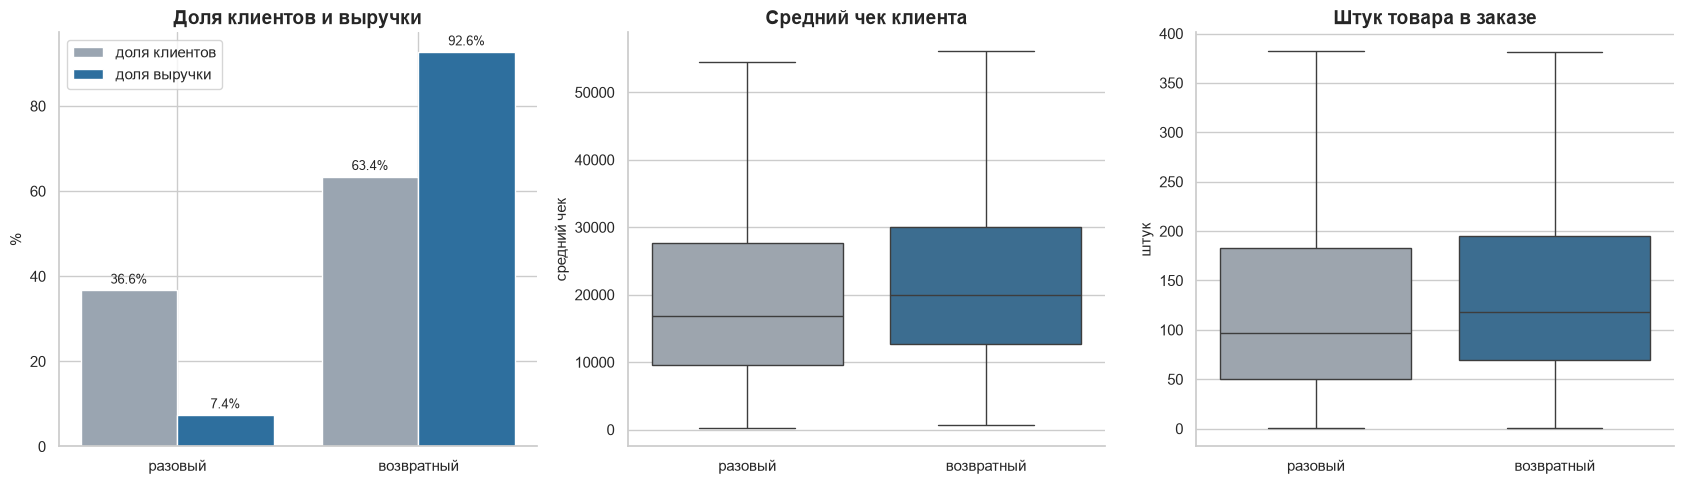

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
order_types = ['разовый', 'возвратный']
palette = {'разовый': GREY, 'возвратный': MAIN}

sh = shares.reindex(order_types)
x = np.arange(2)
axes[0].bar(x - 0.2, sh['доля клиентов'] * 100, width=0.4, color=GREY, label='доля клиентов')
axes[0].bar(x + 0.2, sh['доля выручки'] * 100, width=0.4, color=MAIN, label='доля выручки')
axes[0].set_xticks(x); axes[0].set_xticklabels(order_types)
annotate_bars(axes[0], '{:.1f}%')
axes[0].set_title('Доля клиентов и выручки')
axes[0].set_ylabel('%'); axes[0].legend()

sns.boxplot(data=profile, x='тип клиента', y='aov', order=order_types, palette=palette, ax=axes[1], showfliers=False)
axes[1].set_title('Средний чек клиента')
axes[1].set_ylabel('средний чек'); axes[1].set_xlabel('')

sns.boxplot(data=profile, x='тип клиента', y='avg_items', order=order_types, palette=palette, ax=axes[2], showfliers=False)
axes[2].set_title('Штук товара в заказе')
axes[2].set_ylabel('штук'); axes[2].set_xlabel('')
plt.tight_layout()
plt.show()

In [42]:
ret, one = profile[profile['is_returning']], profile[~profile['is_returning']]
S['returning_share'] = len(ret) / len(profile)
S['returning_rev_share'] = ret['revenue'].sum() / profile['revenue'].sum()
md(f"""**Вывод.**
- Возвратных клиентов **{pct(S['returning_share'])}**, и они приносят **{pct(S['returning_rev_share'])}** выручки известных покупателей:
  в среднем возвратный клиент сделал **{ret['orders'].mean():.1f}** заказа и потратил **{num(ret['revenue'].mean())}** против **{num(one['revenue'].mean())}** у разового
  (в **{ret['revenue'].mean() / one['revenue'].mean():.1f}** раза больше).
- Средний чек: у возвратных — **{num(ret['aov'].median())}**, у разовых — **{num(one['aov'].median())}** (медианы).
  {'Возвратные клиенты тратят за заказ больше: среди них больше оптовиков.' if ret['aov'].median() > one['aov'].median() else 'Чек разовых клиентов не ниже, чем у возвратных: основная разница в выручке — за счёт числа заказов, а не размера заказа.'}
- Возвратные клиенты покупают в среднем **{ret['unique_products'].mean():.0f}** разных товаров против **{one['unique_products'].mean():.0f}** у разовых — они знакомы с ассортиментом шире.
- Типичный интервал между заказами у возвратных — **{ret['avg_days_between'].median():.0f}** дней (медиана): это ориентир, когда напоминать клиенту о себе.
- **Главное для бизнеса:** удержание клиента после первой покупки — ключевой рычаг роста: каждый вернувшийся клиент кратно ценнее разового.""")

**Вывод.**
- Возвратных клиентов **63.4%**, и они приносят **92.6%** выручки известных покупателей:
  в среднем возвратный клиент сделал **5.7** заказа и потратил **177 795** против **24 422** у разового
  (в **7.3** раза больше).
- Средний чек: у возвратных — **20 001**, у разовых — **16 912** (медианы).
  Возвратные клиенты тратят за заказ больше: среди них больше оптовиков.
- Возвратные клиенты покупают в среднем **56** разных товаров против **15** у разовых — они знакомы с ассортиментом шире.
- Типичный интервал между заказами у возвратных — **55** дней (медиана): это ориентир, когда напоминать клиенту о себе.
- **Главное для бизнеса:** удержание клиента после первой покупки — ключевой рычаг роста: каждый вернувшийся клиент кратно ценнее разового.

<div class="alert alert-success">
<b>✔️ Комментарий ревьюера v1:</b>
<br>
Сравнение групп включает средние, медианы и вклад в выручку. Это помогает различать частоту покупок и размер заказа, а также видеть влияние крупных клиентов на средние значения.
</div>

## Шаг 4. RFM-сегментация клиентов

RFM делит клиентов по трём вопросам:
- **R (Recency)** — как давно клиент покупал последний раз (дней до конца периода; меньше — лучше);
- **F (Frequency)** — сколько заказов он сделал;
- **M (Monetary)** — сколько денег принёс.

Каждый показатель оцениваем по шкале от 1 до 3 (3 — лучшее значение):
- **R и M** — по терцилям: треть клиентов с лучшими значениями получает 3, следующая треть — 2, остальные — 1;
- **F** — терцили не подходят, потому что большинство клиентов сделали ровно один заказ. Поэтому: 1 заказ → F=1; возвратные клиенты делятся по медиане числа заказов среди возвратных на F=2 и F=3.

Затем по сочетанию R и F присваиваем понятный бизнесу сегмент, а M показывает его денежную ценность.

In [43]:
rfm = profile[['recency', 'orders', 'revenue', 'aov']].copy()

r1, r2 = rfm['recency'].quantile([1 / 3, 2 / 3])
m1, m2 = rfm['revenue'].quantile([1 / 3, 2 / 3])
f_med = rfm.loc[rfm['orders'] > 1, 'orders'].median()

rfm['R'] = np.select([rfm['recency'] <= r1, rfm['recency'] <= r2], [3, 2], default=1)
rfm['F'] = np.select([rfm['orders'] == 1, rfm['orders'] <= f_med], [1, 2], default=3)
rfm['M'] = np.select([rfm['revenue'] > m2, rfm['revenue'] > m1], [3, 2], default=1)
rfm['RFM'] = rfm['R'].astype(str) + rfm['F'].astype(str) + rfm['M'].astype(str)

thresholds = pd.DataFrame({
    '3 балла': [f'≤ {r1:.0f} дн.', f'> {f_med:.0f} заказов', f'> {num(m2)}'],
    '2 балла': [f'{r1:.0f}–{r2:.0f} дн.', f'2–{f_med:.0f} заказа', f'{num(m1)}–{num(m2)}'],
    '1 балл': [f'> {r2:.0f} дн.', '1 заказ', f'≤ {num(m1)}'],
}, index=['R — дней с последнего заказа', 'F — число заказов', 'M — сумма всех заказов'])
display(thresholds)

,3 балла,2 балла,1 балл
R — дней с последнего заказа,≤ 23 дн.,23–92 дн.,> 92 дн.
F — число заказов,> 4 заказов,2–4 заказа,1 заказ
M — сумма всех заказов,> 76 211,25 152–76 211,≤ 25 152


In [44]:
def segment(row):
    r, f = row['R'], row['F']
    if r == 3 and f == 3:
        return 'Чемпионы'
    if r >= 2 and f >= 2:
        return 'Лояльные'
    if r == 3 and f == 1:
        return 'Новички'
    if r == 2 and f == 1:
        return 'Требуют внимания'
    if r == 1 and f >= 2:
        return 'Под угрозой ухода'
    return 'Потерянные'


SEG_ORDER = ['Чемпионы', 'Лояльные', 'Новички', 'Требуют внимания', 'Под угрозой ухода', 'Потерянные']
SEG_COLORS = dict(zip(SEG_ORDER, ['#1B5E8C', '#4A90C2', '#3A9D5D', '#E0B13F', '#E07A3F', '#9AA5B1']))
rfm['сегмент'] = rfm.apply(segment, axis=1)

seg = (rfm.groupby('сегмент')
       .agg(клиентов=('R', 'size'), R_дней=('recency', 'mean'), F_заказов=('orders', 'mean'),
            M_выручка=('revenue', 'mean'), медиана_M=('revenue', 'median'), средний_чек=('aov', 'median'),
            выручка=('revenue', 'sum'))
       .reindex(SEG_ORDER).dropna(subset=['клиентов']))
seg['доля клиентов'] = seg['клиентов'] / seg['клиентов'].sum()
seg['доля выручки'] = seg['выручка'] / seg['выручка'].sum()
seg['доля с M=3'] = rfm.groupby('сегмент')['M'].apply(lambda s: (s == 3).mean()).reindex(seg.index)
display(seg.style.format({'клиентов': '{:,.0f}', 'R_дней': '{:.0f}', 'F_заказов': '{:.1f}', 'M_выручка': '{:,.0f}',
                          'медиана_M': '{:,.0f}', 'средний_чек': '{:,.0f}', 'выручка': '{:,.0f}',
                          'доля клиентов': '{:.1%}', 'доля выручки': '{:.1%}', 'доля с M=3': '{:.0%}'})
        .background_gradient(subset=['доля выручки'], cmap='Blues'))

,клиентов,R_дней,F_заказов,M_выручка,медиана_M,средний_чек,выручка,доля клиентов,доля выручки,доля с M=3
сегмент,,,,,,,,,,
Чемпионы,665,9,12.0,"437,031","195,221","22,050","290,625,828",15.8%,56.9%,91%
Лояльные,"1,450",35,3.8,"101,531","62,070","20,188","147,220,541",34.5%,28.8%,42%
Новички,215,12,1.0,"22,511","16,678","16,678","4,839,872",5.1%,0.9%,3%
Требуют внимания,474,53,1.0,"29,000","20,528","20,528","13,745,857",11.3%,2.7%,5%
Под угрозой ухода,547,175,3.0,"64,799","44,029","16,148","35,445,204",13.0%,6.9%,24%
Потерянные,851,235,1.0,"22,355","15,180","15,180","19,024,425",20.3%,3.7%,3%


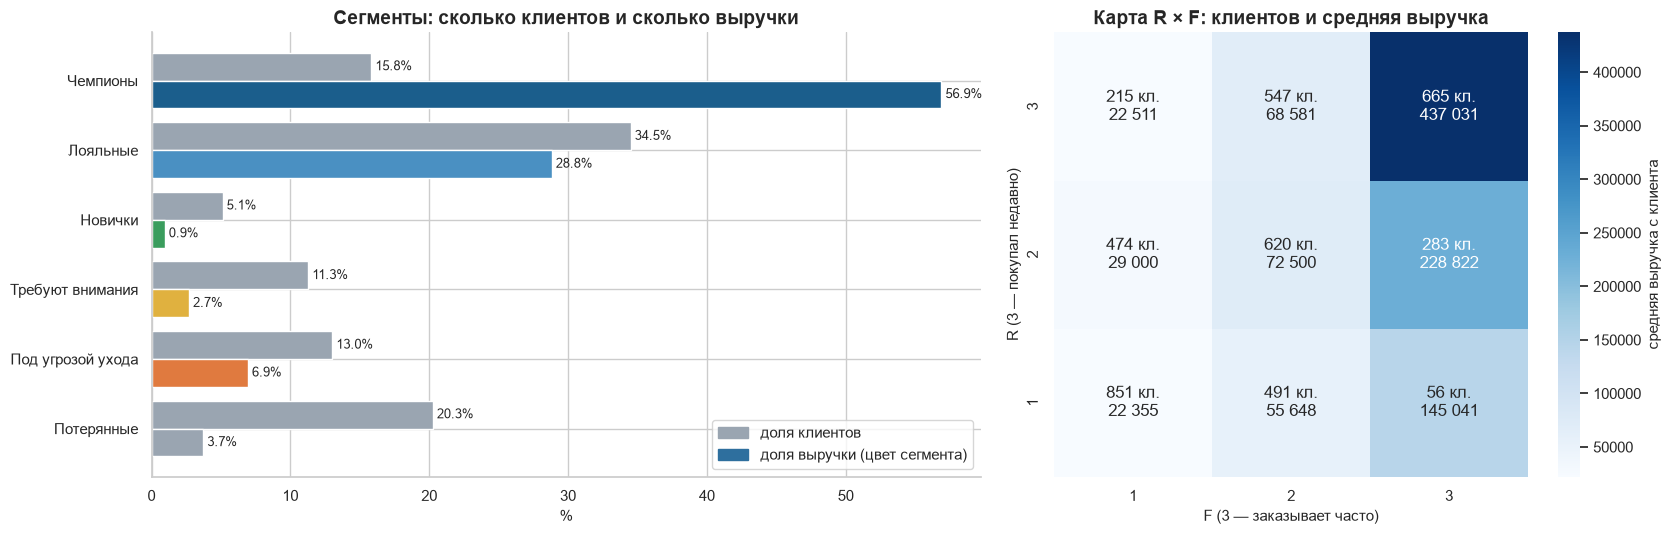

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5), gridspec_kw={'width_ratios': [1.4, 1]})

s = seg.iloc[::-1]
y = np.arange(len(s))
axes[0].barh(y + 0.2, s['доля клиентов'] * 100, height=0.4, color=GREY, label='доля клиентов')
axes[0].barh(y - 0.2, s['доля выручки'] * 100, height=0.4, color=[SEG_COLORS[i] for i in s.index], label='доля выручки')
axes[0].set_yticks(y); axes[0].set_yticklabels(s.index)
annotate_bars(axes[0], '{:.1f}%', horizontal=True)
axes[0].set_title('Сегменты: сколько клиентов и сколько выручки')
axes[0].set_xlabel('%')
axes[0].legend(handles=[Patch(color=GREY, label='доля клиентов'), Patch(color=MAIN, label='доля выручки (цвет сегмента)')], loc='lower right')

cnt = rfm.pivot_table(index='R', columns='F', values='revenue', aggfunc='size', fill_value=0).sort_index(ascending=False)
mean_m = rfm.pivot_table(index='R', columns='F', values='revenue', aggfunc='mean').sort_index(ascending=False)
m_int = mean_m.round(0).fillna(0).astype(int)
elementwise = getattr(m_int, 'map', None) or m_int.applymap      # DataFrame.map есть только в pandas ≥ 2.1
annot = cnt.astype(str) + ' кл.\n' + elementwise(lambda v: f'{v:,}'.replace(',', ' '))
sns.heatmap(mean_m, annot=annot, fmt='', cmap='Blues', ax=axes[1], cbar_kws={'label': 'средняя выручка с клиента'})
axes[1].set_title('Карта R × F: клиентов и средняя выручка')
axes[1].set_ylabel('R (3 — покупал недавно)')
axes[1].set_xlabel('F (3 — заказывает часто)')
plt.tight_layout()
plt.show()

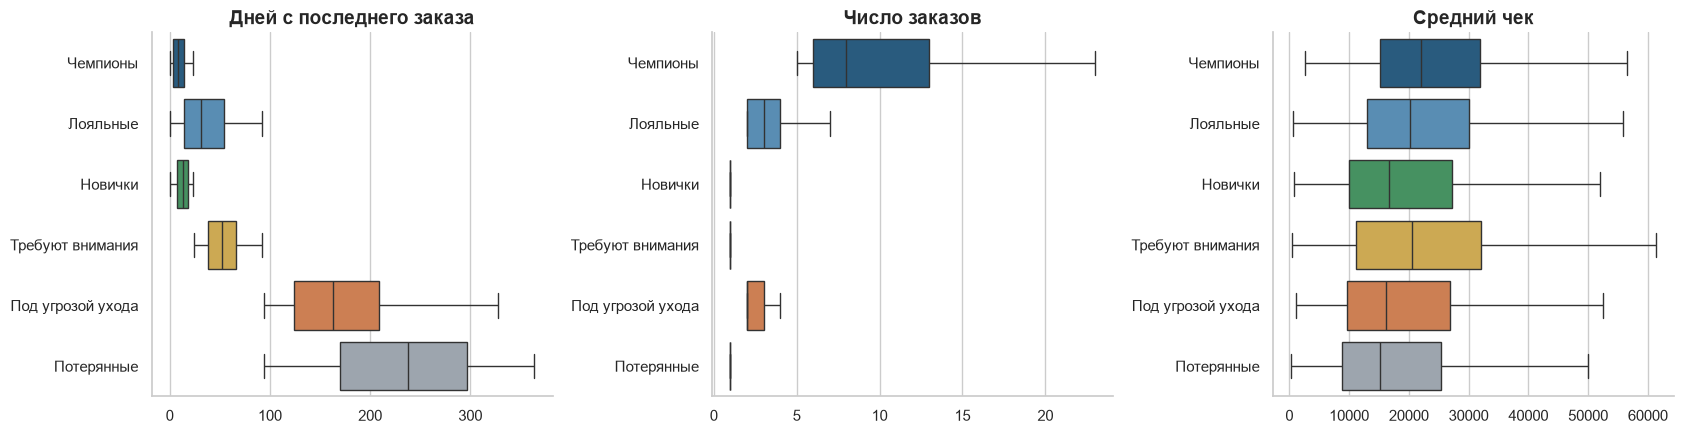

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col, title in zip(axes, ['recency', 'orders', 'aov'], ['Дней с последнего заказа', 'Число заказов', 'Средний чек']):
    sns.boxplot(data=rfm, y='сегмент', x=col, order=[s for s in SEG_ORDER if s in seg.index],
                palette=SEG_COLORS, ax=ax, showfliers=False)
    ax.set_title(title); ax.set_ylabel(''); ax.set_xlabel('')
plt.tight_layout()
plt.show()

In [47]:
top2 = seg.loc[[s for s in ['Чемпионы', 'Лояльные'] if s in seg.index]]
risk = seg.loc[[s for s in ['Под угрозой ухода'] if s in seg.index]]
newb = seg.loc[[s for s in ['Новички', 'Требуют внимания', 'Потерянные'] if s in seg.index]]
S['seg_top_cust'], S['seg_top_rev'] = top2['доля клиентов'].sum(), top2['доля выручки'].sum()
S['seg_risk_rev'] = risk['доля выручки'].sum()
S['seg_one_cust'], S['seg_one_rev'] = newb['доля клиентов'].sum(), newb['доля выручки'].sum()
aov_med = seg['средний_чек']
md(f"""**Оценка сегментов.**
- **Чемпионы и Лояльные** — {pct(S['seg_top_cust'])} клиентов и **{pct(S['seg_top_rev'])}** выручки. Это ядро бизнеса: покупают недавно и часто.
  Оба сегмента — недавние возвратные покупатели; «Чемпионы» отличаются от «Лояльных» более высокой частотой и, как следствие, суммой покупок.
- **Под угрозой ухода** — в среднем {seg.loc['Под угрозой ухода', 'F_заказов'] if 'Под угрозой ухода' in seg.index else float('nan'):.1f} заказа и выручка {num(seg['M_выручка'].get('Под угрозой ухода', np.nan))} на клиента
  (у «Лояльных» — {seg['F_заказов'].get('Лояльные', np.nan):.1f} заказа и {num(seg['M_выручка'].get('Лояльные', np.nan))}): по истории покупок они ближе к лояльным, но давно не возвращались ({seg['R_дней'].get('Под угрозой ухода', np.nan):.0f} дней в среднем).
  На них приходится **{pct(S['seg_risk_rev'])}** выручки — это деньги, которые можно потерять.
- **Новички, Требуют внимания, Потерянные** — клиенты с одним заказом ({pct(S['seg_one_cust'])} клиентов, но лишь {pct(S['seg_one_rev'])} выручки).
  Между собой они похожи по частоте и чеку, а различаются только давностью покупки — то есть шансом ещё вернуть клиента.
- Средний чек (медиана) по сегментам: {', '.join(f'{k} — {num(v)}' for k, v in aov_med.items())}.
  {'Сегменты сильнее различаются по **частоте** покупок, чем по размеру одного заказа: рост выручки даёт в первую очередь повторная покупка.' if seg['F_заказов'].max() / seg['F_заказов'].min() > aov_med.max() / aov_med.min() else 'Сегменты заметно различаются и по размеру заказа: ценность клиента определяется не только частотой, но и чеком.'}""")

**Оценка сегментов.**
- **Чемпионы и Лояльные** — 50.3% клиентов и **85.7%** выручки. Это ядро бизнеса: покупают недавно и часто.
  Оба сегмента — недавние возвратные покупатели; «Чемпионы» отличаются от «Лояльных» более высокой частотой и, как следствие, суммой покупок.
- **Под угрозой ухода** — в среднем 3.0 заказа и выручка 64 799 на клиента
  (у «Лояльных» — 3.8 заказа и 101 531): по истории покупок они ближе к лояльным, но давно не возвращались (175 дней в среднем).
  На них приходится **6.9%** выручки — это деньги, которые можно потерять.
- **Новички, Требуют внимания, Потерянные** — клиенты с одним заказом (36.6% клиентов, но лишь 7.4% выручки).
  Между собой они похожи по частоте и чеку, а различаются только давностью покупки — то есть шансом ещё вернуть клиента.
- Средний чек (медиана) по сегментам: Чемпионы — 22 050, Лояльные — 20 188, Новички — 16 678, Требуют внимания — 20 528, Под угрозой ухода — 16 148, Потерянные — 15 180.
  Сегменты сильнее различаются по **частоте** покупок, чем по размеру одного заказа: рост выручки даёт в первую очередь повторная покупка.

<div class="alert alert-success">
<b>✔️ Комментарий ревьюера v1:</b>
<br>
Правила RFM-баллов сохраняют одинаковую оценку для одинаковых значений, а для Frequency отдельно выделены клиенты с одним заказом. Сопоставление долей клиентов и выручки делает денежную ценность сегментов наглядной, а рекомендации связаны с задачами удержания и реактивации.
</div>

### Рекомендации по сегментам

| Сегмент | Кто это | Что делать |
|---|---|---|
| **Чемпионы** | покупают часто и недавно, приносят больше всего денег | персональный менеджер для крупных, ранний доступ к новинкам, программа лояльности с накопительной скидкой; просить отзывы и рекомендации. Не давать лишних скидок — они и так покупают |
| **Лояльные** | регулярные покупатели | допродажи (товары, которые покупают вместе — см. шаг 7), подборки по прошлым покупкам, бонус за переход на следующий уровень частоты |
| **Новички** | первая покупка совсем недавно | приветственная серия писем, скидка на второй заказ с ограниченным сроком — окно для возврата открыто прямо сейчас (ориентир — медианный интервал между заказами из шага 3.5) |
| **Требуют внимания** | одна покупка, уже не совсем недавно | напоминание с подборкой популярных товаров и сезонным поводом (праздники), лёгкий стимул — бесплатная доставка |
| **Под угрозой ухода** | раньше покупали часто, но давно пропали | приоритетная реактивация: персональное письмо/звонок менеджера, опрос о причинах, весомое предложение. Самый «дорогой» сегмент с точки зрения потерь |
| **Потерянные** | одна покупка давно | недорогие массовые каналы (сезонная рассылка перед праздниками); не тратить на них персональные ресурсы |

**Общая логика:** удерживать ядро (Чемпионы, Лояльные), в первую очередь возвращать «Под угрозой ухода» — там больше всего денег на кону, — и превращать «Новичков» во вторую покупку, пока они помнят магазин.

## Шаг 5. Проверка статистических гипотез

Уровень значимости для всех тестов — **α = 0,05**. Если p-value < α, отвергаем нулевую гипотезу о равенстве.

### 5.1. Доли возвратных клиентов во II и III кварталах 2019 года

Внутри каждого квартала клиент **возвратный**, если сделал в этом квартале больше одного заказа.

- **H₀:** доля возвратных клиентов во II и III кварталах одинакова.
- **H₁:** доли различаются.

**Тест:** z-тест для двух долей (проверяем, что в каждой выборке n·p и n·(1−p) не меньше 10 — тогда нормальное приближение корректно). Дополнительно — критерий χ² по таблице сопряжённости.

In [48]:
def ztest_proportions(k1, n1, k2, n2):
    p1, p2 = k1 / n1, k2 / n2
    p = (k1 + k2) / (n1 + n2)
    z = (p1 - p2) / np.sqrt(p * (1 - p) * (1 / n1 + 1 / n2))
    return z, 2 * stats.norm.sf(abs(z))


q_avail = [q for q in quarters if (orders['quarter'] == pd.Period(q, freq='Q')).any()]
qtab = {}
for q in q_avail:
    per_cust = orders[orders['quarter'] == pd.Period(q, freq='Q')].groupby('customer_id').size()
    qtab[q] = {'клиентов': len(per_cust), 'возвратных': int((per_cust > 1).sum())}
qtab = pd.DataFrame(qtab).T
qtab['разовых'] = qtab['клиентов'] - qtab['возвратных']
qtab['доля возвратных'] = qtab['возвратных'] / qtab['клиентов']
display(qtab.style.format({'клиентов': '{:,.0f}', 'возвратных': '{:,.0f}', 'разовых': '{:,.0f}', 'доля возвратных': '{:.2%}'}))

cond = (qtab[['возвратных', 'разовых']] >= 10).all().all()
print('Условие применимости z-теста (n·p ≥ 10 и n·(1−p) ≥ 10):', 'выполнено' if cond else 'НЕ выполнено')

(k1, n1), (k2, n2) = qtab[['возвратных', 'клиентов']].values
z, p_value = ztest_proportions(k1, n1, k2, n2)
chi2, p_chi2, _, _ = stats.chi2_contingency(qtab[['возвратных', 'разовых']].values)
print(f'z = {z:.3f}, p-value {pv(p_value)}')
print(f'χ²: статистика = {chi2:.3f}, p-value {pv(p_chi2)}')
S['h1_p'] = p_value

,клиентов,возвратных,разовых,доля возвратных
2019Q2,"1,950",799,"1,151",40.97%
2019Q3,"2,105",856,"1,249",40.67%


Условие применимости z-теста (n·p ≥ 10 и n·(1−p) ≥ 10): выполнено
z = 0.200, p-value 0.8413
χ²: статистика = 0.028, p-value 0.8664


Клиентов, покупавших в обоих кварталах: 1 180
Без них: доли возвратных 22.73% и 24.54%, z = -0.874, p-value 0.3822


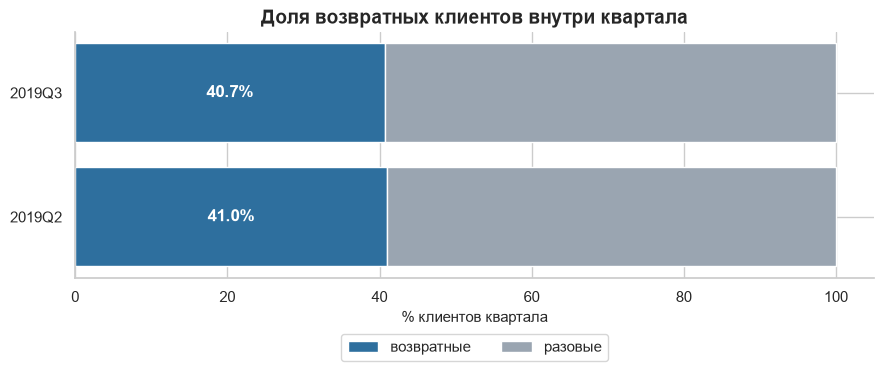

In [49]:
# проверка устойчивости: одни и те же клиенты могут попасть в оба квартала, что нарушает независимость выборок.
# Повторим тест только на клиентах, которые покупали лишь в одном из двух кварталов.
cust_q = orders[orders['quarter'].isin([pd.Period(q, freq='Q') for q in q_avail])].groupby('customer_id')['quarter'].nunique()
only_one = cust_q[cust_q == 1].index
rob = {}
for q in q_avail:
    per_cust = orders[(orders['quarter'] == pd.Period(q, freq='Q')) & orders['customer_id'].isin(only_one)].groupby('customer_id').size()
    rob[q] = (int((per_cust > 1).sum()), len(per_cust))
(rk1, rn1), (rk2, rn2) = rob.values()
z_r, p_r = ztest_proportions(rk1, rn1, rk2, rn2)
print(f'Клиентов, покупавших в обоих кварталах: {num((cust_q == 2).sum())}')
print(f'Без них: доли возвратных {pct(rk1 / rn1, 2)} и {pct(rk2 / rn2, 2)}, z = {z_r:.3f}, p-value {pv(p_r)}')

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(qtab.index, qtab['доля возвратных'] * 100, color=MAIN, label='возвратные')
ax.barh(qtab.index, (1 - qtab['доля возвратных']) * 100, left=qtab['доля возвратных'] * 100, color=GREY, label='разовые')
for i, v in enumerate(qtab['доля возвратных']):
    ax.text(v * 50, i, f'{v:.1%}', va='center', ha='center', color='white', fontweight='bold')
ax.set_title('Доля возвратных клиентов внутри квартала')
ax.set_xlabel('% клиентов квартала'); ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
plt.tight_layout()
plt.show()

In [50]:
same = p_value >= ALPHA
md(f"""**Вывод.** Доля возвратных клиентов: {', '.join(f'{q} — **{pct(v, 1)}**' for q, v in qtab['доля возвратных'].items())}.
p-value **{pv(p_value)}** {'≥' if same else '<'} 0,05, поэтому **{'нет оснований отвергнуть' if same else 'отвергаем'}** нулевую гипотезу:
{'статистически значимой разницы в доле возвратных клиентов между кварталами нет' if same else 'доли возвратных клиентов во II и III кварталах статистически значимо различаются'}.
Проверка на клиентах, которые покупали только в одном из кварталов (чтобы выборки были независимы), даёт p-value {pv(p_r)} —
вывод {'тот же' if (p_r >= ALPHA) == same else 'другой, поэтому результат основного теста стоит трактовать осторожно'}.""")

**Вывод.** Доля возвратных клиентов: 2019Q2 — **41.0%**, 2019Q3 — **40.7%**.
p-value **0.8413** ≥ 0,05, поэтому **нет оснований отвергнуть** нулевую гипотезу:
статистически значимой разницы в доле возвратных клиентов между кварталами нет.
Проверка на клиентах, которые покупали только в одном из кварталов (чтобы выборки были независимы), даёт p-value 0.3822 —
вывод тот же.

<div class="alert alert-success">
<b>✔️ Комментарий ревьюера v1:</b>
<br>
Возвратность одинаково определяется внутри каждого квартала, показаны числители и знаменатели долей и проверены условия нормального приближения. Ограничение независимости выборок также замечено, поэтому статистическая процедура сопровождается обсуждением её применимости.
</div>

### 5.2. Средний чек в странах с `country_id` = 3, 6 и 24

Средний чек — средняя арифметическая сумма одного заказа. Берём заказы известных покупателей: заказы с `customer_id = -1` в разы крупнее обычных и похожи на сводные выгрузки (см. 2.2), они исказили бы средний чек страны.

- **H₀:** средние чеки в странах 3, 6 и 24 равны.
- **H₁:** хотя бы в одной стране средний чек отличается.

**Выбор теста.** Вопрос — именно об арифметических средних, поэтому основной тест — **дисперсионный анализ Уэлча** (ANOVA Уэлча): он сравнивает средние нескольких групп и не требует равенства дисперсий. Попарно страны сравниваем **t-тестом Уэлча** с поправкой Бонферрони на три сравнения. Сначала проверим условия классического ANOVA — нормальность (тест Шапиро — Уилка) и равенство дисперсий (тест Левена). Суммы заказов скошены, а в одной из стран мало заказов, поэтому вывод дополнительно проверяем бутстрепом: строим доверительные интервалы для средних и для попарных разностей средних.

Непараметрические тесты Краскела — Уоллиса и Манна — Уитни отвечают на другой вопрос: они сравнивают не средние, а распределения в целом (сдвиг рангов, при похожей форме распределений — медианы). Их приводим только как справку о **медианном заказе**, на вывод о средних они не влияют.

In [51]:
COUNTRIES = [3, 6, 24]
cid = orders['country_id']
target = [str(c) for c in COUNTRIES] if not pd.api.types.is_numeric_dtype(cid) else COUNTRIES
checks = {c: orders.loc[cid == t, 'revenue'].values for c, t in zip(COUNTRIES, target)}

desc = pd.DataFrame({c: {'заказов': len(v), 'клиентов': orders.loc[cid == t, 'customer_id'].nunique(),
                         'средний чек': np.mean(v) if len(v) else np.nan, 'медиана': np.median(v) if len(v) else np.nan,
                         'ст. отклонение': np.std(v, ddof=1) if len(v) > 1 else np.nan,
                         'асимметрия': stats.skew(v) if len(v) > 2 else np.nan}
                     for (c, v), t in zip(checks.items(), target)}).T
desc.index = [f'страна {c}' for c in desc.index]
display(desc.style.format({'заказов': '{:,.0f}', 'клиентов': '{:,.0f}', 'средний чек': '{:,.1f}', 'медиана': '{:,.1f}',
                           'ст. отклонение': '{:,.1f}', 'асимметрия': '{:.2f}'}))
n_unknown = int((~orders_all['known'] & orders_all['country_id'].isin(target)).sum())
print(f'Заказов неизвестных покупателей в этих странах (не входят в расчёт): {n_unknown}')
if (desc['заказов'] < 20).any():
    print('Внимание: в одной из стран мало заказов — результаты тестов для неё ненадёжны')

,заказов,клиентов,средний чек,медиана,ст. отклонение,асимметрия
страна 3,93,25,"27,948.5","24,364.0","19,880.7",1.54
страна 6,423,93,"33,084.5","23,466.0","39,570.0",6.66
страна 24,31,8,"85,475.1","23,400.0","122,628.5",1.77


Заказов неизвестных покупателей в этих странах (не входят в расчёт): 0


In [52]:
def welch_anova(*groups):
    """ANOVA Уэлча: равенство средних нескольких групп без предположения о равных дисперсиях."""
    k = len(groups)
    n = np.array([len(g) for g in groups], dtype=float)
    m = np.array([np.mean(g) for g in groups])
    w = n / np.array([np.var(g, ddof=1) for g in groups])
    m_w = np.sum(w * m) / np.sum(w)
    tmp = np.sum((1 - w / w.sum()) ** 2 / (n - 1))
    f_stat = (np.sum(w * (m - m_w) ** 2) / (k - 1)) / (1 + 2 * (k - 2) / (k ** 2 - 1) * tmp)
    dfn, dfd = k - 1, (k ** 2 - 1) / (3 * tmp)
    return f_stat, dfn, dfd, stats.f.sf(f_stat, dfn, dfd)


valid = {c: v for c, v in checks.items() if len(v) >= 3}
rng = np.random.default_rng(RANDOM_STATE)

print('Условия классического ANOVA.')
print('Нормальность (Шапиро — Уилк, выборка до 5000 заказов):')
normal = True
for c, v in valid.items():
    sample = v if len(v) <= 5000 else rng.choice(v, 5000, replace=False)
    p_sh = stats.shapiro(sample).pvalue
    normal &= p_sh >= ALPHA
    print(f'  страна {c}: p-value = {p_sh:.2e}')
lev = stats.levene(*valid.values(), center='median')
print(f'Равенство дисперсий (Левен): p-value = {lev.pvalue:.4f}')
print('→', 'условия выполнены, но ANOVA Уэлча корректен и в этом случае.' if normal and lev.pvalue >= ALPHA
      else 'условия нарушены, поэтому классический ANOVA не подходит; используем ANOVA Уэлча.')

f_stat, dfn, dfd, p_welch = welch_anova(*valid.values())
print(f'\nANOVA Уэлча (равенство средних): F = {f_stat:.2f}, df = ({dfn:.0f}; {dfd:.1f}), p-value {pv(p_welch)}')
S['h2_p'] = p_welch

pairs_res = []
n_cmp = len(list(itertools.combinations(valid, 2)))
for a, b in itertools.combinations(valid, 2):
    tt = stats.ttest_ind(valid[a], valid[b], equal_var=False)
    mw = stats.mannwhitneyu(valid[a], valid[b], alternative='two-sided')
    pairs_res.append({'пара': f'{a} vs {b}',
                      'средний чек A': valid[a].mean(), 'средний чек B': valid[b].mean(),
                      'p t-тест Уэлча (Бонферрони)': min(tt.pvalue * n_cmp, 1),
                      'медиана A': np.median(valid[a]), 'медиана B': np.median(valid[b]),
                      'p Манн — Уитни (Бонферрони), справочно': min(mw.pvalue * n_cmp, 1)})
pairs_res = pd.DataFrame(pairs_res).set_index('пара')
pairs_res['средние различаются значимо'] = np.where(pairs_res['p t-тест Уэлча (Бонферрони)'] < ALPHA, 'да', 'нет')
display(pairs_res.style.format({'средний чек A': '{:,.1f}', 'средний чек B': '{:,.1f}', 'медиана A': '{:,.1f}',
                                'медиана B': '{:,.1f}', 'p t-тест Уэлча (Бонферрони)': '{:.4f}',
                                'p Манн — Уитни (Бонферрони), справочно': '{:.4f}'}))

kw = stats.kruskal(*valid.values())
print(f'Справочно — Краскел — Уоллис (сравнивает распределения и медианный заказ, а не средние): '
      f'H = {kw.statistic:.2f}, p-value {pv(kw.pvalue)}')

Условия классического ANOVA.
Нормальность (Шапиро — Уилк, выборка до 5000 заказов):
  страна 3: p-value = 6.36e-07
  страна 6: p-value = 1.70e-30
  страна 24: p-value = 4.00e-07
Равенство дисперсий (Левен): p-value = 0.0000
→ условия нарушены, поэтому классический ANOVA не подходит; используем ANOVA Уэлча.

ANOVA Уэлча (равенство средних): F = 4.70, df = (2; 72.6), p-value 0.0121


,средний чек A,средний чек B,p t-тест Уэлча (Бонферрони),медиана A,медиана B,"p Манн — Уитни (Бонферрони), справочно",средние различаются значимо
пара,,,,,,,
3 vs 6,"27,948.5","33,084.5",0.2089,"24,364.0","23,466.0",1.0000,нет
3 vs 24,"27,948.5","85,475.1",0.0426,"24,364.0","23,400.0",1.0000,да
6 vs 24,"33,084.5","85,475.1",0.0730,"23,466.0","23,400.0",0.6646,нет


Справочно — Краскел — Уоллис (сравнивает распределения и медианный заказ, а не средние): H = 1.37, p-value 0.5038


Бутстреп-интервалы для разностей средних (уровень 98.3% — с поправкой Бонферрони):


,разность средних (A − B),нижняя граница,верхняя граница,0 внутри интервала
пара,,,,
3 vs 6,"-5,136","-12,181","1,565",да
3 vs 24,"-57,527","-115,840","-11,248",нет
6 vs 24,"-52,391","-110,953","-5,826",нет


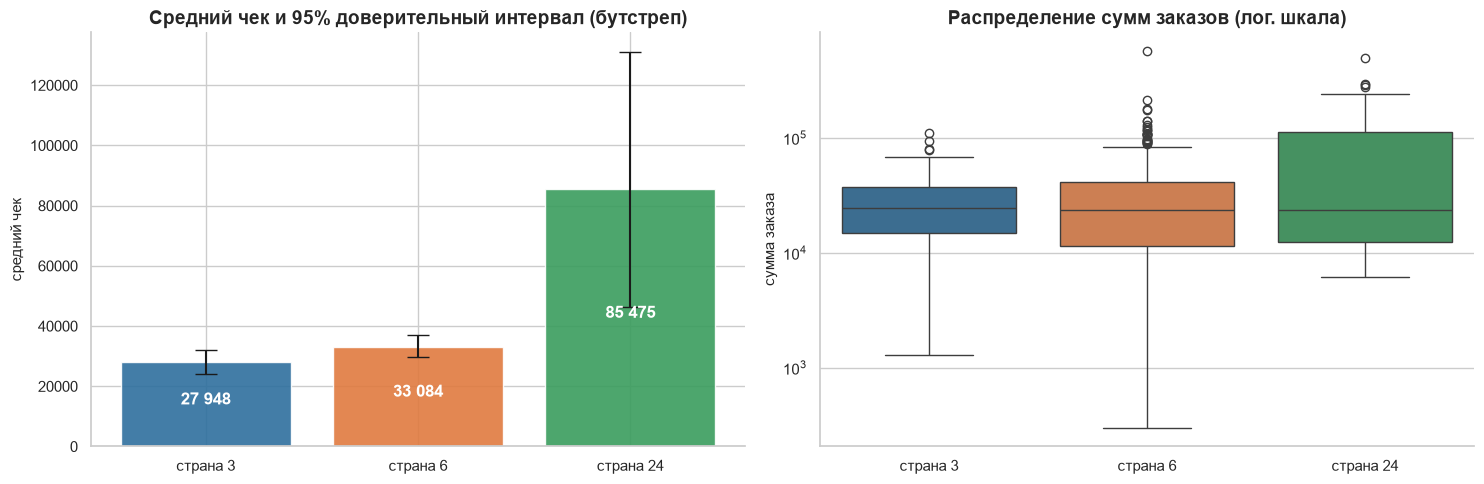

In [53]:
N_BOOT = 5000


def bootstrap_means(values, n_boot=N_BOOT, seed=RANDOM_STATE, chunk=500):
    """Средние бутстреп-выборок (выборки с возвращением того же размера)."""
    r = np.random.default_rng(seed)
    values = np.asarray(values, dtype=float)
    out = []
    for start in range(0, n_boot, chunk):
        size = min(chunk, n_boot - start)
        out.append(values[r.integers(0, len(values), size=(size, len(values)))].mean(axis=1))
    return np.concatenate(out)


boot = {c: bootstrap_means(v, seed=RANDOM_STATE + i) for i, (c, v) in enumerate(valid.items())}
ci = {c: np.percentile(b, [2.5, 97.5]) for c, b in boot.items()}
level = 1 - ALPHA / n_cmp                      # уровень доверия с поправкой Бонферрони
q_lo, q_hi = 100 * (1 - level) / 2, 100 * (1 + level) / 2
boot_diff = pd.DataFrame([{'пара': f'{a} vs {b}', 'разность средних (A − B)': valid[a].mean() - valid[b].mean(),
                           'нижняя граница': np.percentile(boot[a] - boot[b], q_lo),
                           'верхняя граница': np.percentile(boot[a] - boot[b], q_hi)}
                          for a, b in itertools.combinations(valid, 2)]).set_index('пара')
boot_diff['0 внутри интервала'] = np.where((boot_diff['нижняя граница'] <= 0) & (boot_diff['верхняя граница'] >= 0), 'да', 'нет')
print(f'Бутстреп-интервалы для разностей средних (уровень {level:.1%} — с поправкой Бонферрони):')
display(boot_diff.style.format({'разность средних (A − B)': '{:,.0f}', 'нижняя граница': '{:,.0f}', 'верхняя граница': '{:,.0f}'}))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
labels_c = [f'страна {c}' for c in valid]
means = [v.mean() for v in valid.values()]
err = np.array([[m - ci[c][0], ci[c][1] - m] for c, m in zip(valid, means)]).T
axes[0].bar(labels_c, means, yerr=err, capsize=8, color=[MAIN, ACCENT, GOOD][:len(valid)], alpha=0.9)
for i, m in enumerate(means):
    axes[0].text(i, m / 2, num(m), ha='center', color='white', fontweight='bold')
axes[0].set_title('Средний чек и 95% доверительный интервал (бутстреп)')
axes[0].set_ylabel('средний чек')

box = pd.DataFrame({'страна': np.repeat(labels_c, [len(v) for v in valid.values()]),
                    'чек': np.concatenate(list(valid.values()))})
sns.boxplot(data=box, x='страна', y='чек', palette=[MAIN, ACCENT, GOOD][:len(valid)], ax=axes[1])
axes[1].set_yscale('log')
axes[1].set_title('Распределение сумм заказов (лог. шкала)')
axes[1].set_xlabel(''); axes[1].set_ylabel('сумма заказа')
plt.tight_layout()
plt.show()

In [54]:
diff = p_welch < ALPHA
welch_pairs = pairs_res.index[pairs_res['средние различаются значимо'] == 'да'].tolist()
boot_pairs = boot_diff.index[boot_diff['0 внутри интервала'] == 'нет'].tolist()
smallest = min(valid, key=lambda c: len(valid[c]))
S['h2_means'] = {c: v.mean() for c, v in valid.items()}
pairs_txt = (('Попарные t-тесты Уэлча с поправкой Бонферрони находят значимую разницу средних в парах: ' + ', '.join(welch_pairs) + '.')
             if welch_pairs else 'Попарные t-тесты Уэлча с поправкой Бонферрони значимой разницы средних тоже не находят.')
boot_txt = ('Бутстреп-интервалы для разностей средних дают тот же результат.' if set(welch_pairs) == set(boot_pairs)
            else 'Бутстреп-интервалы для разностей средних расходятся с t-тестами (0 не входит в интервал для пар: '
                 + (', '.join(boot_pairs) if boot_pairs else 'нет') + '), поэтому вывод по этим парам неустойчив.')
power_txt = (f'Средние в выборке различаются, но различие **не является статистически значимым** — это не доказывает, что средние равны. '
             f'В стране {smallest} всего {len(valid[smallest])} заказов, а суммы заказов сильно разбросаны (средние держатся на нескольких крупных заказах, '
             f'см. широкие интервалы на графике), поэтому мощность теста невелика.') if not diff else (
             'Различие средних статистически значимо, но средние держатся на нескольких крупных оптовых заказах (см. широкие интервалы на графике), '
             'поэтому величину разницы стоит оценивать по доверительным интервалам.')
md(f"""**Вывод.** Вопрос — о средних чеках, поэтому вывод делаем по ANOVA Уэлча: p-value **{pv(p_welch)}** {'<' if diff else '≥'} 0,05 —
**{'отвергаем' if diff else 'нет оснований отвергнуть'}** нулевую гипотезу о равенстве средних чеков в странах 3, 6 и 24.
Средние чеки: {', '.join(f'страна {c} — **{num(v.mean())}**' for c, v in valid.items())}.
{pairs_txt} {boot_txt}
{power_txt}

Справочно: тест Краскела — Уоллиса, который сравнивает не средние, а распределения сумм заказов (медианный заказ), даёт p-value {pv(kw.pvalue)} —
{'медианные заказы стран различаются' if kw.pvalue < ALPHA else 'значимых различий в распределениях тоже не обнаружено'}. На вывод о средних это не влияет.""")

**Вывод.** Вопрос — о средних чеках, поэтому вывод делаем по ANOVA Уэлча: p-value **0.0121** < 0,05 —
**отвергаем** нулевую гипотезу о равенстве средних чеков в странах 3, 6 и 24.
Средние чеки: страна 3 — **27 948**, страна 6 — **33 084**, страна 24 — **85 475**.
Попарные t-тесты Уэлча с поправкой Бонферрони находят значимую разницу средних в парах: 3 vs 24. Бутстреп-интервалы для разностей средних расходятся с t-тестами (0 не входит в интервал для пар: 3 vs 24, 6 vs 24), поэтому вывод по этим парам неустойчив.
Различие средних статистически значимо, но средние держатся на нескольких крупных оптовых заказах (см. широкие интервалы на графике), поэтому величину разницы стоит оценивать по доверительным интервалам.

Справочно: тест Краскела — Уоллиса, который сравнивает не средние, а распределения сумм заказов (медианный заказ), даёт p-value 0.5038 —
значимых различий в распределениях тоже не обнаружено. На вывод о средних это не влияет.

<div class="alert alert-warning">
<b>⚠️ Комментарий ревьюера v1:</b>
<br>
Полные суммы заказов и попарные тесты Уэлча с поправкой Бонферрони рассчитаны корректно. Для вопроса об арифметических средних сделай именно их основой интерпретации, включая результат, передаваемый в общий вывод.
<br>
Краскел - Уоллис и Манн - Уитни отвечают на другой статистический вопрос. Ненормальность распределений не превращает их в проверку арифметических средних, а сравнение «типичных заказов» требует уточнения того, какой показатель понимается под типичным.
</div>

<div class="alert alert-info">
<b>Комментарий студента v1:</b>
<br>Согласен, перестроил раздел. Основа интерпретации теперь — проверка средних: ANOVA Уэлча для трёх стран сразу и попарные t-тесты Уэлча с поправкой Бонферрони. Устойчивость вывода проверяю бутстреп-интервалами для разностей средних. В общий вывод теперь передаётся p-value ANOVA Уэлча.
<br>Краскел — Уоллис и Манн — Уитни оставил только справочно и прямо подписал, что они сравнивают распределения и медианный заказ, а не средние. Формулировку про «типичные заказы» убрал.
<br>Кроме того, по замечанию про <code>customer_id = -1</code> в расчёт входят только заказы известных покупателей.
</div>

### 5.3. Собственная гипотеза: крупный первый заказ — признак будущего постоянного клиента?

Бизнесу важно уже по первой покупке понимать, стоит ли вкладываться в удержание клиента. Проверим, связана ли **сумма первого заказа** с тем, вернётся ли клиент.

**Как сделать сравнение честным.** Простое деление клиентов на «возвратных» и «разовых» за весь период смещено по двум причинам:
1. **Разная длительность наблюдения.** У клиента, впервые купившего в последний месяц, почти не было времени на повторный заказ, а у купившего в начале периода — почти год.
2. **Первый заказ в данных — не обязательно первый в истории клиента.** Постоянный клиент, покупавший и до начала выгрузки, в первые месяцы выглядит как «новый».

Поэтому:
- **одинаковое окно для всех:** клиент считается **вернувшимся**, если сделал следующий заказ в течение **90 дней** после первого. В выборку берём только клиентов, у которых после первого заказа есть полные 90 дней данных;
- **отсекаем возможных «старых» клиентов:** берём только тех, чей первый заказ случился не раньше чем через 90 дней от начала периода. Большинство повторных заказов делается в пределах 90 дней после предыдущего (доля выводится ниже), поэтому постоянный клиент почти наверняка «проявился» бы в первые 90 дней.

- **H₀:** суммы первого заказа у вернувшихся в течение 90 дней и у невернувшихся клиентов не различаются (распределения одинаковы).
- **H₁:** суммы первого заказа различаются.

**Тесты:** Манн — Уитни — суммы сильно скошены, поэтому сравниваем распределения и медианный первый заказ. Для средних — t-тест Уэлча. Связь размера первого заказа (по квартилям) с долей вернувшихся проверяем критерием χ².

Повторных заказов, сделанных не позже чем через 90 дней после предыдущего: 87.2%
Клиентов в когорте: 1 614 (первый заказ с 01.03.2019 по 01.09.2019), из 4 202 известных клиентов


,клиентов,средняя сумма 1-го заказа,медиана
вернулись за 90 дней,656,"27,960.4","21,256.0"
не вернулись,958,"24,419.3","17,400.0"


Манн — Уитни: p-value < 0.0001; t-тест Уэлча (средние): p-value 0.0222
χ² (связь квартиля первого заказа и возврата): статистика = 19.62, p-value 0.0002


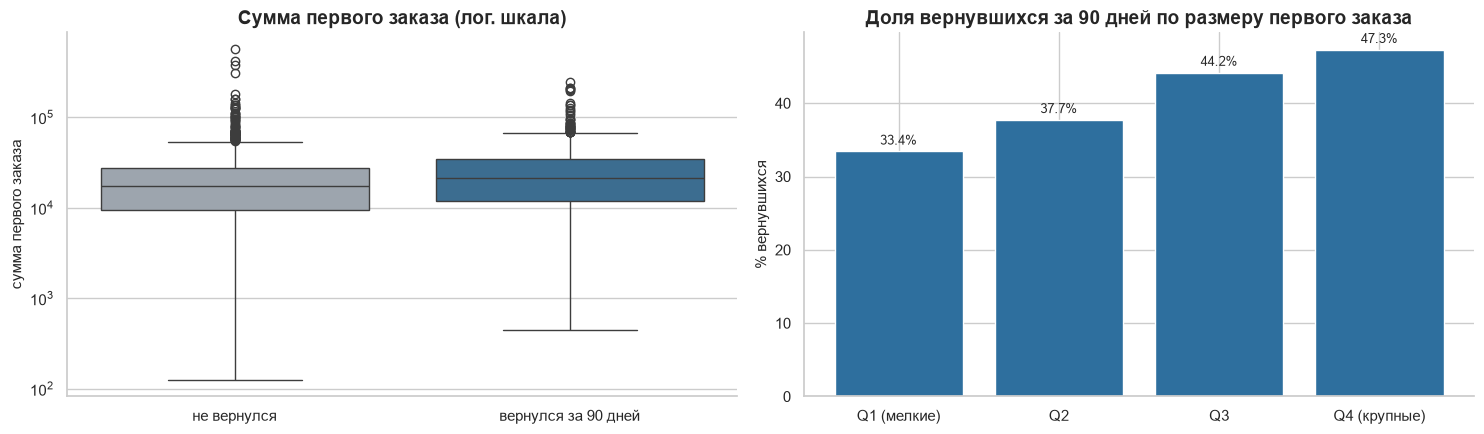

In [55]:
WINDOW = 90   # дней
window = pd.Timedelta(days=WINDOW)

o = orders.sort_values(['customer_id', 'order_date']).copy()
o['номер заказа клиента'] = o.groupby('customer_id').cumcount()
first_orders = o[o['номер заказа клиента'] == 0].set_index('customer_id')
second_date = o[o['номер заказа клиента'] == 1].set_index('customer_id')['order_date']
first_orders['дней до 2-го заказа'] = (second_date.reindex(first_orders.index) - first_orders['order_date']).dt.days

gaps = o.groupby('customer_id')['order_date'].diff().dt.days.dropna()
S['gap_cover'] = (gaps <= WINDOW).mean()
print(f'Повторных заказов, сделанных не позже чем через {WINDOW} дней после предыдущего: {pct(S["gap_cover"])}')

cohort = first_orders[(first_orders['order_date'] >= PERIOD_START + window)
                      & (first_orders['order_date'] < PERIOD_END - window)].copy()
cohort['вернулся'] = cohort['дней до 2-го заказа'] <= WINDOW
cohort['тип'] = np.where(cohort['вернулся'], f'вернулся за {WINDOW} дней', 'не вернулся')
print(f'Клиентов в когорте: {num(len(cohort))} (первый заказ с {cohort["order_date"].min():%d.%m.%Y} '
      f'по {cohort["order_date"].max():%d.%m.%Y}), из {num(len(first_orders))} известных клиентов')

a = cohort.loc[cohort['вернулся'], 'revenue']
b = cohort.loc[~cohort['вернулся'], 'revenue']
mw = stats.mannwhitneyu(a, b, alternative='two-sided')
tt = stats.ttest_ind(a, b, equal_var=False)
S['h3_p'] = mw.pvalue
display(pd.DataFrame({'клиентов': [len(a), len(b)], 'средняя сумма 1-го заказа': [a.mean(), b.mean()],
                      'медиана': [a.median(), b.median()]}, index=[f'вернулись за {WINDOW} дней', 'не вернулись'])
        .style.format({'клиентов': '{:,.0f}', 'средняя сумма 1-го заказа': '{:,.1f}', 'медиана': '{:,.1f}'}))
print(f'Манн — Уитни: p-value {pv(mw.pvalue)}; t-тест Уэлча (средние): p-value {pv(tt.pvalue)}')

# доля вернувшихся в зависимости от размера первого заказа
cohort['квартиль 1-го заказа'] = pd.qcut(cohort['revenue'], 4, labels=['Q1 (мелкие)', 'Q2', 'Q3', 'Q4 (крупные)'])
ret_by_q = cohort.groupby('квартиль 1-го заказа', observed=True)['вернулся'].mean()
chi2_q, p_q, _, _ = stats.chi2_contingency(pd.crosstab(cohort['квартиль 1-го заказа'], cohort['вернулся']))
print(f'χ² (связь квартиля первого заказа и возврата): статистика = {chi2_q:.2f}, p-value {pv(p_q)}')

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
order_types = ['не вернулся', f'вернулся за {WINDOW} дней']
sns.boxplot(data=cohort, x='тип', y='revenue', order=order_types,
            palette={order_types[0]: GREY, order_types[1]: MAIN}, ax=axes[0])
axes[0].set_yscale('log')
axes[0].set_title('Сумма первого заказа (лог. шкала)')
axes[0].set_xlabel(''); axes[0].set_ylabel('сумма первого заказа')
axes[1].bar(ret_by_q.index.astype(str), ret_by_q.values * 100, color=MAIN)
annotate_bars(axes[1], '{:.1f}%')
axes[1].set_title(f'Доля вернувшихся за {WINDOW} дней по размеру первого заказа')
axes[1].set_ylabel('% вернувшихся')
plt.tight_layout()
plt.show()

In [56]:
d3 = mw.pvalue < ALPHA
grows = ret_by_q.iloc[-1] > ret_by_q.iloc[0]
practical = ('Практический вывод: клиентов с крупным первым заказом стоит сразу передавать в программу удержания (это потенциальные оптовики), '
             'а мелким — предлагать стимул ко второму заказу.' if d3 and grows else
             'Практический вывод: удерживать нужно всех новых клиентов — по размеру первой покупки возврат предсказать нельзя.' if not d3 else
             'Практический вывод: связь есть, но направлена не в пользу крупных заказов — программу удержания стоит строить не по размеру первой покупки.')
md(f"""**Вывод.** Клиентов в выборке: **{num(len(cohort))}** (первый заказ с {cohort['order_date'].min():%d.%m.%Y} по {cohort['order_date'].max():%d.%m.%Y}); в течение {WINDOW} дней вернулись **{pct(cohort['вернулся'].mean())}** из них.
Медианная сумма первого заказа у вернувшихся — **{num(a.median())}**, у невернувшихся — **{num(b.median())}**.
Манн — Уитни: p-value **{pv(mw.pvalue)}** {'<' if d3 else '≥'} 0,05 — **{'отвергаем' if d3 else 'нет оснований отвергнуть'}** нулевую гипотезу{': суммы первого заказа у двух групп различаются' if d3 else ': статистически значимых различий не обнаружено'}.
Средние — {num(a.mean())} против {num(b.mean())} (t-тест Уэлча: p-value {pv(tt.pvalue)}{' — по средним различие статистически не значимо: его размывают редкие очень крупные заказы в обеих группах' if tt.pvalue >= ALPHA else ''}).
Доля вернувшихся меняется от **{pct(ret_by_q.iloc[0])}** при самых мелких первых заказах до **{pct(ret_by_q.iloc[-1])}** при самых крупных (χ²: p-value {pv(p_q)}).
{practical}

**Ограничения.** Это связь, а не причина: крупный первый заказ чаще делают оптовики, которые и так покупают регулярно.
Окно в {WINDOW} дней и отсечение первых {WINDOW} дней периода уменьшают смещения, но не убирают их полностью: часть «новых» клиентов всё же могла покупать до начала выгрузки ({pct(1 - S['gap_cover'])} повторных заказов делаются позже чем через {WINDOW} дней).
Данные — за один год, поэтому для прогноза поведения новых клиентов результат нужно перепроверить на следующих периодах.""")

**Вывод.** Клиентов в выборке: **1 614** (первый заказ с 01.03.2019 по 01.09.2019); в течение 90 дней вернулись **40.6%** из них.
Медианная сумма первого заказа у вернувшихся — **21 256**, у невернувшихся — **17 400**.
Манн — Уитни: p-value **< 0.0001** < 0,05 — **отвергаем** нулевую гипотезу: суммы первого заказа у двух групп различаются.
Средние — 27 960 против 24 419 (t-тест Уэлча: p-value 0.0222).
Доля вернувшихся меняется от **33.4%** при самых мелких первых заказах до **47.3%** при самых крупных (χ²: p-value 0.0002).
Практический вывод: клиентов с крупным первым заказом стоит сразу передавать в программу удержания (это потенциальные оптовики), а мелким — предлагать стимул ко второму заказу.

**Ограничения.** Это связь, а не причина: крупный первый заказ чаще делают оптовики, которые и так покупают регулярно.
Окно в 90 дней и отсечение первых 90 дней периода уменьшают смещения, но не убирают их полностью: часть «новых» клиентов всё же могла покупать до начала выгрузки (12.8% повторных заказов делаются позже чем через 90 дней).
Данные — за один год, поэтому для прогноза поведения новых клиентов результат нужно перепроверить на следующих периодах.

<div class="alert alert-success">
<b>✔️ Комментарий ревьюера v1:</b>
<br>
Для сравнения выбраны первые заказы, поэтому у каждого клиента одно наблюдение и частые покупатели не получают больший вес. Дополнение теста долями возвратных клиентов по размеру первой покупки помогает связать статистический результат с бизнес-вопросом.
</div>

<div class="alert alert-warning">
<b>⚠️ Комментарий ревьюера v1:</b>
<br>
При объяснении возвратности учитывай разную длительность наблюдения: у клиента, впервые купившего в конце периода, было меньше времени на повторный заказ. Кроме того, первый заказ внутри выбранного периода не обязательно является первым за всю историю клиента. Эти ограничения стоит отметить перед использованием результата для прогнозирования будущего поведения.
</div>

<div class="alert alert-info">
<b>Комментарий студента v1:</b>
<br>Учёл оба ограничения в самом расчёте, а не только в тексте:
<br>— <b>разная длительность наблюдения:</b> вместо «вернулся когда-нибудь за период» используется фиксированное окно — следующий заказ в течение 90 дней после первого. В выборку попадают только клиенты, у которых после первого заказа есть полные 90 дней данных;
<br>— <b>первый заказ в периоде ≠ первый в истории:</b> исключены клиенты, впервые появившиеся в первые 90 дней периода, — это могут быть «старые» клиенты. Длина окна обоснована данными: доля повторных заказов, сделанных в пределах 90 дней, выводится в расчёте.
<br>Связь размера первого заказа с возвратом дополнительно проверена критерием χ² по квартилям. В выводе отдельным абзацем перечислены оставшиеся ограничения: это связь, а не причина; история неполная; данные только за один год. Их нужно учитывать, прежде чем использовать результат для прогноза.
</div>

## Шаг 7. Дополнительное исследование: какие товары покупают вместе

*(Шаг выполнен перед общим выводом, чтобы учесть его результаты.)*

Для каждой пары товаров считаем, в скольких заказах они встретились вместе. Чтобы оценить, насколько связь неслучайна, считаем:
- **поддержку (support)** — долю заказов, в которых есть оба товара;
- **уверенность (confidence A→B)** — долю заказов с товаром A, где есть и товар B;
- **лифт (lift)** — во сколько раз чаще пара встречается вместе, чем если бы товары покупали независимо (lift > 1 — товары «тянут» друг друга).

Чтобы расчёт был быстрым, берём 300 самых популярных товаров — именно для них рекомендации имеют практический смысл. Корзины строим по заказам известных покупателей: «заказы» с `customer_id = -1` похожи на сводные выгрузки, и в одну «корзину» попали бы товары из разных покупок.

In [57]:
TOP_N = 300
n_orders = dfc['order_id'].nunique()                       # только заказы известных покупателей
prod_orders = dfc.groupby('entry_id')['order_id'].nunique()
top_ids = set(prod_orders.nlargest(TOP_N).index)

baskets = dfc[dfc['entry_id'].isin(top_ids)].groupby('order_id')['entry_id'].agg(lambda s: sorted(set(s)))
pair_counts = Counter()
for items in baskets:
    if len(items) > 1:
        pair_counts.update(itertools.combinations(items, 2))

pairs_df = pd.DataFrame([(a, b, c) for (a, b), c in pair_counts.items()], columns=['A', 'B', 'заказов вместе'])
pairs_df['support'] = pairs_df['заказов вместе'] / n_orders
pairs_df['conf A→B'] = pairs_df['заказов вместе'] / pairs_df['A'].map(prod_orders)
pairs_df['conf B→A'] = pairs_df['заказов вместе'] / pairs_df['B'].map(prod_orders)
pairs_df['lift'] = pairs_df['support'] / (pairs_df['A'].map(prod_orders) / n_orders * pairs_df['B'].map(prod_orders) / n_orders)
pairs_df['товар A'] = pairs_df['A'].map(names)
pairs_df['товар B'] = pairs_df['B'].map(names)

top_pairs = pairs_df.sort_values('заказов вместе', ascending=False).head(15)
display(top_pairs[['товар A', 'товар B', 'заказов вместе', 'support', 'conf A→B', 'conf B→A', 'lift']]
        .reset_index(drop=True)
        .style.format({'заказов вместе': '{:,.0f}', 'support': '{:.2%}', 'conf A→B': '{:.1%}', 'conf B→A': '{:.1%}', 'lift': '{:.1f}'}))

,товар A,товар B,заказов вместе,support,conf A→B,conf B→A,lift
0,большая сумка красного цвета Retrospot,большая сумка розового цвета в горошек,533,3.20%,34.8%,62.7%,6.8
1,сумка для обеда дизайн Суки,сумка для обеда красная Retrospot,506,3.04%,50.0%,41.1%,6.8
2,сумка для обеда в розовый горошек,сумка для обеда красная Retrospot,500,3.00%,55.6%,40.6%,7.5
3,Зеленая чашка и блюдце в стиле регентства,"Розы Регентства, чашка и блюдце",494,2.96%,77.6%,68.9%,18.0
4,деревянная рама античный белый,деревянная рамка для фотографий с белой отделкой,449,2.69%,58.2%,52.9%,11.4
5,"Сумка для обеда, дизайн космического мальчика",сумка для обеда красная Retrospot,449,2.69%,47.1%,36.5%,6.4
6,сумка для обеда дизайн Суки,сумка для обеда машинки синяя,442,2.65%,43.7%,47.4%,7.8
7,сумка для обеда красная Retrospot,сумка для обеда машинки синяя,440,2.64%,35.7%,47.2%,6.4
8,"Сумка для обеда, дизайн космического мальчика",сумка для обеда дизайн Суки,437,2.62%,45.8%,43.2%,7.5
9,Зеленая чашка и блюдце в стиле регентства,Розовая чашка и блюдце в стиле регентства,420,2.52%,65.9%,82.7%,21.6


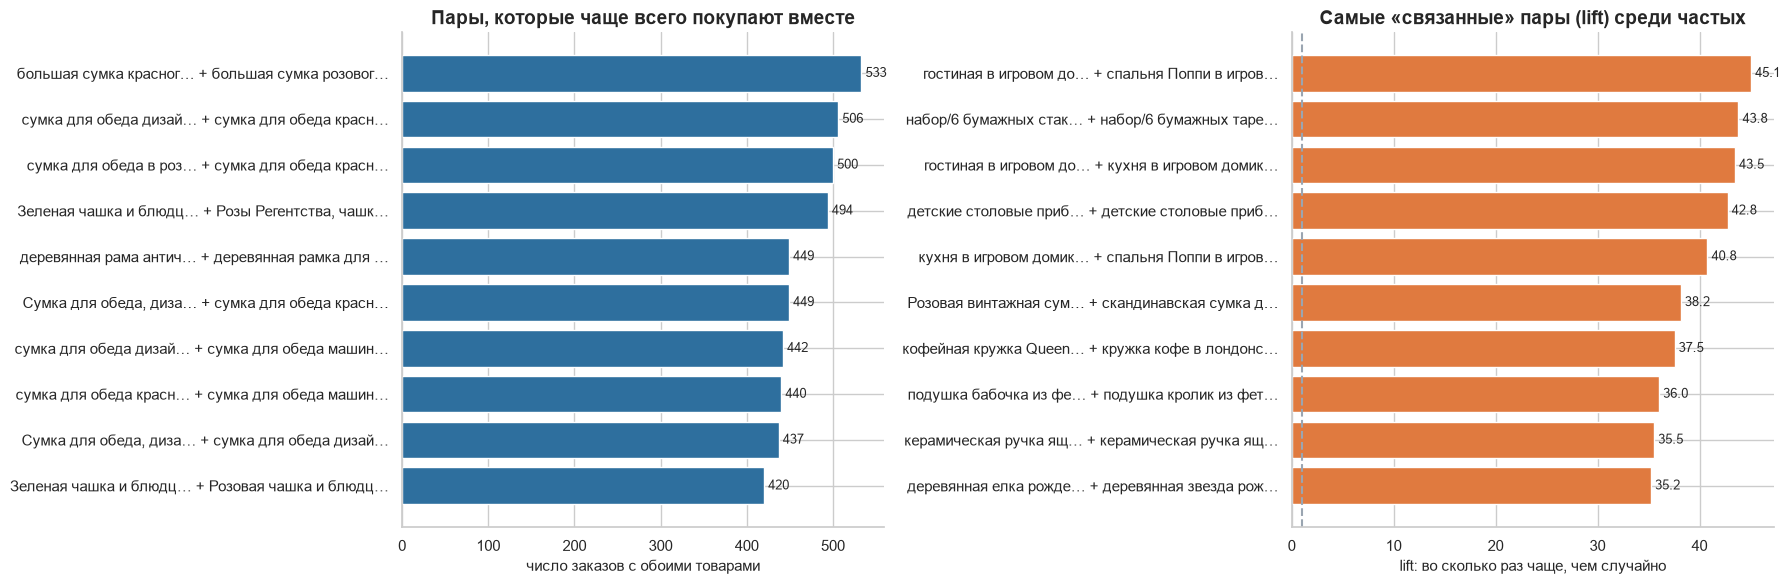

In [58]:
strong = pairs_df[pairs_df['заказов вместе'] >= max(20, pairs_df['заказов вместе'].quantile(0.9))].sort_values('lift', ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
tp = top_pairs.head(10).iloc[::-1]
axes[0].barh([f'{short(a, 22)} + {short(b, 22)}' for a, b in zip(tp['товар A'], tp['товар B'])], tp['заказов вместе'], color=MAIN)
annotate_bars(axes[0], horizontal=True)
axes[0].set_title('Пары, которые чаще всего покупают вместе')
axes[0].set_xlabel('число заказов с обоими товарами')

sp = strong.iloc[::-1]
axes[1].barh([f'{short(a, 22)} + {short(b, 22)}' for a, b in zip(sp['товар A'], sp['товар B'])], sp['lift'], color=ACCENT)
annotate_bars(axes[1], '{:.1f}', horizontal=True)
axes[1].axvline(1, color=GREY, ls='--')
axes[1].set_title('Самые «связанные» пары (lift) среди частых')
axes[1].set_xlabel('lift: во сколько раз чаще, чем случайно')
plt.tight_layout()
plt.show()

In [59]:
best = top_pairs.iloc[0]
clust_of = df.groupby('entry_id')['name_clust'].first()
same_cl = int((top_pairs['A'].map(clust_of) == top_pairs['B'].map(clust_of)).sum())
S['same_cl'] = same_cl
S['pair_best'] = f"«{best['товар A']}» + «{best['товар B']}»"
md(f"""**Вывод.** Чаще всего вместе покупают {S['pair_best']} — **{num(best['заказов вместе'])}** заказов,
причём {pct(best['conf A→B'])} покупателей первого товара берут и второй (lift = {best['lift']:.1f}).
Из 15 самых частых пар **{same_cl}** состоят из товаров одной группы `name_clust` (похожих по названию){' — клиенты собирают наборы из одной линейки' if same_cl >= 8 else ', остальные — сочетания разных групп, то есть клиенты дополняют покупку сопутствующими товарами'}.
**Рекомендации:** продавать такие пары комплектами со скидкой, показывать блок «С этим товаром покупают» на карточке товара и в корзине,
использовать пары с высоким lift для персональных подборок лояльным клиентам и в письмах «Новичкам».""")

**Вывод.** Чаще всего вместе покупают «большая сумка красного цвета Retrospot» + «большая сумка розового цвета в горошек» — **533** заказов,
причём 34.8% покупателей первого товара берут и второй (lift = 6.8).
Из 15 самых частых пар **3** состоят из товаров одной группы `name_clust` (похожих по названию), остальные — сочетания разных групп, то есть клиенты дополняют покупку сопутствующими товарами.
**Рекомендации:** продавать такие пары комплектами со скидкой, показывать блок «С этим товаром покупают» на карточке товара и в корзине,
использовать пары с высоким lift для персональных подборок лояльным клиентам и в письмах «Новичкам».

<div class="alert alert-success">
<b>✔️ Комментарий ревьюера v1:</b>
<br>
Совместные покупки оценены не только по частоте, но и через support, confidence и lift. Ограничение минимального числа совместных заказов помогает не выводить в рекомендации случайные редкие сочетания. Результаты связаны с конкретными механиками комплектов и допродаж.
</div>

## Шаг 6. Общий вывод

In [60]:
p1, p2, p3 = S['h1_p'], S['h2_p'], S['h3_p']
means_ratio = max(S['h2_means'].values()) / min(S['h2_means'].values())
h1_txt = (f'доли возвратных клиентов во II и III кварталах 2019 года **статистически значимо различаются** (p-value {pv(p1)})' if p1 < ALPHA else
          f'между II и III кварталами 2019 года **статистически значимых различий в доле возвратных клиентов не обнаружено** (p-value {pv(p1)})')
h2_txt = (f'средние чеки в странах 3, 6 и 24 **статистически значимо различаются** (ANOVA Уэлча, p-value {pv(p2)})' if p2 < ALPHA else
          f'между средними чеками стран 3, 6 и 24 **статистически значимых различий не обнаружено** (ANOVA Уэлча, p-value {pv(p2)})'
          + (f', хотя выборочные средние различаются до {means_ratio:.1f} раза — заказов слишком мало, а разброс слишком велик, чтобы это подтвердить'
             if means_ratio > 1.5 else ''))
h3_txt = (f'сумма первого заказа у клиентов, вернувшихся в течение 90 дней, **статистически значимо отличается** от суммы у невернувшихся (p-value {pv(p3)})' if p3 < ALPHA else
          f'**статистически значимой связи** суммы первого заказа с возвратом в течение 90 дней **не обнаружено** (p-value {pv(p3)})')
sticky_txt = ', '.join(f'{k} — {pct(v)}' for k, v in S['sticky'].items())
md(f"""### Что сделано
1. Данные о продажах объединены со справочником товаров. Даты разобраны явными форматами: в файле смешаны записи ДД/ММ и ММ/ДД, верный порядок подтверждён последовательностью номеров заказов.
2. `customer_id = -1` распознан как «покупатель неизвестен» ({pct(S['unknown_rows_share'])} строк, {pct(S['unknown_rev_share'])} выручки). Эти продажи учтены в общих показателях, но не в клиентских метриках.
3. Удалены дубликаты, отмены, возвраты и списания, позиции с нулевой ценой, служебные записи (точный список после проверки каждого кандидата, видов: {S['n_services']}) и ошибочные позиции, подтверждённые проверкой по контексту (строк: {S['n_errors']}). Оптовые партии и дорогие товары сохранены. Для анализа выбран период с полными данными — **{S['period']}**.
4. Рассчитаны метрики активности, выручки, «липкости», составлены профили клиентов, проведена RFM-сегментация, проверены три гипотезы.

### Главные результаты
- **Покупательская активность цикличная.** Заказы приходят в рабочее время с пиком **{S['peak_hours']}**, больше всего заказов в среднем за день — в **{S['best_weekday']}**{('; в ' + ', '.join(S['zero_days']) + ' заказов нет совсем — вероятно, это нерабочий день (предположение, его нужно подтвердить расписанием магазина)') if S['zero_days'] else ''}. Такой ритм похож на поведение оптовых и корпоративных покупателей.
- **Сезонность.** Больше всего покупателей — в **{S['best_month']}**; в сильные месяцы выручка растёт за счёт числа покупателей, а не чека.
  Для вывода об устойчивой сезонности нужна история больше одного года.
- **Липкость:** sticky factor {sticky_txt} — в обычный день покупает лишь небольшая часть месячной аудитории. Высокое это значение или низкое для магазина подарков, по нашим данным сказать нельзя: нет ориентира для сравнения. Предположительно, дело в том, что подарки покупают по поводу. Метрику стоит отслеживать в динамике.
- **Возвратные клиенты — основа выручки:** их {pct(S['returning_share'])}, а приносят они **{pct(S['returning_rev_share'])}** выручки известных покупателей.
- **RFM:** «Чемпионы» и «Лояльные» — {pct(S['seg_top_cust'])} клиентов и **{pct(S['seg_top_rev'])}** выручки; «Под угрозой ухода» держат {pct(S['seg_risk_rev'])} выручки;
  клиенты с одной покупкой — {pct(S['seg_one_cust'])} базы, но лишь {pct(S['seg_one_rev'])} выручки.
- **Гипотезы:** {h1_txt}; {h2_txt}; {h3_txt}.{' Отсутствие значимых различий не доказывает равенства — оно означает лишь, что данных недостаточно, чтобы различие увидеть.' if max(p1, p2, p3) >= ALPHA else ''}
- **Совместные покупки:** самая частая пара — {S['pair_best']}; из 15 самых частых пар {S['same_cl']} — товары одной группы по названию.

### Рекомендации бизнесу
1. **Удерживать после первой покупки** — главный рычаг роста: приветственная серия и предложение на второй заказ для «Новичков».
2. **Срочно возвращать «Под угрозой ухода»** персональными предложениями — на них приходится заметная доля выручки.
3. **Беречь ядро** («Чемпионы», «Лояльные»): программа лояльности, персональный менеджер для оптовиков, ранний доступ к новинкам вместо скидок.
4. **Комплекты и допродажи** на основе пар товаров, которые покупают вместе.
5. **Время коммуникаций:** рассылки — утром в будни, перед пиком заказов; сезонные кампании запускать заранее, до месяцев максимального спроса.
6. **Качество данных:** единый формат дат (например, `ГГГГ-ММ-ДД`), отдельное поле для отмен и служебных операций, обязательный номер клиента в заказе — сейчас {pct(S['unknown_rev_share'])} выручки нельзя привязать к покупателю.""")

### Что сделано
1. Данные о продажах объединены со справочником товаров. Даты разобраны явными форматами: в файле смешаны записи ДД/ММ и ММ/ДД, верный порядок подтверждён последовательностью номеров заказов.
2. `customer_id = -1` распознан как «покупатель неизвестен» (25.9% строк, 17.9% выручки). Эти продажи учтены в общих показателях, но не в клиентских метриках.
3. Удалены дубликаты, отмены, возвраты и списания, позиции с нулевой ценой, служебные записи (точный список после проверки каждого кандидата, видов: 95) и ошибочные позиции, подтверждённые проверкой по контексту (строк: 1). Оптовые партии и дорогие товары сохранены. Для анализа выбран период с полными данными — **дек 2018 — ноя 2019**.
4. Рассчитаны метрики активности, выручки, «липкости», составлены профили клиентов, проведена RFM-сегментация, проверены три гипотезы.

### Главные результаты
- **Покупательская активность цикличная.** Заказы приходят в рабочее время с пиком **12:00–15:00**, больше всего заказов в среднем за день — в **Вс**; в Вт заказов нет совсем — вероятно, это нерабочий день (предположение, его нужно подтвердить расписанием магазина). Такой ритм похож на поведение оптовых и корпоративных покупателей.
- **Сезонность.** Больше всего покупателей — в **ноя 2019**; в сильные месяцы выручка растёт за счёт числа покупателей, а не чека.
  Для вывода об устойчивой сезонности нужна история больше одного года.
- **Липкость:** sticky factor 2019Q2 — 5.1%, 2019Q3 — 4.8% — в обычный день покупает лишь небольшая часть месячной аудитории. Высокое это значение или низкое для магазина подарков, по нашим данным сказать нельзя: нет ориентира для сравнения. Предположительно, дело в том, что подарки покупают по поводу. Метрику стоит отслеживать в динамике.
- **Возвратные клиенты — основа выручки:** их 63.4%, а приносят они **92.6%** выручки известных покупателей.
- **RFM:** «Чемпионы» и «Лояльные» — 50.3% клиентов и **85.7%** выручки; «Под угрозой ухода» держат 6.9% выручки;
  клиенты с одной покупкой — 36.6% базы, но лишь 7.4% выручки.
- **Гипотезы:** между II и III кварталами 2019 года **статистически значимых различий в доле возвратных клиентов не обнаружено** (p-value 0.8413); средние чеки в странах 3, 6 и 24 **статистически значимо различаются** (ANOVA Уэлча, p-value 0.0121); сумма первого заказа у клиентов, вернувшихся в течение 90 дней, **статистически значимо отличается** от суммы у невернувшихся (p-value < 0.0001). Отсутствие значимых различий не доказывает равенства — оно означает лишь, что данных недостаточно, чтобы различие увидеть.
- **Совместные покупки:** самая частая пара — «большая сумка красного цвета Retrospot» + «большая сумка розового цвета в горошек»; из 15 самых частых пар 3 — товары одной группы по названию.

### Рекомендации бизнесу
1. **Удерживать после первой покупки** — главный рычаг роста: приветственная серия и предложение на второй заказ для «Новичков».
2. **Срочно возвращать «Под угрозой ухода»** персональными предложениями — на них приходится заметная доля выручки.
3. **Беречь ядро** («Чемпионы», «Лояльные»): программа лояльности, персональный менеджер для оптовиков, ранний доступ к новинкам вместо скидок.
4. **Комплекты и допродажи** на основе пар товаров, которые покупают вместе.
5. **Время коммуникаций:** рассылки — утром в будни, перед пиком заказов; сезонные кампании запускать заранее, до месяцев максимального спроса.
6. **Качество данных:** единый формат дат (например, `ГГГГ-ММ-ДД`), отдельное поле для отмен и служебных операций, обязательный номер клиента в заказе — сейчас 17.9% выручки нельзя привязать к покупателю.

<div class="alert alert-warning">
<b>⚠️ Комментарий ревьюера v1:</b>
<br>
В итогах лучше заменить формулировки доли или чеки не различаются на отсутствие статистически значимых различий: неотклонение гипотезы не доказывает равенство. Утверждения о нерабочем дне магазина и нормальном для подарков Sticky Factor также стоит представить как предположения: для них нужны расписание магазина и подходящий ориентир для сравнения.
</div>

<div class="alert alert-info">
<b>Комментарий студента v1:</b>
<br>Исправил формулировки. Для гипотез вместо «не различаются» теперь пишется «статистически значимых различий не обнаружено», с пояснением, что это не доказывает равенства. Нерабочий день и оценка sticky factor во всех выводах (2.3, 3.1, 3.3 и общий вывод) поданы как предположения: в данных нет расписания магазина и нет ориентира для сравнения липкости.
</div>

<div class="alert alert-danger">
<b>❌ Итоговый комментарий ревьюера v1:</b>
<br>Необходимо поправить:
<br>- исправить интерпретацию исходных дат
<br>- исключить неизвестных покупателей из клиентских расчётов
<br>- доработать фильтр служебных записей, сохранив реальные товары
<br>- обосновать обработку экстремальных значений вместо автоматического удаления по процентилям
</div>

<div class="alert alert-info">
<b>Комментарий студента v1:</b>
<br>Спасибо за подробную проверку! Что исправлено:
<br>1. <b>Даты</b> разбираются только явными форматами с проверкой по данным (1.3.1). В файле смешаны ДД/ММ и ММ/ДД, поэтому сплошной <code>%d/%m/%Y</code> переставил бы день и месяц во всех строках с днём не больше 12. Правильный вариант подтверждён последовательностью номеров заказов и календарём.
<br>2. <b>Неизвестные покупатели</b>: <code>-1</code> распознаётся как пропуск и помечается флагом <code>known</code>. Продажи остаются в общих показателях, а все клиентские расчёты (включая дневную выручку на покупателя, RFM и гипотезы) идут только по известным покупателям.
<br>3. <b>Служебные записи</b>: кандидаты отбираются по словам и по регистру, каждый проверяется по названию и цене, итог — точный список <code>entry_id</code>. Реальные товары со «служебными» словами в названии сохранены.
<br>4. <b>Экстремальные значения</b>: вместо перцентиля — проверка подозрительных позиций по контексту товара, клиента и месяца. Исключаются только подтверждённые ошибки, влияние на строки, заказы и выручку показано в таблице.
<br>Также учтены рекомендации по 5.2, 5.3 и формулировкам выводов. Все выводы в тетрадке пересчитываются кодом, поэтому числа в тексте совпадают с таблицами.
</div>